### Install + setup

In [1]:
!pip install -q torch torchvision datasets transformers numpy pandas matplotlib scikit-learn tqdm scipy

import os
import json
import glob
import math
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from IPython.display import display
from google.colab import files

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

dirs = [
    "transformer_project/data",
    "transformer_project/models",
    "transformer_project/utils",
    "transformer_project/experiments",
    "transformer_project/results"
]
for d in dirs:
    os.makedirs(d, exist_ok=True)

BASE_DIR = Path("/content/prof_agnews_outputs")
ANALYSIS_DIR = Path("/content/agnews_final_analysis")

if BASE_DIR.exists():
    shutil.rmtree(BASE_DIR)
BASE_DIR.mkdir(parents=True, exist_ok=True)

if ANALYSIS_DIR.exists():
    shutil.rmtree(ANALYSIS_DIR)
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Device : {DEVICE}")
print(f"Seed   : {SEED}")
print(f"PyTorch: {torch.__version__}")
print("BASE_DIR     :", BASE_DIR)
print("ANALYSIS_DIR :", ANALYSIS_DIR)

Device : cuda
Seed   : 42
PyTorch: 2.11.0+cu128
BASE_DIR     : /content/prof_agnews_outputs
ANALYSIS_DIR : /content/agnews_final_analysis


### Generic scratch data loader for AG News + DBPedia

In [2]:
%%writefile transformer_project/data/data_loader_scratch.py
"""
Generic scratch-model data loader for AG News and DBPedia.
Supports:
- official train/test split
- validation split from training only
- train-size fractions
- simple evaluation-time shifts
"""

from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from collections import Counter
import torch
import numpy as np


def get_dataset_spec(dataset_name: str):
    if dataset_name == "ag_news":
        return {
            "hf_name": "fancyzhx/ag_news",
            "text_field": "text",
            "num_classes": 4
        }

    elif dataset_name == "dbpedia_14":
        return {
            "hf_name": "fancyzhx/dbpedia_14",
            "text_field": "content",
            "num_classes": 14
        }

    else:
        raise ValueError(f"Unsupported dataset_name: {dataset_name}")


def build_vocab(texts, min_freq=2, max_vocab_size=30000):
    counter = Counter()

    for text in texts:
        counter.update(str(text).lower().split())

    vocab = {"<PAD>": 0, "<UNK>": 1}

    for word, freq in counter.most_common(max_vocab_size - 2):
        if freq >= min_freq:
            vocab[word] = len(vocab)

    return vocab


def apply_shift_to_text(text, shift_config=None, idx=0):
    text = str(text)

    if shift_config is None:
        return text

    shift_name = shift_config.get("name", "clean")

    if shift_name == "clean":
        return text

    tokens = text.lower().split()

    if shift_name == "truncation":
        max_tokens = shift_config.get("max_tokens", 32)
        tokens = tokens[:max_tokens]
        return " ".join(tokens)

    if shift_name == "unk_corruption":
        rate = shift_config.get("rate", 0.2)
        seed = shift_config.get("seed", 42)
        rng = np.random.RandomState(seed + idx)

        if len(tokens) == 0:
            return text

        n_corrupt = int(round(rate * len(tokens)))
        n_corrupt = min(n_corrupt, len(tokens))

        if n_corrupt > 0:
            corrupt_idx = rng.choice(len(tokens), size=n_corrupt, replace=False)
            for j in corrupt_idx:
                tokens[j] = "__UNKSHIFT__"

        return " ".join(tokens)

    raise ValueError(f"Unknown shift name: {shift_name}")


def text_to_indices(text, vocab, max_length=128):
    tokens = str(text).lower().split()[:max_length]
    indices = [vocab.get(token, vocab["<UNK>"]) for token in tokens]

    padding_length = max_length - len(indices)

    if padding_length > 0:
        indices.extend([vocab["<PAD>"]] * padding_length)

    return indices


class ScratchTextDataset(Dataset):
    def __init__(self, texts, labels, vocab, max_length=128, shift_config=None):
        self.texts = texts
        self.labels = labels
        self.vocab = vocab
        self.max_length = max_length
        self.shift_config = shift_config

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]

        shifted_text = apply_shift_to_text(text, self.shift_config, idx=idx)
        input_ids = text_to_indices(shifted_text, self.vocab, self.max_length)

        return {
            "input_ids": torch.tensor(input_ids, dtype=torch.long),
            "labels": torch.tensor(label, dtype=torch.long)
        }


def load_text_dataset(
    dataset_name: str,
    max_length=128,
    split_seed=42,
    val_ratio=0.15,
    train_fraction=1.0
):
    spec = get_dataset_spec(dataset_name)

    print(f"Loading {dataset_name} from {spec['hf_name']}...")
    dataset = load_dataset(spec["hf_name"])

    official_train = dataset["train"]
    official_test = dataset["test"]

    train_texts_full = [item[spec["text_field"]] for item in official_train]
    train_labels_full = [item["label"] for item in official_train]

    test_texts = [item[spec["text_field"]] for item in official_test]
    test_labels = [item["label"] for item in official_test]

    print(f"Official split sizes: Train={len(train_texts_full):,} | Test={len(test_texts):,}")

    rng = np.random.RandomState(split_seed)
    indices = rng.permutation(len(train_texts_full))

    n_val = int(val_ratio * len(train_texts_full))
    val_indices = indices[:n_val]
    train_indices = indices[n_val:]

    if train_fraction < 1.0:
        frac_rng = np.random.RandomState(split_seed + 1)
        n_train_keep = max(1, int(round(train_fraction * len(train_indices))))
        sampled = frac_rng.choice(train_indices, size=n_train_keep, replace=False)
        train_indices = np.array(sampled)

    train_texts = [train_texts_full[i] for i in train_indices]
    train_labels = [train_labels_full[i] for i in train_indices]

    val_texts = [train_texts_full[i] for i in val_indices]
    val_labels = [train_labels_full[i] for i in val_indices]

    print(
        f"Split seed={split_seed}, train_fraction={train_fraction:.2f}: "
        f"Train={len(train_texts):,} | Val={len(val_texts):,} | Test={len(test_texts):,}"
    )

    vocab = build_vocab(train_texts, min_freq=2, max_vocab_size=30000)

    print(f"Vocabulary size: {len(vocab):,}")

    train_dataset = ScratchTextDataset(
        train_texts,
        train_labels,
        vocab,
        max_length=max_length,
        shift_config=None,
    )

    val_dataset = ScratchTextDataset(
        val_texts,
        val_labels,
        vocab,
        max_length=max_length,
        shift_config=None,
    )

    test_dataset = ScratchTextDataset(
        test_texts,
        test_labels,
        vocab,
        max_length=max_length,
        shift_config=None,
    )

    return train_dataset, val_dataset, test_dataset, vocab, spec["num_classes"]


def get_dataloaders(train_dataset, val_dataset, test_dataset, batch_size=32):
    pin = torch.cuda.is_available()

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,
        pin_memory=pin,
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=pin,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=pin,
    )

    return train_loader, val_loader, test_loader


def build_shifted_test_loader(base_test_dataset, shift_config, batch_size=32):
    shifted_dataset = ScratchTextDataset(
        texts=base_test_dataset.texts,
        labels=base_test_dataset.labels,
        vocab=base_test_dataset.vocab,
        max_length=base_test_dataset.max_length,
        shift_config=shift_config,
    )

    pin = torch.cuda.is_available()

    return DataLoader(
        shifted_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=pin,
    )

Writing transformer_project/data/data_loader_scratch.py


### Transformer model

In [3]:
%%writefile transformer_project/models/transformer.py
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
from typing import Optional


class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.pe[:, :x.size(1), :]


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int = 8, dropout: float = 0.1):
        super().__init__()
        assert d_model % n_heads == 0
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        self.W_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor, mask: Optional[torch.Tensor] = None) -> torch.Tensor:
        B, T, _ = x.shape
        Q = self.W_q(x).view(B, T, self.n_heads, self.d_k).transpose(1, 2)
        K = self.W_k(x).view(B, T, self.n_heads, self.d_k).transpose(1, 2)
        V = self.W_v(x).view(B, T, self.n_heads, self.d_k).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        if mask is not None:
            scores = scores.masked_fill(mask.unsqueeze(1).unsqueeze(2) == 0, -1e9)

        attn = self.dropout(F.softmax(scores, dim=-1))
        out = torch.matmul(attn, V).transpose(1, 2).contiguous().view(B, T, self.d_model)
        return self.W_o(out)


class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear2(self.dropout(F.relu(self.linear1(x))))


class TransformerEncoderLayer(nn.Module):
    def __init__(self, d_model: int, n_heads: int = 8, d_ff: int = 2048, dropout: float = 0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.feed_forward = FeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.drop1 = nn.Dropout(dropout)
        self.drop2 = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor, mask: Optional[torch.Tensor] = None) -> torch.Tensor:
        x = x + self.drop1(self.self_attn(self.norm1(x), mask))
        x = x + self.drop2(self.feed_forward(self.norm2(x)))
        return x


class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size: int, num_classes: int, d_model: int = 128,
                 n_layers: int = 6, n_heads: int = 8, d_ff: int = 2048,
                 max_seq_len: int = 128, dropout: float = 0.1, pad_idx: int = 0):
        super().__init__()
        self.d_model = d_model
        self.pad_idx = pad_idx
        self.n_layers = n_layers

        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.pos_encoding = PositionalEncoding(d_model, max_seq_len)
        self.encoder_layers = nn.ModuleList([
            TransformerEncoderLayer(d_model, n_heads, d_ff, dropout)
            for _ in range(n_layers)
        ])
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(d_model, num_classes)
        self._init_weights()

    def _init_weights(self):
        nn.init.normal_(self.embedding.weight, mean=0, std=self.d_model**-0.5)
        if self.embedding.padding_idx is not None:
            self.embedding.weight.data[self.embedding.padding_idx].zero_()

        depth_scale = (2 * self.n_layers) ** -0.5

        for layer in self.encoder_layers:
            for module in [layer.self_attn.W_q, layer.self_attn.W_k, layer.self_attn.W_v]:
                nn.init.xavier_uniform_(module.weight)
            nn.init.xavier_uniform_(layer.self_attn.W_o.weight, gain=depth_scale)
            nn.init.zeros_(layer.self_attn.W_o.bias)

            nn.init.xavier_uniform_(layer.feed_forward.linear1.weight)
            nn.init.zeros_(layer.feed_forward.linear1.bias)
            nn.init.xavier_uniform_(layer.feed_forward.linear2.weight, gain=depth_scale)
            nn.init.zeros_(layer.feed_forward.linear2.bias)

        nn.init.xavier_uniform_(self.classifier.weight)
        nn.init.zeros_(self.classifier.bias)

    def create_padding_mask(self, input_ids: torch.Tensor) -> torch.Tensor:
        return (input_ids != self.pad_idx).float()

    def encode(self, input_ids: torch.Tensor) -> torch.Tensor:
        mask = self.create_padding_mask(input_ids)
        x = self.embedding(input_ids) * math.sqrt(self.d_model)
        x = self.pos_encoding(x)
        x = self.dropout(x)

        for layer in self.encoder_layers:
            x = layer(x, mask)

        mask_exp = mask.unsqueeze(-1).expand(x.size())
        sum_mask = mask_exp.sum(dim=1).clamp(min=1e-9)
        pooled = torch.sum(x * mask_exp, dim=1) / sum_mask
        return pooled

    def forward(self, input_ids: torch.Tensor) -> torch.Tensor:
        pooled = self.encode(input_ids)
        return self.classifier(self.dropout(pooled))

    def count_parameters(self) -> int:
        return sum(p.numel() for p in self.parameters() if p.requires_grad)


def create_model_configs():
    return [
        {"name": "tiny-1",   "d_model": 32,  "n_layers": 1, "n_heads": 2, "d_ff": 128},
        {"name": "small-1",  "d_model": 64,  "n_layers": 1, "n_heads": 4, "d_ff": 256},
        {"name": "small-4",  "d_model": 64,  "n_layers": 4, "n_heads": 4, "d_ff": 256},
        {"name": "medium-4", "d_model": 128, "n_layers": 4, "n_heads": 8, "d_ff": 512},
        {"name": "large-6",  "d_model": 256, "n_layers": 6, "n_heads": 8, "d_ff": 1024},
    ]

Writing transformer_project/models/transformer.py


### Metrics + CI

In [4]:
%%writefile transformer_project/utils/metrics_scratch.py
import copy
import torch
import torch.nn as nn
import numpy as np
from scipy.optimize import minimize_scalar


def compute_spectral_norm_power_iteration(weight: torch.Tensor, num_iters: int = 20) -> float:
    if weight.dim() != 2:
        weight = weight.reshape(weight.size(0), -1)

    with torch.no_grad():
        u = torch.randn(weight.size(0), device=weight.device)
        u = u / (u.norm() + 1e-8)

        for _ in range(num_iters):
            v = weight.t() @ u
            v = v / (v.norm() + 1e-8)
            u = weight @ v
            u = u / (u.norm() + 1e-8)

        sigma = (u @ (weight @ v)).item()

    return abs(sigma)


def compute_model_norms(model: nn.Module, exclude_embedding: bool = True):
    norms = []
    for name, module in model.named_modules():
        if exclude_embedding and "embedding" in name.lower():
            continue
        if isinstance(module, nn.Linear):
            weight = module.weight.data.detach().cpu()
            norm = compute_spectral_norm_power_iteration(weight, num_iters=20)
            norms.append(norm)

    product = np.prod(norms) if norms else 1.0
    sum_norms = np.sum(norms) if norms else 0.0

    return {
        "norms": norms,
        "product": float(product),
        "sum": float(sum_norms),
        "count": len(norms)
    }


def compute_rademacher_bound(norms, n_samples: int, d_model: int) -> float:
    product = norms["product"]
    bound = (2.0 / np.sqrt(n_samples)) * product * np.sqrt(d_model)
    return float(bound)


def _classification_error(model: nn.Module, data_loader, device: str) -> float:
    model.eval()
    total = 0
    wrong = 0

    with torch.no_grad():
        for batch in data_loader:
            inputs = batch["input_ids"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(inputs)
            preds = outputs.argmax(dim=1)

            wrong += (preds != labels).sum().item()
            total += labels.size(0)

    return wrong / total


def compute_pacbayes_bound(model: nn.Module, data_loader, device: str = "cpu",
                           sigma: float = 0.01, delta: float = 0.05,
                           posterior_samples: int = 3):
    model = model.to(device)
    model.eval()

    params = [p for p in model.parameters() if p.requires_grad]
    original_state = copy.deepcopy(model.state_dict())

    squared_norm = 0.0
    num_params = 0
    for p in params:
        squared_norm += (p.detach() ** 2).sum().item()
        num_params += p.numel()

    kl = squared_norm / (2.0 * sigma ** 2)

    risks = []
    for _ in range(posterior_samples):
        sampled_state = {}
        for name, tensor in original_state.items():
            if tensor.dtype.is_floating_point:
                noise = torch.randn_like(tensor) * sigma
                sampled_state[name] = tensor + noise
            else:
                sampled_state[name] = tensor.clone()

        model.load_state_dict(sampled_state)
        risks.append(_classification_error(model, data_loader, device))

    model.load_state_dict(original_state)

    empirical_gibbs_risk = float(np.mean(risks))
    n_samples = len(data_loader.dataset)
    complexity = (kl + np.log((2.0 * np.sqrt(n_samples)) / delta)) / (2.0 * max(1, n_samples - 1))
    bound = empirical_gibbs_risk + np.sqrt(complexity)

    return {
        "bound": float(bound),
        "kl": float(kl),
        "empirical_gibbs_risk": float(empirical_gibbs_risk),
        "sigma": float(sigma),
        "posterior_samples": int(posterior_samples),
        "num_params": int(num_params)
    }


def compute_margin_bound(model: nn.Module, data_loader, device: str = "cpu", gamma: float = 0.1):
    model = model.to(device)
    model.eval()

    classifier_weight = model.classifier.weight.detach()
    weight_norm = torch.norm(classifier_weight, p="fro").item()

    total = 0
    margin_violations = 0
    max_feature_norm = 0.0

    with torch.no_grad():
        for batch in data_loader:
            inputs = batch["input_ids"].to(device)
            labels = batch["labels"].to(device)

            features = model.encode(inputs)
            logits = model.classifier(features)

            correct_scores = logits[torch.arange(len(labels), device=device), labels]
            competitor_scores = logits.clone()
            competitor_scores[torch.arange(len(labels), device=device), labels] = -float("inf")
            max_wrong_scores = competitor_scores.max(dim=1)[0]

            margins = correct_scores - max_wrong_scores
            margin_violations += (margins <= gamma).sum().item()
            total += labels.size(0)

            batch_feature_norm = torch.norm(features, p=2, dim=1).max().item()
            max_feature_norm = max(max_feature_norm, batch_feature_norm)

    margin_error = margin_violations / total
    complexity_term = (2.0 * weight_norm * max_feature_norm) / (gamma * np.sqrt(total))
    bound = margin_error + complexity_term

    return {
        "bound": float(bound),
        "margin_error": float(margin_error),
        "weight_norm": float(weight_norm),
        "max_feature_norm": float(max_feature_norm),
        "gamma": float(gamma)
    }


def expected_calibration_error(labels: np.ndarray, probs: np.ndarray, n_bins: int = 15) -> float:
    confidences = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)
    accuracies = (predictions == labels)

    ece = 0.0
    bin_edges = np.linspace(0, 1, n_bins + 1)

    for i in range(n_bins):
        bin_mask = (confidences >= bin_edges[i]) & (confidences < bin_edges[i + 1])
        if i == n_bins - 1:
            bin_mask = (confidences >= bin_edges[i]) & (confidences <= bin_edges[i + 1])

        if bin_mask.sum() > 0:
            bin_acc = accuracies[bin_mask].mean()
            bin_conf = confidences[bin_mask].mean()
            bin_weight = bin_mask.sum() / len(labels)
            ece += bin_weight * abs(bin_acc - bin_conf)

    return float(ece)


def multiclass_nll(labels: np.ndarray, probs: np.ndarray) -> float:
    probs = np.clip(probs, 1e-12, 1.0)
    return float(-np.mean(np.log(probs[np.arange(len(labels)), labels])))


def multiclass_brier(labels: np.ndarray, probs: np.ndarray, num_classes: int) -> float:
    one_hot = np.zeros((len(labels), num_classes), dtype=np.float64)
    one_hot[np.arange(len(labels)), labels] = 1.0
    return float(np.mean(np.sum((probs - one_hot) ** 2, axis=1)))


def temperature_scaling(labels: np.ndarray, logits: np.ndarray):
    def nll_loss(T):
        scaled_logits = logits / max(T, 1e-8)
        exp_logits = np.exp(scaled_logits - np.max(scaled_logits, axis=1, keepdims=True))
        probs = exp_logits / np.sum(exp_logits, axis=1, keepdims=True)
        probs = np.clip(probs, 1e-12, 1.0)
        log_probs = np.log(probs[np.arange(len(labels)), labels])
        return -np.mean(log_probs)

    result = minimize_scalar(nll_loss, bounds=(0.1, 10.0), method="bounded")
    return float(result.x)


def mean_ci95(values):
    values = np.array(values, dtype=np.float64)
    mean = float(values.mean())
    std = float(values.std(ddof=0))
    n = len(values)
    half_width = 1.96 * std / np.sqrt(max(n, 1))
    return {
        "mean": mean,
        "std": std,
        "ci95_low": float(mean - half_width),
        "ci95_high": float(mean + half_width)
    }

Writing transformer_project/utils/metrics_scratch.py


### Unified scratch trainer

In [5]:
%%writefile transformer_project/utils/trainer_scratch.py
import os
import copy
import math
import torch
import torch.nn as nn


class ScratchTrainer:
    def __init__(
        self,
        model,
        train_loader,
        val_loader,
        device="cuda",
        learning_rate=1e-4,
        scheduler_mode="cosine",
        warmup_steps=8000,
        total_steps=50000,
        legacy_initial_lr=1.0,
        checkpoint_dir=None
    ):
        self.model = model.to(device)
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.device = device
        self.learning_rate = learning_rate
        self.scheduler_mode = scheduler_mode
        self.warmup_steps = warmup_steps
        self.total_steps = total_steps
        self.legacy_initial_lr = legacy_initial_lr
        self.current_step = 0
        self.checkpoint_dir = checkpoint_dir
        self.scheduler_trace = []

        if self.checkpoint_dir is not None:
            os.makedirs(self.checkpoint_dir, exist_ok=True)

        init_lr = legacy_initial_lr if scheduler_mode in ["legacy_buggy_warmup", "legacy_warmup_fixed_order"] else learning_rate

        self.optimizer = torch.optim.Adam(
            model.parameters(),
            lr=init_lr,
            betas=(0.9, 0.98),
            eps=1e-9
        )
        self.criterion = nn.CrossEntropyLoss()

        self.best_val_loss = float("inf")
        self.best_model_state = None
        self.patience_counter = 0

    def _checkpoint_path(self, name):
        return os.path.join(self.checkpoint_dir, name)

    def save_checkpoint(self, epoch, is_best=False):
        if self.checkpoint_dir is None:
            return

        state = {
            "epoch": epoch,
            "current_step": self.current_step,
            "model_state": self.model.state_dict(),
            "optimizer_state": self.optimizer.state_dict(),
            "best_val_loss": self.best_val_loss,
            "best_model_state": self.best_model_state,
            "patience_counter": self.patience_counter,
            "scheduler_trace": self.scheduler_trace,
        }

        torch.save(state, self._checkpoint_path("latest.pt"))
        if is_best:
            torch.save(state, self._checkpoint_path("best.pt"))

    def load_latest_checkpoint(self):
        if self.checkpoint_dir is None:
            return 0

        latest_path = self._checkpoint_path("latest.pt")
        if not os.path.exists(latest_path):
            return 0

        ckpt = torch.load(latest_path, map_location=self.device)
        self.model.load_state_dict(ckpt["model_state"])
        self.optimizer.load_state_dict(ckpt["optimizer_state"])
        self.best_val_loss = ckpt["best_val_loss"]
        self.best_model_state = ckpt["best_model_state"]
        self.patience_counter = ckpt["patience_counter"]
        self.current_step = ckpt["current_step"]
        self.scheduler_trace = ckpt.get("scheduler_trace", [])

        start_epoch = ckpt["epoch"] + 1
        print(f"Resuming from checkpoint: epoch {start_epoch}")
        return start_epoch

    def load_best_checkpoint(self):
        if self.checkpoint_dir is None:
            return False

        best_path = self._checkpoint_path("best.pt")
        if not os.path.exists(best_path):
            return False

        ckpt = torch.load(best_path, map_location=self.device)
        self.model.load_state_dict(ckpt["model_state"])
        self.best_val_loss = ckpt["best_val_loss"]
        self.best_model_state = ckpt["best_model_state"]
        return True

    def _get_cosine_lr(self):
        if self.current_step < self.warmup_steps:
            scale = self.current_step / max(1, self.warmup_steps)
        else:
            progress = (self.current_step - self.warmup_steps) / max(1, self.total_steps - self.warmup_steps)
            progress = min(max(progress, 0.0), 1.0)
            scale = 0.5 * (1.0 + math.cos(math.pi * progress))
        return self.learning_rate * scale

    def _get_legacy_warmup_lr(self):
        step = max(1, self.current_step)
        d_model = self.model.d_model
        return (d_model ** -0.5) * min(step ** -0.5, step * (self.warmup_steps ** -1.5))

    def _lr_for_current_mode(self):
        if self.scheduler_mode == "constant":
            return self.learning_rate
        if self.scheduler_mode == "cosine":
            return self._get_cosine_lr()
        if self.scheduler_mode in ["legacy_buggy_warmup", "legacy_warmup_fixed_order"]:
            return self._get_legacy_warmup_lr()
        raise ValueError(f"Unknown scheduler_mode: {self.scheduler_mode}")

    def _set_lr(self, lr_value):
        for param_group in self.optimizer.param_groups:
            param_group["lr"] = lr_value

    def train_epoch(self):
        self.model.train()
        total_loss = 0.0
        correct = 0
        total = 0

        for batch in self.train_loader:
            input_ids = batch["input_ids"].to(self.device)
            labels = batch["labels"].to(self.device)

            self.optimizer.zero_grad()
            outputs = self.model(input_ids)
            loss = self.criterion(outputs, labels)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)

            lr_before = float(self.optimizer.param_groups[0]["lr"])

            if self.scheduler_mode == "legacy_buggy_warmup":
                lr_used = lr_before
                self.optimizer.step()
                self.current_step += 1
                lr_after = float(self._lr_for_current_mode())
                self._set_lr(lr_after)
            else:
                self.current_step += 1
                lr_used = float(self._lr_for_current_mode())
                self._set_lr(lr_used)
                self.optimizer.step()
                lr_after = float(self.optimizer.param_groups[0]["lr"])

            self.scheduler_trace.append({
                "step": int(self.current_step),
                "lr_before_step": float(lr_before),
                "lr_used": float(lr_used),
                "lr_after_step": float(lr_after),
                "scheduler_mode": self.scheduler_mode,
            })

            total_loss += loss.item()
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        return total_loss / len(self.train_loader), correct / total

    def evaluate(self, loader, return_predictions=False):
        self.model.eval()
        total_loss = 0.0
        correct = 0
        total = 0
        all_preds = []
        all_probs = []
        all_logits = []
        all_labels = []

        with torch.no_grad():
            for batch in loader:
                input_ids = batch["input_ids"].to(self.device)
                labels = batch["labels"].to(self.device)

                outputs = self.model(input_ids)
                loss = self.criterion(outputs, labels)

                total_loss += loss.item()
                probs = torch.softmax(outputs, dim=1)
                preds = outputs.argmax(dim=1)

                correct += (preds == labels).sum().item()
                total += labels.size(0)

                if return_predictions:
                    all_preds.extend(preds.cpu().numpy())
                    all_probs.extend(probs.cpu().numpy())
                    all_logits.extend(outputs.cpu().numpy())
                    all_labels.extend(labels.cpu().numpy())

        avg_loss = total_loss / len(loader)
        accuracy = correct / total

        if return_predictions:
            return avg_loss, accuracy, all_preds, all_probs, all_logits, all_labels
        return avg_loss, accuracy

    def train(self, num_epochs=30, early_stopping_patience=5, resume=True):
        start_epoch = self.load_latest_checkpoint() if resume else 0

        for epoch in range(start_epoch, num_epochs):
            print(f"\nEpoch {epoch + 1}/{num_epochs}")

            train_loss, train_acc = self.train_epoch()
            val_loss, val_acc = self.evaluate(self.val_loader)

            current_lr = self.optimizer.param_groups[0]["lr"]

            print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | LR: {current_lr:.2e}")
            print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

            is_best = False
            if val_loss < self.best_val_loss:
                self.best_val_loss = val_loss
                self.best_model_state = copy.deepcopy(self.model.state_dict())
                self.patience_counter = 0
                is_best = True
                print("New best model saved")
            else:
                self.patience_counter += 1
                print(f"  Patience: {self.patience_counter}/{early_stopping_patience}")

            self.save_checkpoint(epoch, is_best=is_best)

            if self.patience_counter >= early_stopping_patience:
                print(f"Early stopping at epoch {epoch + 1}")
                break

        restored = self.load_best_checkpoint()
        if restored:
            print(f"\n{'='*60}")
            print(f"Restoring best model (val_loss={self.best_val_loss:.4f})")
            print('='*60)
        elif self.best_model_state is not None:
            print(f"\n{'='*60}")
            print(f"Restoring best model (val_loss={self.best_val_loss:.4f})")
            print('='*60)
            self.model.load_state_dict(self.best_model_state)

Writing transformer_project/utils/trainer_scratch.py


### Upload AG News result zip

In [ ]:
uploaded = files.upload()

print("\nUploaded files:")
for name in uploaded.keys():
    print("-", name)

Saving results_agnewa-no_ckp.zip to results_agnewa-no_ckp.zip

Uploaded files:
- results_agnewa-no_ckp.zip


### Unzip AG News outputs

In [ ]:
zip_files = list(Path("/content").glob("*.zip"))

ag_zip_candidates = []
for z in zip_files:
    name = z.name.lower()
    if "ag" in name or "agnew" in name or "agnews" in name:
        ag_zip_candidates.append(z)

if not ag_zip_candidates:
    raise FileNotFoundError("No AG News zip detected. Please upload the AG News result zip.")

print("Detected AG News zip candidates:")
for z in ag_zip_candidates:
    print("-", z)

ag_zip = ag_zip_candidates[0]
print("\nUsing AG News zip:", ag_zip)

with zipfile.ZipFile(ag_zip, "r") as zf:
    zf.extractall(BASE_DIR)

print("\nExtracted under:", BASE_DIR)

print("\nExtracted contents:")
for p in sorted(BASE_DIR.rglob("*")):
    if p.is_dir() and (
        (p / "run_manifest.json").exists()
        or (p / "all_runs.json").exists()
        or (p / "initial_lr_sweep_summary.json").exists()
    ):
        print("RESULT ROOT:", p)

Detected AG News zip candidates:
- /content/results_agnewa-no_ckp.zip

Using AG News zip: /content/results_agnewa-no_ckp.zip

Extracted under: /content/prof_agnews_outputs

Extracted contents:
RESULT ROOT: /content/prof_agnews_outputs/results_agnewa-no_ckp/early_diagnostics_plus_ag_news_agnews_earlydiag_plus_v1
RESULT ROOT: /content/prof_agnews_outputs/results_agnewa-no_ckp/initial_lr_sweep_ag_news_agnews_initial_lr_sweep_v1
RESULT ROOT: /content/prof_agnews_outputs/results_agnewa-no_ckp/scratch_empirical_ag_news_agnews_ablation_shift_v1
RESULT ROOT: /content/prof_agnews_outputs/results_agnewa-no_ckp/scratch_empirical_ag_news_full_agnews_v1


### Find AG News result roots

In [ ]:
def load_json(path):
    with open(path, "r") as f:
        return json.load(f)


def find_roots_with_file(base_dir, filename):
    matches = []
    for p in base_dir.rglob("*"):
        if p.is_dir() and (p / filename).exists():
            matches.append(p)
    return sorted(matches)


def read_manifest_if_exists(root):
    path = root / "run_manifest.json"
    if path.exists():
        try:
            return load_json(path)
        except Exception:
            return {}
    return {}


all_manifest_roots = find_roots_with_file(BASE_DIR, "run_manifest.json")
all_runs_roots = find_roots_with_file(BASE_DIR, "all_runs.json")
initial_lr_roots = find_roots_with_file(BASE_DIR, "initial_lr_sweep_summary.json")

full_root = None
ablation_root = None
earlydiag_root = None
initial_lr_root = None

for r in all_manifest_roots:
    manifest = read_manifest_if_exists(r)
    run_tag = str(manifest.get("run_tag", "")).lower()
    dataset_name = str(manifest.get("dataset_name", "")).lower()

    if dataset_name == "ag_news" and "full_agnews" in run_tag:
        full_root = r

    if dataset_name == "ag_news" and "ablation_shift" in run_tag:
        ablation_root = r

    if dataset_name == "ag_news" and "earlydiag" in run_tag:
        earlydiag_root = r

    if dataset_name == "ag_news" and "initial_lr" in run_tag:
        initial_lr_root = r

if full_root is None:
    for r in all_manifest_roots:
        if (r / "stable_sweep" / "stable_sweep_summary.json").exists() and (r / "data_size_sweep" / "data_size_sweep_summary.json").exists():
            full_root = r
            break

if ablation_root is None:
    for r in all_manifest_roots:
        if (r / "ablation" / "ablation_summary.json").exists():
            manifest = read_manifest_if_exists(r)
            if manifest.get("run_baselines") is False:
                ablation_root = r
                break

if earlydiag_root is None:
    for r in all_runs_roots:
        if "ag" in str(r).lower():
            earlydiag_root = r
            break

if initial_lr_root is None:
    for r in initial_lr_roots:
        if "ag" in str(r).lower():
            initial_lr_root = r
            break

print("DETECTED AG NEWS ROOTS")
print("=" * 100)
print("FULL ROOT       :", full_root)
print("ABLATION ROOT   :", ablation_root)
print("EARLYDIAG ROOT  :", earlydiag_root)
print("INITIAL-LR ROOT :", initial_lr_root)

if full_root is None:
    raise FileNotFoundError("Could not find AG News full scratch result root.")
if ablation_root is None:
    raise FileNotFoundError("Could not find AG News ablation+shift result root.")
if earlydiag_root is None:
    raise FileNotFoundError("Could not find AG News early diagnostics result root.")
if initial_lr_root is None:
    raise FileNotFoundError("Could not find AG News initial-LR sweep result root.")

DETECTED AG NEWS ROOTS
FULL ROOT       : /content/prof_agnews_outputs/results_agnewa-no_ckp/scratch_empirical_ag_news_full_agnews_v1
ABLATION ROOT   : /content/prof_agnews_outputs/results_agnewa-no_ckp/scratch_empirical_ag_news_agnews_ablation_shift_v1
EARLYDIAG ROOT  : /content/prof_agnews_outputs/results_agnewa-no_ckp/early_diagnostics_plus_ag_news_agnews_earlydiag_plus_v1
INITIAL-LR ROOT : /content/prof_agnews_outputs/results_agnewa-no_ckp/initial_lr_sweep_ag_news_agnews_initial_lr_sweep_v1


### Verify AG News required files

In [ ]:
required_checks = {
    "full_run_manifest": full_root / "run_manifest.json",
    "full_per_seed": full_root / "per_seed",
    "full_scheduler_traces": full_root / "scheduler_traces",
    "full_stable_summary": full_root / "stable_sweep" / "stable_sweep_summary.json",
    "full_ablation_summary": full_root / "ablation" / "ablation_summary.json",
    "full_data_size_summary": full_root / "data_size_sweep" / "data_size_sweep_summary.json",

    "ablation_run_manifest": ablation_root / "run_manifest.json",
    "ablation_per_seed": ablation_root / "per_seed",
    "ablation_scheduler_traces": ablation_root / "scheduler_traces",
    "ablation_summary": ablation_root / "ablation" / "ablation_summary.json",

    "earlydiag_run_manifest": earlydiag_root / "run_manifest.json",
    "earlydiag_all_runs": earlydiag_root / "all_runs.json",

    "initial_lr_run_manifest": initial_lr_root / "run_manifest.json",
    "initial_lr_per_seed": initial_lr_root / "per_seed",
    "initial_lr_scheduler_traces": initial_lr_root / "scheduler_traces",
    "initial_lr_summary": initial_lr_root / "initial_lr_sweep_summary.json",
}

rows = []
for name, path in required_checks.items():
    rows.append({
        "item": name,
        "path": str(path),
        "exists": path.exists()
    })

check_df = pd.DataFrame(rows)
display(check_df)

check_df.to_csv(ANALYSIS_DIR / "agnews_required_file_check.csv", index=False)

missing = check_df[check_df["exists"] == False]
if len(missing) > 0:
    print("\nWARNING: Some expected files/folders are missing:")
    display(missing)
else:
    print("\nAll required AG News files/folders found.")

,item,path,exists
0,full_run_manifest,/content/prof_agnews_outputs/results_agnewa-no...,True
1,full_per_seed,/content/prof_agnews_outputs/results_agnewa-no...,True
2,full_scheduler_traces,/content/prof_agnews_outputs/results_agnewa-no...,True
3,full_stable_summary,/content/prof_agnews_outputs/results_agnewa-no...,True
4,full_ablation_summary,/content/prof_agnews_outputs/results_agnewa-no...,True
5,full_data_size_summary,/content/prof_agnews_outputs/results_agnewa-no...,True
6,ablation_run_manifest,/content/prof_agnews_outputs/results_agnewa-no...,True
7,ablation_per_seed,/content/prof_agnews_outputs/results_agnewa-no...,True
8,ablation_scheduler_traces,/content/prof_agnews_outputs/results_agnewa-no...,True
9,ablation_summary,/content/prof_agnews_outputs/results_agnewa-no...,True



All required AG News files/folders found.


### Analysis helper functions

In [ ]:
def mean_ci95_from_values(values):
    arr = np.array(values, dtype=np.float64)
    arr = arr[~np.isnan(arr)]

    if len(arr) == 0:
        return {
            "mean": np.nan,
            "std": np.nan,
            "ci95_low": np.nan,
            "ci95_high": np.nan,
            "n": 0,
        }

    mean = float(arr.mean())
    std = float(arr.std(ddof=0))
    half = 1.96 * std / np.sqrt(max(len(arr), 1))

    return {
        "mean": mean,
        "std": std,
        "ci95_low": float(mean - half),
        "ci95_high": float(mean + half),
        "n": int(len(arr)),
    }


def paired_effect_summary(a_vals, b_vals):
    a = np.array(a_vals, dtype=np.float64)
    b = np.array(b_vals, dtype=np.float64)

    diff = b - a
    mean_diff = float(diff.mean())

    std_diff_sample = float(diff.std(ddof=1)) if len(diff) >= 2 else np.nan
    dz = float(mean_diff / std_diff_sample) if len(diff) >= 2 and std_diff_sample > 0 else np.nan

    std_diff_population = float(diff.std(ddof=0))
    half = 1.96 * std_diff_population / np.sqrt(max(len(diff), 1))

    return {
        "mean_diff_b_minus_a": mean_diff,
        "cohens_dz": dz,
        "ci95_low": float(mean_diff - half),
        "ci95_high": float(mean_diff + half),
    }


def safe_get(d, keys, default=np.nan):
    cur = d
    for k in keys:
        if not isinstance(cur, dict) or k not in cur:
            return default
        cur = cur[k]
    return cur


def save_table(df, filename):
    path = ANALYSIS_DIR / filename
    df.to_csv(path, index=False)
    print("Saved:", path)


def save_plot(filename):
    path = ANALYSIS_DIR / filename
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved:", path)

### Full scratch results: baselines, stable sweep, data-size sweep

In [ ]:
full_manifest = load_json(full_root / "run_manifest.json")

print("FULL SCRATCH MANIFEST")
print("=" * 100)
for k, v in full_manifest.items():
    print(f"{k:<28}: {v}")


baseline_df = pd.DataFrame()
baseline_path = full_root / "baseline_results.json"

if baseline_path.exists():
    baselines = load_json(baseline_path)
    baseline_df = pd.DataFrame(baselines)

    keep_cols = [
        "model_name", "num_parameters", "train_acc", "test_acc",
        "train_error_01", "test_error_01", "generalization_gap_01",
        "test_ece", "test_nll", "test_brier"
    ]
    keep_cols = [c for c in keep_cols if c in baseline_df.columns]
    baseline_df = baseline_df[keep_cols]

    print("\nAG NEWS BASELINES")
    display(baseline_df)
    save_table(baseline_df, "agnews_baselines.csv")


stable_df = pd.DataFrame()
stable_shift_df = pd.DataFrame()

stable_path = full_root / "stable_sweep" / "stable_sweep_summary.json"

if stable_path.exists():
    stable = load_json(stable_path)

    stable_rows = []
    shift_rows = []

    for s in stable:
        stable_rows.append({
            "dataset_name": s["dataset_name"],
            "model_name": s["model_name"],
            "condition": s["condition"],
            "num_parameters": s["num_parameters"],
            "seeds": s["seeds"],
            "test_acc_mean": s["test_acc_stats"]["mean"],
            "test_acc_std": s["test_acc_stats"]["std"],
            "test_acc_ci95_low": s["test_acc_stats"]["ci95_low"],
            "test_acc_ci95_high": s["test_acc_stats"]["ci95_high"],
            "gap_mean": s["gap_stats"]["mean"],
            "gap_std": s["gap_stats"]["std"],
            "ece_mean": s["ece_stats"]["mean"],
            "ece_scaled_mean": s["ece_scaled_stats"]["mean"],
            "nll_mean": s["nll_stats"]["mean"],
            "nll_scaled_mean": s["nll_scaled_stats"]["mean"],
            "brier_mean": s["brier_stats"]["mean"],
            "brier_scaled_mean": s["brier_scaled_stats"]["mean"],
            "scheduler_trace_steps_mean": safe_get(s, ["scheduler_trace_steps_stats", "mean"]),
        })

        if "shift_summary" in s:
            clean_acc = s["test_acc_stats"]["mean"]
            for shift_name, vals in s["shift_summary"].items():
                shift_rows.append({
                    "model_name": s["model_name"],
                    "condition": s["condition"],
                    "shift_name": shift_name,
                    "clean_acc": clean_acc,
                    "shift_acc": vals["test_acc_stats"]["mean"],
                    "acc_drop": clean_acc - vals["test_acc_stats"]["mean"],
                    "ece": vals["ece_stats"]["mean"],
                    "nll": vals["nll_stats"]["mean"],
                    "brier": vals["brier_stats"]["mean"],
                })

    stable_df = pd.DataFrame(stable_rows).sort_values("num_parameters").reset_index(drop=True)
    stable_shift_df = pd.DataFrame(shift_rows)

    print("\nAG NEWS STABLE SWEEP")
    display(stable_df)
    save_table(stable_df, "agnews_stable_sweep.csv")

    if not stable_shift_df.empty:
        print("\nAG NEWS STABLE-SCHEDULE SHIFT SUMMARY")
        display(stable_shift_df)
        save_table(stable_shift_df, "agnews_stable_shift_summary.csv")


data_size_df = pd.DataFrame()
data_size_path = full_root / "data_size_sweep" / "data_size_sweep_summary.json"

if data_size_path.exists():
    data_size = load_json(data_size_path)
    rows = []

    for block in data_size:
        for frac in block["fractions"]:
            rows.append({
                "model_name": block["model_name"],
                "train_fraction": frac["train_fraction"],
                "condition": frac["condition"],
                "num_parameters": frac["num_parameters"],
                "seeds": frac["seeds"],
                "test_acc_mean": frac["test_acc_stats"]["mean"],
                "test_acc_std": frac["test_acc_stats"]["std"],
                "test_acc_ci95_low": frac["test_acc_stats"]["ci95_low"],
                "test_acc_ci95_high": frac["test_acc_stats"]["ci95_high"],
                "gap_mean": frac["gap_stats"]["mean"],
                "gap_std": frac["gap_stats"]["std"],
                "ece_mean": frac["ece_stats"]["mean"],
                "ece_scaled_mean": frac["ece_scaled_stats"]["mean"],
                "nll_mean": frac["nll_stats"]["mean"],
                "nll_scaled_mean": frac["nll_scaled_stats"]["mean"],
            })

    data_size_df = pd.DataFrame(rows).sort_values(["model_name", "train_fraction"]).reset_index(drop=True)

    print("\nAG NEWS DATA-SIZE SWEEP")
    display(data_size_df)
    save_table(data_size_df, "agnews_data_size_sweep.csv")

FULL SCRATCH MANIFEST
dataset_name                : ag_news
run_tag                     : full_agnews_v1
seeds                       : [42, 123, 456]
run_baselines               : True
run_stable_sweep            : True
run_ablation                : True
run_data_size_sweep         : True
run_shift_eval              : True
model_names_stable          : ['tiny-1', 'small-1', 'small-4', 'medium-4', 'large-6']
model_names_ablation        : ['medium-4', 'large-6']
ablation_conditions         : ['stable_schedule', 'legacy_warmup_fixed_order', 'legacy_buggy_warmup']
model_names_data_size       : ['tiny-1', 'medium-4']
train_fractions             : [0.5, 0.2, 0.1]
shift_configs               : [{'name': 'truncation', 'max_tokens': 32}, {'name': 'unk_corruption', 'rate': 0.2, 'seed': 42}]
max_length                  : 128
batch_size                  : 32
num_epochs                  : 30
early_stopping_patience     : 5

AG NEWS BASELINES


,model_name,num_parameters,train_acc,test_acc,train_error_01,test_error_01,generalization_gap_01,test_ece,test_nll,test_brier
0,bow_baseline,40000,0.958853,0.896316,0.041147,0.103684,0.062537,0.025019,0.313960,0.155961
1,tfidf_baseline,40000,0.935176,0.910395,0.064824,0.089605,0.024782,0.040784,0.290672,0.143868


Saved: /content/agnews_final_analysis/agnews_baselines.csv

AG NEWS STABLE SWEEP


,dataset_name,model_name,condition,num_parameters,seeds,test_acc_mean,test_acc_std,test_acc_ci95_low,test_acc_ci95_high,gap_mean,gap_std,ece_mean,ece_scaled_mean,nll_mean,nll_scaled_mean,brier_mean,brier_scaled_mean,scheduler_trace_steps_mean
0,ag_news,tiny-1,stable_schedule,972740,"[42, 123, 456]",0.924254,0.001727,0.922300,0.926208,0.027331,0.002958,0.021391,0.008855,0.238887,0.227424,0.118154,0.117256,37193.333333
1,ag_news,small-1,stable_schedule,1970052,"[42, 123, 456]",0.924167,0.001188,0.922822,0.925511,0.028987,0.000473,0.017315,0.008801,0.234149,0.227226,0.117345,0.116944,28692.000000
2,ag_news,small-4,stable_schedule,2119428,"[42, 123, 456]",0.920482,0.002320,0.917857,0.923108,0.029027,0.002178,0.028069,0.008253,0.251357,0.232264,0.122949,0.120910,45694.666667
3,ag_news,medium-4,stable_schedule,4632068,"[42, 123, 456]",0.921404,0.001737,0.919438,0.923369,0.033479,0.005531,0.030136,0.006991,0.251845,0.229571,0.121864,0.119032,35068.000000
4,ag_news,large-6,stable_schedule,12414980,"[42, 123, 456]",0.924956,0.001750,0.922976,0.926936,0.036508,0.005077,0.025916,0.006207,0.243253,0.221407,0.117089,0.114425,29754.666667


Saved: /content/agnews_final_analysis/agnews_stable_sweep.csv

AG NEWS STABLE-SCHEDULE SHIFT SUMMARY


,model_name,condition,shift_name,clean_acc,shift_acc,acc_drop,ece,nll,brier
0,tiny-1,stable_schedule,truncation,0.924254,0.918333,0.005921,0.022649,0.260458,0.128155
1,tiny-1,stable_schedule,unk_corruption,0.924254,0.910351,0.013904,0.026603,0.278650,0.138690
2,small-1,stable_schedule,truncation,0.924167,0.918728,0.005439,0.017286,0.252969,0.126537
3,small-1,stable_schedule,unk_corruption,0.924167,0.913246,0.010921,0.020329,0.267110,0.133401
4,small-4,stable_schedule,truncation,0.920482,0.914123,0.006360,0.029831,0.274556,0.133660
5,small-4,stable_schedule,unk_corruption,0.920482,0.906404,0.014079,0.034534,0.296525,0.144490
6,medium-4,stable_schedule,truncation,0.921404,0.913070,0.008333,0.033598,0.273614,0.132826
7,medium-4,stable_schedule,unk_corruption,0.921404,0.904825,0.016579,0.039835,0.309401,0.146856
8,large-6,stable_schedule,truncation,0.924956,0.918114,0.006842,0.029284,0.265139,0.127374
9,large-6,stable_schedule,unk_corruption,0.924956,0.910044,0.014912,0.036867,0.291939,0.139208


Saved: /content/agnews_final_analysis/agnews_stable_shift_summary.csv

AG NEWS DATA-SIZE SWEEP


,model_name,train_fraction,condition,num_parameters,seeds,test_acc_mean,test_acc_std,test_acc_ci95_low,test_acc_ci95_high,gap_mean,gap_std,ece_mean,ece_scaled_mean,nll_mean,nll_scaled_mean
0,medium-4,0.1,stable_schedule,3232004,"[42, 123, 456]",0.838465,0.006775,0.830798,0.846132,0.095555,0.003359,0.066968,0.016710,0.532273,0.454964
1,medium-4,0.2,stable_schedule,4499972,"[42, 123, 456]",0.878246,0.004311,0.873367,0.883124,0.077947,0.004042,0.056999,0.013367,0.424530,0.349716
2,medium-4,0.5,stable_schedule,4632068,"[42, 123, 456]",0.906184,0.002995,0.902795,0.909573,0.039522,0.002098,0.034956,0.012309,0.309559,0.278312
3,tiny-1,0.1,stable_schedule,622724,"[42, 123, 456]",0.856140,0.007444,0.847716,0.864564,0.091997,0.004664,0.054860,0.016952,0.474715,0.416889
4,tiny-1,0.2,stable_schedule,939716,"[42, 123, 456]",0.886096,0.002051,0.883776,0.888417,0.071926,0.004329,0.044044,0.017035,0.382277,0.335914
5,tiny-1,0.5,stable_schedule,972740,"[42, 123, 456]",0.908640,0.001713,0.906702,0.910579,0.046000,0.002939,0.029047,0.009485,0.279958,0.263163


Saved: /content/agnews_final_analysis/agnews_data_size_sweep.csv


### Full scratch plots

Saved: /content/agnews_final_analysis/agnews_stable_accuracy_vs_params.png


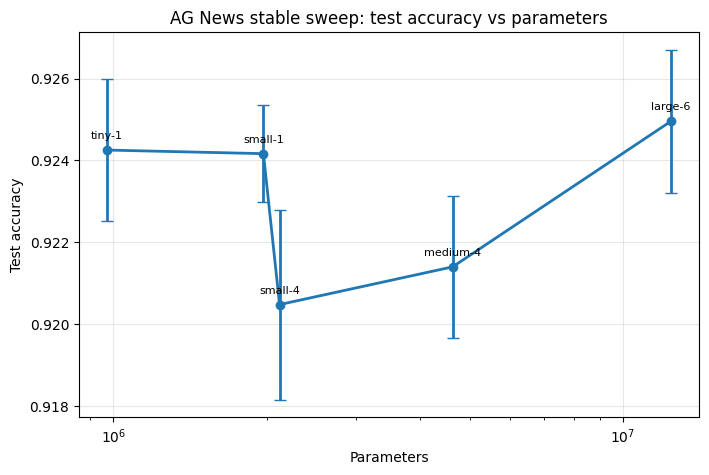

Saved: /content/agnews_final_analysis/agnews_stable_gap_vs_params.png


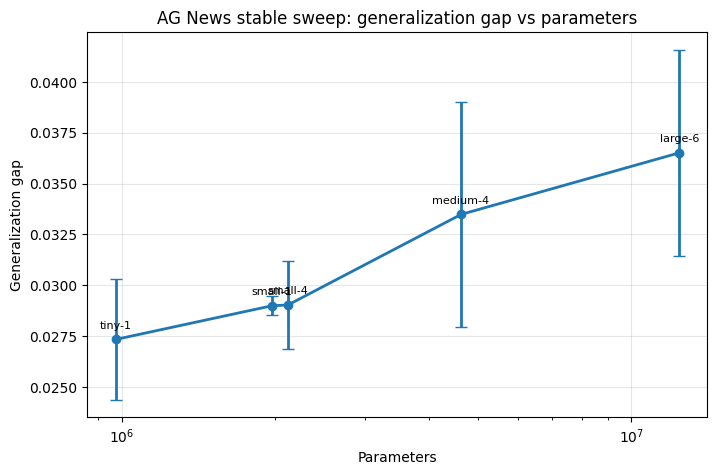

Saved: /content/agnews_final_analysis/agnews_data_size_sweep.png


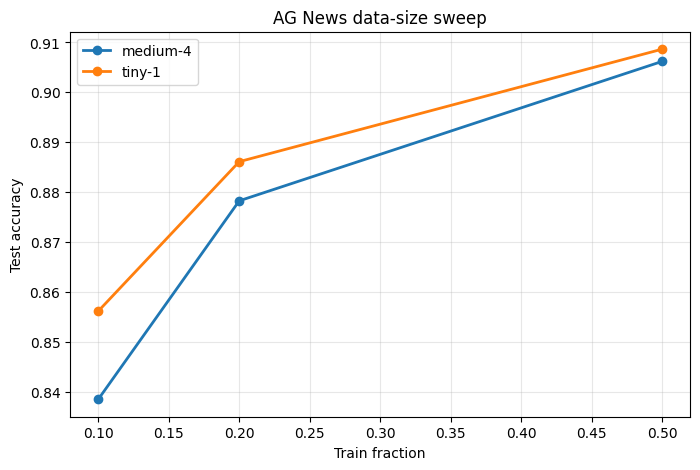

In [ ]:
if not stable_df.empty:
    plt.figure(figsize=(8, 5))

    stable_plot = stable_df.sort_values("num_parameters")
    plt.errorbar(
        stable_plot["num_parameters"],
        stable_plot["test_acc_mean"],
        yerr=stable_plot["test_acc_std"],
        fmt="o-",
        capsize=4,
        linewidth=2,
    )

    for _, row in stable_plot.iterrows():
        plt.annotate(
            row["model_name"],
            (row["num_parameters"], row["test_acc_mean"]),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=8,
        )

    plt.xscale("log")
    plt.title("AG News stable sweep: test accuracy vs parameters")
    plt.xlabel("Parameters")
    plt.ylabel("Test accuracy")
    plt.grid(alpha=0.3)

    save_plot("agnews_stable_accuracy_vs_params.png")
    plt.show()


if not stable_df.empty:
    plt.figure(figsize=(8, 5))

    stable_plot = stable_df.sort_values("num_parameters")
    plt.errorbar(
        stable_plot["num_parameters"],
        stable_plot["gap_mean"],
        yerr=stable_plot["gap_std"],
        fmt="o-",
        capsize=4,
        linewidth=2,
    )

    for _, row in stable_plot.iterrows():
        plt.annotate(
            row["model_name"],
            (row["num_parameters"], row["gap_mean"]),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=8,
        )

    plt.xscale("log")
    plt.title("AG News stable sweep: generalization gap vs parameters")
    plt.xlabel("Parameters")
    plt.ylabel("Generalization gap")
    plt.grid(alpha=0.3)

    save_plot("agnews_stable_gap_vs_params.png")
    plt.show()


if not data_size_df.empty:
    plt.figure(figsize=(8, 5))

    for model_name in sorted(data_size_df["model_name"].unique()):
        sub = data_size_df[data_size_df["model_name"] == model_name].sort_values("train_fraction")
        plt.plot(
            sub["train_fraction"],
            sub["test_acc_mean"],
            marker="o",
            linewidth=2,
            label=model_name,
        )

    plt.title("AG News data-size sweep")
    plt.xlabel("Train fraction")
    plt.ylabel("Test accuracy")
    plt.grid(alpha=0.3)
    plt.legend()

    save_plot("agnews_data_size_sweep.png")
    plt.show()

### Ablation + shift analysis

In [ ]:
ablation_manifest = load_json(ablation_root / "run_manifest.json")

print("ABLATION + SHIFT MANIFEST")
print("=" * 100)
for k, v in ablation_manifest.items():
    print(f"{k:<28}: {v}")

ablation_summary = load_json(ablation_root / "ablation" / "ablation_summary.json")

ablation_rows = []
per_seed_rows = []
shift_rows = []

for block in ablation_summary:
    model_name = block["model_name"]

    for cond in block["conditions"]:
        condition = cond["condition"]

        ablation_rows.append({
            "model_name": model_name,
            "condition": condition,
            "num_parameters": cond["num_parameters"],
            "seeds": cond["seeds"],
            "test_acc_mean": cond["test_acc_stats"]["mean"],
            "test_acc_std": cond["test_acc_stats"]["std"],
            "test_acc_ci95_low": cond["test_acc_stats"]["ci95_low"],
            "test_acc_ci95_high": cond["test_acc_stats"]["ci95_high"],
            "gap_mean": cond["gap_stats"]["mean"],
            "gap_std": cond["gap_stats"]["std"],
            "ece_mean": cond["ece_stats"]["mean"],
            "ece_scaled_mean": cond["ece_scaled_stats"]["mean"],
            "nll_mean": cond["nll_stats"]["mean"],
            "nll_scaled_mean": cond["nll_scaled_stats"]["mean"],
            "brier_mean": cond["brier_stats"]["mean"],
            "brier_scaled_mean": cond["brier_scaled_stats"]["mean"],
            "scheduler_trace_steps_mean": safe_get(cond, ["scheduler_trace_steps_stats", "mean"]),
        })

        for r in cond["per_seed_results"]:
            per_seed_rows.append({
                "model_name": model_name,
                "condition": condition,
                "seed": int(r["seed"]),
                "test_acc": float(r["test_acc"]),
                "test_ece": float(r["test_ece"]),
                "test_nll": float(r["test_nll"]),
                "test_brier": float(r["test_brier"]),
                "test_ece_scaled": float(r["test_ece_scaled"]),
                "test_nll_scaled": float(r["test_nll_scaled"]),
                "test_brier_scaled": float(r["test_brier_scaled"]),
                "generalization_gap_01": float(r["generalization_gap_01"]),
                "scheduler_trace_steps": int(r.get("scheduler_trace_steps", 0)),
                "scheduler_trace_file": r.get("scheduler_trace_file", ""),
            })

        if "shift_summary" in cond:
            clean_acc = cond["test_acc_stats"]["mean"]
            for shift_name, vals in cond["shift_summary"].items():
                shift_rows.append({
                    "model_name": model_name,
                    "condition": condition,
                    "shift_name": shift_name,
                    "clean_acc": clean_acc,
                    "shift_acc": vals["test_acc_stats"]["mean"],
                    "acc_drop": clean_acc - vals["test_acc_stats"]["mean"],
                    "ece": vals["ece_stats"]["mean"],
                    "nll": vals["nll_stats"]["mean"],
                    "brier": vals["brier_stats"]["mean"],
                })

ablation_df = pd.DataFrame(ablation_rows).sort_values(["model_name", "condition"]).reset_index(drop=True)
per_seed_df = pd.DataFrame(per_seed_rows).sort_values(["model_name", "seed", "condition"]).reset_index(drop=True)
shift_df = pd.DataFrame(shift_rows).sort_values(["model_name", "condition", "shift_name"]).reset_index(drop=True)

print("\nAG NEWS ABLATION SUMMARY")
display(ablation_df)

print("\nAG NEWS PER-SEED ABLATION TABLE")
display(per_seed_df)

print("\nAG NEWS SHIFT SUMMARY FOR ALL CONDITIONS")
display(shift_df)

save_table(ablation_df, "agnews_ablation_summary.csv")
save_table(per_seed_df, "agnews_ablation_per_seed.csv")
save_table(shift_df, "agnews_shift_all_conditions.csv")

ABLATION + SHIFT MANIFEST
dataset_name                : ag_news
run_tag                     : agnews_ablation_shift_v1
seeds                       : [42, 123, 456]
run_baselines               : False
run_stable_sweep            : False
run_ablation                : True
run_data_size_sweep         : False
run_shift_eval              : True
model_names_stable          : []
model_names_ablation        : ['medium-4', 'large-6']
ablation_conditions         : ['stable_schedule', 'legacy_warmup_fixed_order', 'legacy_buggy_warmup']
model_names_data_size       : []
train_fractions             : []
shift_configs               : [{'name': 'truncation', 'max_tokens': 32}, {'name': 'unk_corruption', 'rate': 0.2, 'seed': 42}]
max_length                  : 128
batch_size                  : 32
num_epochs                  : 30
early_stopping_patience     : 5

AG NEWS ABLATION SUMMARY


,model_name,condition,num_parameters,seeds,test_acc_mean,test_acc_std,test_acc_ci95_low,test_acc_ci95_high,gap_mean,gap_std,ece_mean,ece_scaled_mean,nll_mean,nll_scaled_mean,brier_mean,brier_scaled_mean,scheduler_trace_steps_mean
0,large-6,legacy_buggy_warmup,12414980,"[42, 123, 456]",0.784693,0.012549,0.770492,0.798894,0.023013,0.001983,0.207656,0.134447,4.547869,2.548640,0.420558,0.358739,92452.000000
1,large-6,legacy_warmup_fixed_order,12414980,"[42, 123, 456]",0.921491,0.004478,0.916424,0.926559,0.034349,0.004381,0.032657,0.009427,0.263342,0.236876,0.123691,0.120777,24441.333333
2,large-6,stable_schedule,12414980,"[42, 123, 456]",0.924956,0.001750,0.922976,0.926936,0.036508,0.005077,0.025916,0.006207,0.243253,0.221407,0.117089,0.114425,29754.666667
3,medium-4,legacy_buggy_warmup,4632068,"[42, 123, 456]",0.720219,0.097459,0.609934,0.830505,0.021372,0.012057,0.182291,0.025041,1.777370,1.223179,0.451713,0.377430,79700.000000
4,medium-4,legacy_warmup_fixed_order,4632068,"[42, 123, 456]",0.927851,0.002384,0.925153,0.930548,0.037113,0.006255,0.029051,0.009095,0.242578,0.220567,0.114307,0.111905,26566.666667
5,medium-4,stable_schedule,4632068,"[42, 123, 456]",0.921404,0.001737,0.919438,0.923369,0.033479,0.005531,0.030136,0.006991,0.251845,0.229571,0.121864,0.119032,35068.000000



AG NEWS PER-SEED ABLATION TABLE


,model_name,condition,seed,test_acc,test_ece,test_nll,test_brier,test_ece_scaled,test_nll_scaled,test_brier_scaled,generalization_gap_01,scheduler_trace_steps,scheduler_trace_file
0,large-6,legacy_buggy_warmup,42,0.774474,0.217842,4.730905,0.441725,0.137354,2.711294,0.372035,0.021183,86076,scheduler_traces/large-6_legacy_buggy_warmup_f...
1,large-6,legacy_warmup_fixed_order,42,0.915526,0.031035,0.273232,0.130286,0.010289,0.251489,0.128179,0.028229,22316,scheduler_traces/large-6_legacy_warmup_fixed_o...
2,large-6,stable_schedule,42,0.926447,0.037218,0.261032,0.117697,0.005620,0.217313,0.112245,0.043092,31880,scheduler_traces/large-6_stable_schedule_frac1...
3,large-6,legacy_buggy_warmup,123,0.802368,0.187172,3.596097,0.380722,0.091353,1.331524,0.302740,0.025769,95640,scheduler_traces/large-6_legacy_buggy_warmup_f...
4,large-6,legacy_warmup_fixed_order,123,0.922632,0.033908,0.256291,0.121396,0.008310,0.229334,0.117779,0.038241,25504,scheduler_traces/large-6_legacy_warmup_fixed_o...
5,large-6,stable_schedule,123,0.925921,0.025573,0.233704,0.115284,0.007100,0.217843,0.113283,0.030736,28692,scheduler_traces/large-6_stable_schedule_frac1...
6,large-6,legacy_buggy_warmup,456,0.777237,0.217953,5.316607,0.439227,0.174635,3.603102,0.401442,0.022087,95640,scheduler_traces/large-6_legacy_buggy_warmup_f...
7,large-6,legacy_warmup_fixed_order,456,0.926316,0.033029,0.260504,0.119391,0.009683,0.229805,0.116373,0.036576,25504,scheduler_traces/large-6_legacy_warmup_fixed_o...
8,large-6,stable_schedule,456,0.922500,0.014958,0.235023,0.118287,0.005900,0.229065,0.117747,0.035696,28692,scheduler_traces/large-6_stable_schedule_frac1...
9,medium-4,legacy_buggy_warmup,42,0.793816,0.109090,0.725320,0.312260,0.019791,0.552335,0.288693,0.030155,95640,scheduler_traces/medium-4_legacy_buggy_warmup_...



AG NEWS SHIFT SUMMARY FOR ALL CONDITIONS


,model_name,condition,shift_name,clean_acc,shift_acc,acc_drop,ece,nll,brier
0,large-6,legacy_buggy_warmup,truncation,0.784693,0.771140,0.013553,0.220489,4.827411,0.445964
1,large-6,legacy_buggy_warmup,unk_corruption,0.784693,0.754298,0.030395,0.237320,5.261310,0.479103
2,large-6,legacy_warmup_fixed_order,truncation,0.921491,0.916184,0.005307,0.034396,0.282963,0.132406
3,large-6,legacy_warmup_fixed_order,unk_corruption,0.921491,0.909254,0.012237,0.035868,0.301229,0.141112
4,large-6,stable_schedule,truncation,0.924956,0.918114,0.006842,0.029284,0.265139,0.127374
5,large-6,stable_schedule,unk_corruption,0.924956,0.910044,0.014912,0.036867,0.291939,0.139208
6,medium-4,legacy_buggy_warmup,truncation,0.720219,0.703728,0.016491,0.193841,1.896012,0.475065
7,medium-4,legacy_buggy_warmup,unk_corruption,0.720219,0.691579,0.028640,0.205281,2.043702,0.500134
8,medium-4,legacy_warmup_fixed_order,truncation,0.927851,0.921579,0.006272,0.030953,0.265067,0.125239
9,medium-4,legacy_warmup_fixed_order,unk_corruption,0.927851,0.915658,0.012193,0.032495,0.277103,0.131405


Saved: /content/agnews_final_analysis/agnews_ablation_summary.csv
Saved: /content/agnews_final_analysis/agnews_ablation_per_seed.csv
Saved: /content/agnews_final_analysis/agnews_shift_all_conditions.csv


### Effect sizes + confidence intervals

In [ ]:
comparisons = [
    ("stable_schedule", "legacy_warmup_fixed_order"),
    ("stable_schedule", "legacy_buggy_warmup"),
    ("legacy_warmup_fixed_order", "legacy_buggy_warmup"),
]

metrics = [
    "test_acc",
    "test_ece",
    "test_nll",
    "generalization_gap_01",
]

effect_rows = []

for model_name in sorted(per_seed_df["model_name"].unique()):
    sub_model = per_seed_df[per_seed_df["model_name"] == model_name].copy()

    for cond_a, cond_b in comparisons:
        a_df = sub_model[sub_model["condition"] == cond_a].copy()
        b_df = sub_model[sub_model["condition"] == cond_b].copy()

        common_seeds = sorted(set(a_df["seed"]) & set(b_df["seed"]))
        if len(common_seeds) == 0:
            continue

        a_df = a_df[a_df["seed"].isin(common_seeds)].sort_values("seed")
        b_df = b_df[b_df["seed"].isin(common_seeds)].sort_values("seed")

        for metric in metrics:
            stats = paired_effect_summary(a_df[metric].values, b_df[metric].values)

            effect_rows.append({
                "model_name": model_name,
                "comparison": f"{cond_a} -> {cond_b}",
                "metric": metric,
                "n_seeds": len(common_seeds),
                "mean_a": float(a_df[metric].mean()),
                "mean_b": float(b_df[metric].mean()),
                "mean_diff_b_minus_a": stats["mean_diff_b_minus_a"],
                "cohens_dz": stats["cohens_dz"],
                "ci95_low": stats["ci95_low"],
                "ci95_high": stats["ci95_high"],
            })

effect_df = pd.DataFrame(effect_rows)

print("AG NEWS EFFECT SIZE + CI TABLE")
display(effect_df)

save_table(effect_df, "agnews_effect_sizes_ci.csv")

AG NEWS EFFECT SIZE + CI TABLE


,model_name,comparison,metric,n_seeds,mean_a,mean_b,mean_diff_b_minus_a,cohens_dz,ci95_low,ci95_high
0,large-6,stable_schedule -> legacy_warmup_fixed_order,test_acc,3,0.924956,0.921491,-0.003465,-0.470138,-0.010274,0.003345
1,large-6,stable_schedule -> legacy_warmup_fixed_order,test_ece,3,0.025916,0.032657,0.006741,0.552289,-0.004536,0.018018
2,large-6,stable_schedule -> legacy_warmup_fixed_order,test_nll,3,0.243253,0.263342,0.020090,2.876509,0.013637,0.026542
3,large-6,stable_schedule -> legacy_warmup_fixed_order,generalization_gap_01,3,0.036508,0.034349,-0.002159,-0.187929,-0.012775,0.008457
4,large-6,stable_schedule -> legacy_buggy_warmup,test_acc,3,0.924956,0.784693,-0.140263,-9.441766,-0.153989,-0.126537
5,large-6,stable_schedule -> legacy_buggy_warmup,test_ece,3,0.025916,0.207656,0.181739,8.771150,0.162595,0.200884
6,large-6,stable_schedule -> legacy_buggy_warmup,test_nll,3,0.243253,4.547869,4.304617,4.939727,3.499458,5.109775
7,large-6,stable_schedule -> legacy_buggy_warmup,generalization_gap_01,3,0.036508,0.023013,-0.013495,-1.593004,-0.021322,-0.005668
8,large-6,legacy_warmup_fixed_order -> legacy_buggy_warmup,test_acc,3,0.921491,0.784693,-0.136798,-9.198669,-0.150539,-0.123058
9,large-6,legacy_warmup_fixed_order -> legacy_buggy_warmup,test_ece,3,0.032657,0.207656,0.174999,9.285824,0.157586,0.192411


Saved: /content/agnews_final_analysis/agnews_effect_sizes_ci.csv


### Paired per-seed plots

Saved: /content/agnews_final_analysis/agnews_paired_per_seed_large-6.png


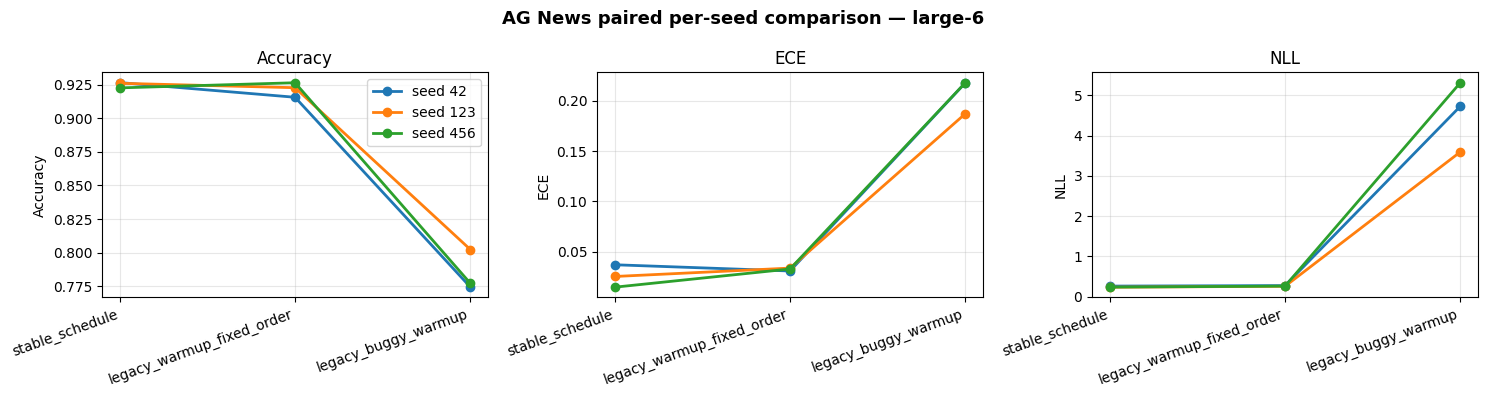

Saved: /content/agnews_final_analysis/agnews_paired_per_seed_medium-4.png


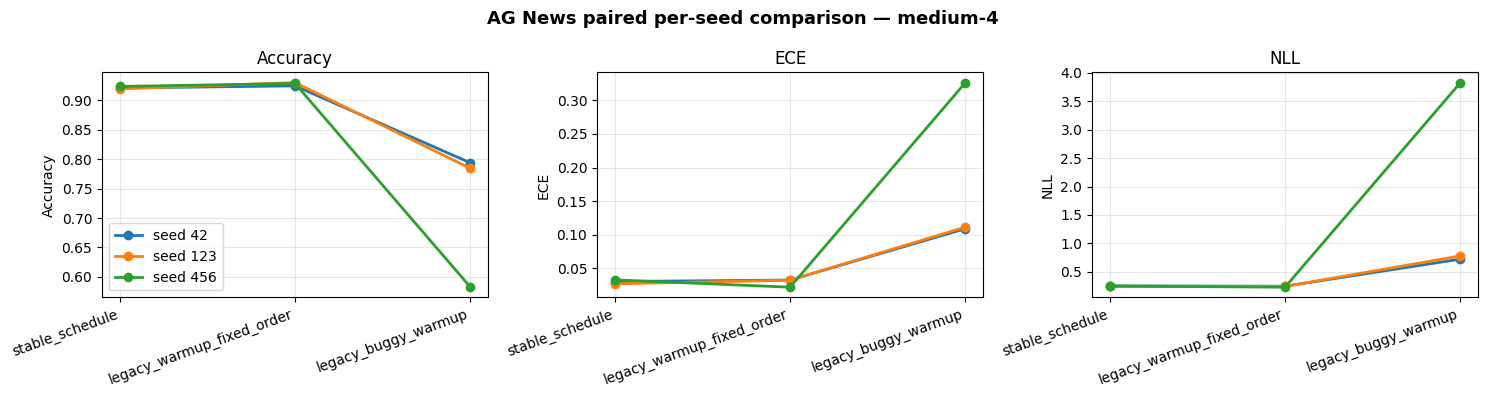

In [ ]:
plot_metrics = [
    ("test_acc", "Accuracy"),
    ("test_ece", "ECE"),
    ("test_nll", "NLL"),
]

condition_order = [
    "stable_schedule",
    "legacy_warmup_fixed_order",
    "legacy_buggy_warmup",
]

for model_name in sorted(per_seed_df["model_name"].unique()):
    sub_model = per_seed_df[per_seed_df["model_name"] == model_name].copy()
    seeds = sorted(sub_model["seed"].unique())

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"AG News paired per-seed comparison — {model_name}", fontsize=13, fontweight="bold")

    for ax, (metric, ylabel) in zip(axes, plot_metrics):
        pivot = sub_model.pivot(index="seed", columns="condition", values=metric).reindex(index=seeds)
        x = np.arange(len(condition_order))

        for seed in seeds:
            y = [pivot.loc[seed, c] if c in pivot.columns else np.nan for c in condition_order]
            ax.plot(x, y, marker="o", linewidth=2, label=f"seed {seed}")

        ax.set_xticks(x)
        ax.set_xticklabels(condition_order, rotation=20, ha="right")
        ax.set_ylabel(ylabel)
        ax.set_title(ylabel)
        ax.grid(alpha=0.3)

    axes[0].legend()
    plt.tight_layout()

    save_plot(f"agnews_paired_per_seed_{model_name}.png")
    plt.show()

### Scheduler trace analysis

In [ ]:
trace_rows = []
first_steps_rows = []

trace_dir = ablation_root / "scheduler_traces"

if not trace_dir.exists():
    raise FileNotFoundError(f"Scheduler trace folder not found: {trace_dir}")

for _, row in per_seed_df.iterrows():
    rel_file = row["scheduler_trace_file"]
    trace_path = ablation_root / rel_file

    if not trace_path.exists():
        possible = list(trace_dir.glob(f"*{row['model_name']}*{row['condition']}*seed{row['seed']}*.json"))
        if possible:
            trace_path = possible[0]

    if not trace_path.exists():
        trace_rows.append({
            "model_name": row["model_name"],
            "condition": row["condition"],
            "seed": row["seed"],
            "trace_found": False,
        })
        continue

    trace = load_json(trace_path)

    if len(trace) == 0:
        trace_rows.append({
            "model_name": row["model_name"],
            "condition": row["condition"],
            "seed": row["seed"],
            "trace_found": True,
            "num_steps": 0,
        })
        continue

    lr_used = np.array([x["lr_used"] for x in trace], dtype=np.float64)
    lr_before = np.array([x["lr_before_step"] for x in trace], dtype=np.float64)
    lr_after = np.array([x["lr_after_step"] for x in trace], dtype=np.float64)

    trace_rows.append({
        "model_name": row["model_name"],
        "condition": row["condition"],
        "seed": row["seed"],
        "trace_found": True,
        "num_steps": len(trace),
        "first_lr_before_step": float(lr_before[0]),
        "first_lr_used": float(lr_used[0]),
        "first_lr_after_step": float(lr_after[0]),
        "max_lr_used_first50": float(np.max(lr_used[:min(50, len(lr_used))])),
        "max_lr_used_all": float(np.max(lr_used)),
        "last_lr_used": float(lr_used[-1]),
        "trace_file": str(trace_path),
    })

    for x in trace[:5]:
        first_steps_rows.append({
            "model_name": row["model_name"],
            "condition": row["condition"],
            "seed": row["seed"],
            "step": x["step"],
            "lr_before_step": x["lr_before_step"],
            "lr_used": x["lr_used"],
            "lr_after_step": x["lr_after_step"],
        })

scheduler_summary_df = pd.DataFrame(trace_rows).sort_values(["model_name", "condition", "seed"]).reset_index(drop=True)
scheduler_first_steps_df = pd.DataFrame(first_steps_rows).sort_values(["model_name", "condition", "seed", "step"]).reset_index(drop=True)

print("AG NEWS SCHEDULER TRACE SUMMARY")
display(scheduler_summary_df)

print("\nAG NEWS FIRST 5 SCHEDULER STEPS")
display(scheduler_first_steps_df)

save_table(scheduler_summary_df, "agnews_scheduler_trace_summary.csv")
save_table(scheduler_first_steps_df, "agnews_scheduler_first_5_steps.csv")

AG NEWS SCHEDULER TRACE SUMMARY


,model_name,condition,seed,trace_found,num_steps,first_lr_before_step,first_lr_used,first_lr_after_step,max_lr_used_first50,max_lr_used_all,last_lr_used,trace_file
0,large-6,legacy_buggy_warmup,42,True,86076,1.0000,1.000000e+00,2.470529e-07,1.000000e+00,1.000000,0.000213,/content/prof_agnews_outputs/results_agnewa-no...
1,large-6,legacy_buggy_warmup,123,True,95640,1.0000,1.000000e+00,2.470529e-07,1.000000e+00,1.000000,0.000202,/content/prof_agnews_outputs/results_agnewa-no...
2,large-6,legacy_buggy_warmup,456,True,95640,1.0000,1.000000e+00,2.470529e-07,1.000000e+00,1.000000,0.000202,/content/prof_agnews_outputs/results_agnewa-no...
3,large-6,legacy_warmup_fixed_order,42,True,22316,1.0000,2.470529e-07,2.470529e-07,1.235265e-05,0.000988,0.000418,/content/prof_agnews_outputs/results_agnewa-no...
4,large-6,legacy_warmup_fixed_order,123,True,25504,1.0000,2.470529e-07,2.470529e-07,1.235265e-05,0.000988,0.000391,/content/prof_agnews_outputs/results_agnewa-no...
5,large-6,legacy_warmup_fixed_order,456,True,25504,1.0000,2.470529e-07,2.470529e-07,1.235265e-05,0.000988,0.000391,/content/prof_agnews_outputs/results_agnewa-no...
6,large-6,stable_schedule,42,True,31880,0.0001,1.250000e-08,1.250000e-08,6.250000e-07,0.000100,0.000083,/content/prof_agnews_outputs/results_agnewa-no...
7,large-6,stable_schedule,123,True,28692,0.0001,1.250000e-08,1.250000e-08,6.250000e-07,0.000100,0.000087,/content/prof_agnews_outputs/results_agnewa-no...
8,large-6,stable_schedule,456,True,28692,0.0001,1.250000e-08,1.250000e-08,6.250000e-07,0.000100,0.000087,/content/prof_agnews_outputs/results_agnewa-no...
9,medium-4,legacy_buggy_warmup,42,True,95640,1.0000,1.000000e+00,3.493856e-07,1.000000e+00,1.000000,0.000286,/content/prof_agnews_outputs/results_agnewa-no...



AG NEWS FIRST 5 SCHEDULER STEPS


,model_name,condition,seed,step,lr_before_step,lr_used,lr_after_step
0,large-6,legacy_buggy_warmup,42,1,1.000000e+00,1.000000e+00,2.470529e-07
1,large-6,legacy_buggy_warmup,42,2,2.470529e-07,2.470529e-07,4.941059e-07
2,large-6,legacy_buggy_warmup,42,3,4.941059e-07,4.941059e-07,7.411588e-07
3,large-6,legacy_buggy_warmup,42,4,7.411588e-07,7.411588e-07,9.882118e-07
4,large-6,legacy_buggy_warmup,42,5,9.882118e-07,9.882118e-07,1.235265e-06
...,...,...,...,...,...,...,...
85,medium-4,stable_schedule,456,1,1.000000e-04,1.250000e-08,1.250000e-08
86,medium-4,stable_schedule,456,2,1.250000e-08,2.500000e-08,2.500000e-08
87,medium-4,stable_schedule,456,3,2.500000e-08,3.750000e-08,3.750000e-08
88,medium-4,stable_schedule,456,4,3.750000e-08,5.000000e-08,5.000000e-08


Saved: /content/agnews_final_analysis/agnews_scheduler_trace_summary.csv
Saved: /content/agnews_final_analysis/agnews_scheduler_first_5_steps.csv


### Scheduler trace plots

Saved: /content/agnews_final_analysis/agnews_scheduler_trace_first100_large-6.png


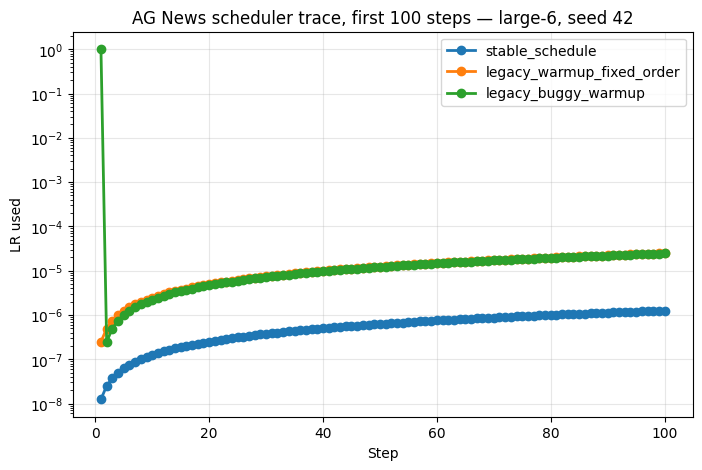

Saved: /content/agnews_final_analysis/agnews_scheduler_trace_first100_medium-4.png


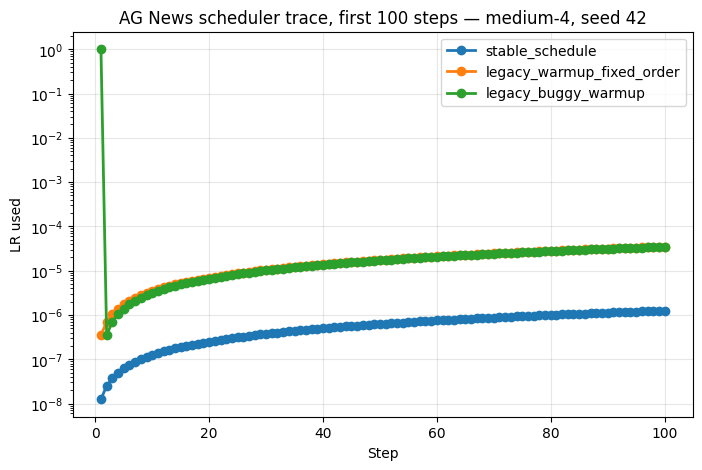

In [ ]:
for model_name in sorted(per_seed_df["model_name"].unique()):
    plt.figure(figsize=(8, 5))

    for condition in condition_order:
        sub = scheduler_summary_df[
            (scheduler_summary_df["model_name"] == model_name) &
            (scheduler_summary_df["condition"] == condition) &
            (scheduler_summary_df["seed"] == 42) &
            (scheduler_summary_df["trace_found"] == True)
        ]

        if sub.empty:
            continue

        trace_path = Path(sub.iloc[0]["trace_file"])
        trace = load_json(trace_path)
        trace_df = pd.DataFrame(trace).head(100)

        plt.plot(
            trace_df["step"],
            trace_df["lr_used"],
            marker="o",
            linewidth=2,
            label=condition,
        )

    plt.title(f"AG News scheduler trace, first 100 steps — {model_name}, seed 42")
    plt.xlabel("Step")
    plt.ylabel("LR used")
    plt.yscale("log")
    plt.grid(alpha=0.3)
    plt.legend()

    save_plot(f"agnews_scheduler_trace_first100_{model_name}.png")
    plt.show()

### Early diagnostics: load all runs

In [ ]:
earlydiag_manifest = load_json(earlydiag_root / "run_manifest.json")
all_runs = load_json(earlydiag_root / "all_runs.json")

print("EARLY DIAGNOSTICS MANIFEST")
print("=" * 100)
for k, v in earlydiag_manifest.items():
    print(f"{k:<28}: {v}")

print("\nNumber of early diagnostic runs:", len(all_runs))

EARLY DIAGNOSTICS MANIFEST
dataset_name                : ag_news
run_tag                     : agnews_earlydiag_plus_v1
seeds                       : [42, 123, 456]
model_names                 : ['medium-4', 'large-6']
conditions                  : ['stable_schedule', 'legacy_warmup_fixed_order', 'legacy_buggy_warmup']
train_fraction              : 1.0
max_length                  : 128
batch_size                  : 32
diagnostic_steps            : 300
max_epochs_for_diagnostic   : 3
representation_eval_every   : 10

Number of early diagnostic runs: 18


### Early diagnostics: 50 / 100 / 300 window summaries

In [ ]:
def build_window_summary_from_logs(logs, step_limit):
    sub = logs[:min(step_limit, len(logs))]
    if len(sub) == 0:
        return {}

    layer_names = sorted({
        layer_name
        for x in sub
        for layer_name in x["layer_update_to_param_ratio"].keys()
    })

    layer_max = {}
    for layer_name in layer_names:
        vals = [x["layer_update_to_param_ratio"].get(layer_name, np.nan) for x in sub]
        vals = [v for v in vals if not np.isnan(v)]
        if vals:
            layer_max[layer_name] = float(max(vals))

    repr_rows = [x for x in sub if x["repr_drift_l2"] is not None]

    emb_vals = [x["layer_update_to_param_ratio"].get("embedding", np.nan) for x in sub]
    emb_vals = [v for v in emb_vals if not np.isnan(v)]

    cls_vals = [x["layer_update_to_param_ratio"].get("classifier", np.nan) for x in sub]
    cls_vals = [v for v in cls_vals if not np.isnan(v)]

    return {
        "steps_included": int(len(sub)),
        "loss_step1": float(sub[0]["loss"]),
        "max_loss": float(max(x["loss"] for x in sub)),
        "max_grad_norm": float(max(x["grad_norm"] for x in sub)),
        "max_update_ratio": float(max(x["update_to_param_ratio"] for x in sub)),
        "max_embedding_update_ratio": float(max(emb_vals)) if emb_vals else np.nan,
        "max_classifier_update_ratio": float(max(cls_vals)) if cls_vals else np.nan,
        "mean_confidence_first10_within_window": float(np.mean([x["mean_confidence"] for x in sub[:min(10, len(sub))]])),
        "last_repr_drift_l2": float(repr_rows[-1]["repr_drift_l2"]) if repr_rows else np.nan,
        "last_repr_cos_to_init": float(repr_rows[-1]["repr_cos_to_init"]) if repr_rows else np.nan,
        "last_lr_before_step": float(sub[-1]["lr_before_step"]),
        "last_lr_used": float(sub[-1]["lr_used"]),
        "last_lr_after_step": float(sub[-1]["lr_after_step"]),
        "max_layer_update_ratio": layer_max,
    }


window_rows = []
layer_rows = []

for run in all_runs:
    logs = run["logs"]

    for window in [50, 100, 300]:
        if f"early_summary_{window}" in run and run[f"early_summary_{window}"]:
            summ = run[f"early_summary_{window}"]
        else:
            summ = build_window_summary_from_logs(logs, window)

        if not summ:
            continue

        window_rows.append({
            "model_name": run["model_name"],
            "condition": run["condition"],
            "seed": int(run["seed"]),
            "window": window,
            "steps_included": summ.get("steps_included", np.nan),
            "loss_step1": summ.get("loss_step1", np.nan),
            "max_loss": summ.get("max_loss", np.nan),
            "max_grad_norm": summ.get("max_grad_norm", np.nan),
            "max_update_ratio": summ.get("max_update_ratio", np.nan),
            "max_embedding_update_ratio": summ.get("max_embedding_update_ratio", np.nan),
            "max_classifier_update_ratio": summ.get("max_classifier_update_ratio", np.nan),
            "mean_confidence_first10_within_window": summ.get("mean_confidence_first10_within_window", np.nan),
            "last_repr_drift_l2": summ.get("last_repr_drift_l2", np.nan),
            "last_repr_cos_to_init": summ.get("last_repr_cos_to_init", np.nan),
            "last_lr_before_step": summ.get("last_lr_before_step", np.nan),
            "last_lr_used": summ.get("last_lr_used", np.nan),
            "last_lr_after_step": summ.get("last_lr_after_step", np.nan),
        })

        layer_dict = summ.get("max_layer_update_ratio", {})
        for layer_name, val in layer_dict.items():
            layer_rows.append({
                "model_name": run["model_name"],
                "condition": run["condition"],
                "seed": int(run["seed"]),
                "window": window,
                "layer_name": layer_name,
                "max_layer_update_ratio": val,
            })

window_df = pd.DataFrame(window_rows).sort_values(["model_name", "condition", "seed", "window"]).reset_index(drop=True)
layer_df = pd.DataFrame(layer_rows).sort_values(["model_name", "condition", "seed", "window", "layer_name"]).reset_index(drop=True)

print("AG NEWS EARLY WINDOW SUMMARY")
display(window_df)

print("\nAG NEWS LAYERWISE WINDOW SUMMARY")
display(layer_df)

save_table(window_df, "agnews_early_window_summary_50_100_300.csv")
save_table(layer_df, "agnews_layerwise_window_summary_50_100_300.csv")

AG NEWS EARLY WINDOW SUMMARY


,model_name,condition,seed,window,steps_included,loss_step1,max_loss,max_grad_norm,max_update_ratio,max_embedding_update_ratio,max_classifier_update_ratio,mean_confidence_first10_within_window,last_repr_drift_l2,last_repr_cos_to_init,last_lr_before_step,last_lr_used,last_lr_after_step
0,large-6,legacy_buggy_warmup,42,50,50,1.680919,1.914720e+06,4.308805e+06,10.992141,2.277543e+00,11.180585,0.956441,1.168269e+06,-0.036531,1.210559e-05,1.210559e-05,1.235265e-05
1,large-6,legacy_buggy_warmup,42,100,100,1.680919,1.914720e+06,5.357868e+06,10.992141,2.277543e+00,11.180585,0.956441,1.118944e+06,-0.036014,2.445824e-05,2.445824e-05,2.470529e-05
2,large-6,legacy_buggy_warmup,42,300,300,1.680919,1.914720e+06,5.357868e+06,10.992141,2.277543e+00,11.180585,0.956441,6.083665e+05,-0.025466,7.386883e-05,7.386883e-05,7.411588e-05
3,large-6,legacy_buggy_warmup,123,50,50,2.259355,1.109829e+06,2.466881e+06,10.998598,2.330760e+00,11.136369,0.961279,1.109076e+06,-0.087864,1.210559e-05,1.210559e-05,1.235265e-05
4,large-6,legacy_buggy_warmup,123,100,100,2.259355,1.109829e+06,2.466881e+06,10.998598,2.330760e+00,11.136369,0.961279,1.057903e+06,-0.088881,2.445824e-05,2.445824e-05,2.470529e-05
5,large-6,legacy_buggy_warmup,123,300,300,2.259355,1.109829e+06,2.466881e+06,10.998598,2.330760e+00,11.136369,0.961279,6.000639e+05,-0.091324,7.386883e-05,7.386883e-05,7.411588e-05
6,large-6,legacy_buggy_warmup,456,50,50,1.658794,9.516772e+05,1.382597e+06,10.999324,2.317455e+00,11.256695,0.955739,1.035299e+06,-0.052930,1.210559e-05,1.210559e-05,1.235265e-05
7,large-6,legacy_buggy_warmup,456,100,100,1.658794,9.516772e+05,1.382597e+06,10.999324,2.317455e+00,11.256695,0.955739,9.948888e+05,-0.053280,2.445824e-05,2.445824e-05,2.470529e-05
8,large-6,legacy_buggy_warmup,456,300,300,1.658794,9.516772e+05,4.623158e+06,10.999324,2.317455e+00,11.256695,0.955739,6.269771e+05,-0.060503,7.386883e-05,7.386883e-05,7.411588e-05
9,large-6,legacy_warmup_fixed_order,42,50,50,1.680919,2.139004e+00,2.241089e+01,0.000040,2.466854e-05,0.000037,0.553848,1.390475e+00,0.993632,1.210559e-05,1.235265e-05,1.235265e-05



AG NEWS LAYERWISE WINDOW SUMMARY


,model_name,condition,seed,window,layer_name,max_layer_update_ratio
0,large-6,legacy_buggy_warmup,42,50,classifier,11.180585
1,large-6,legacy_buggy_warmup,42,50,embedding,2.277543
2,large-6,legacy_buggy_warmup,42,50,layer_0,21.281466
3,large-6,legacy_buggy_warmup,42,50,layer_1,21.247003
4,large-6,legacy_buggy_warmup,42,50,layer_2,21.263691
...,...,...,...,...,...,...
373,medium-4,stable_schedule,456,300,embedding,0.000006
374,medium-4,stable_schedule,456,300,layer_0,0.000019
375,medium-4,stable_schedule,456,300,layer_1,0.000019
376,medium-4,stable_schedule,456,300,layer_2,0.000019


Saved: /content/agnews_final_analysis/agnews_early_window_summary_50_100_300.csv
Saved: /content/agnews_final_analysis/agnews_layerwise_window_summary_50_100_300.csv


### Early diagnostics aggregate CI table

In [ ]:
agg_rows = []

early_metrics = [
    "max_loss",
    "max_grad_norm",
    "max_update_ratio",
    "max_embedding_update_ratio",
    "max_classifier_update_ratio",
    "mean_confidence_first10_within_window",
    "last_repr_drift_l2",
    "last_repr_cos_to_init",
    "last_lr_used",
]

for (model_name, condition, window), sub in window_df.groupby(["model_name", "condition", "window"]):
    for metric in early_metrics:
        ci = mean_ci95_from_values(sub[metric].values)
        agg_rows.append({
            "model_name": model_name,
            "condition": condition,
            "window": window,
            "metric": metric,
            "mean": ci["mean"],
            "std": ci["std"],
            "ci95_low": ci["ci95_low"],
            "ci95_high": ci["ci95_high"],
            "n": ci["n"],
        })

window_agg_df = pd.DataFrame(agg_rows)

print("AG NEWS EARLY WINDOW AGGREGATE CI TABLE")
display(window_agg_df)

save_table(window_agg_df, "agnews_early_window_aggregate_ci.csv")

AG NEWS EARLY WINDOW AGGREGATE CI TABLE


,model_name,condition,window,metric,mean,std,ci95_low,ci95_high,n
0,large-6,legacy_buggy_warmup,50,max_loss,1.325409e+06,4.216784e+05,8.482348e+05,1.802583e+06,3
1,large-6,legacy_buggy_warmup,50,max_grad_norm,2.719428e+06,1.207893e+06,1.352568e+06,4.086287e+06,3
2,large-6,legacy_buggy_warmup,50,max_update_ratio,1.099669e+01,3.228926e-03,1.099303e+01,1.100034e+01,3
3,large-6,legacy_buggy_warmup,50,max_embedding_update_ratio,2.308586e+00,2.261277e-02,2.282998e+00,2.334175e+00,3
4,large-6,legacy_buggy_warmup,50,max_classifier_update_ratio,1.119122e+01,4.969472e-02,1.113498e+01,1.124745e+01,3
...,...,...,...,...,...,...,...,...,...
157,medium-4,stable_schedule,300,max_classifier_update_ratio,9.801998e-06,5.587410e-07,9.169724e-06,1.043427e-05,3
158,medium-4,stable_schedule,300,mean_confidence_first10_within_window,4.666912e-01,3.406872e-02,4.281388e-01,5.052436e-01,3
159,medium-4,stable_schedule,300,last_repr_drift_l2,9.582938e-01,2.030419e-01,7.285303e-01,1.188057e+00,3
160,medium-4,stable_schedule,300,last_repr_cos_to_init,9.930705e-01,2.983654e-03,9.896942e-01,9.964468e-01,3


Saved: /content/agnews_final_analysis/agnews_early_window_aggregate_ci.csv


### Early diagnostics plots

Saved: /content/agnews_final_analysis/agnews_early_max_update_ratio_large-6.png


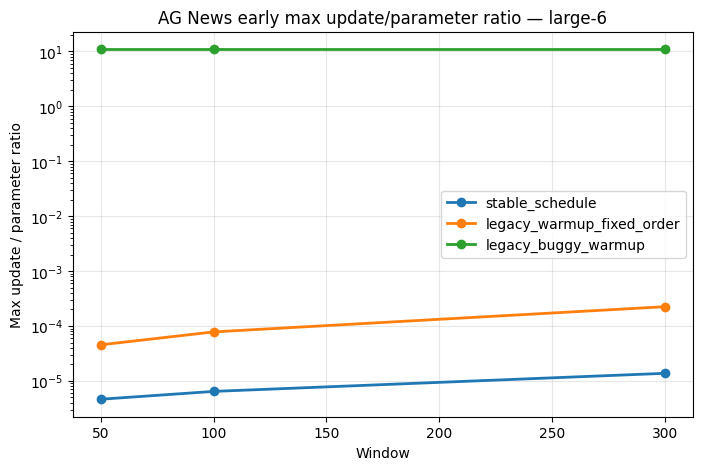

Saved: /content/agnews_final_analysis/agnews_early_max_update_ratio_medium-4.png


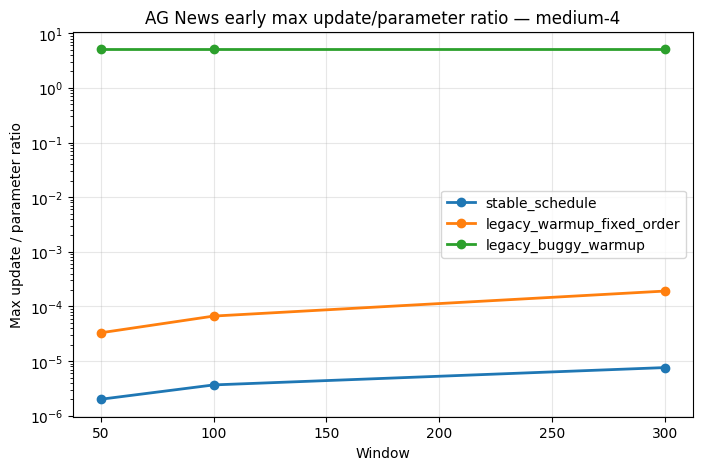

Saved: /content/agnews_final_analysis/agnews_early_max_grad_norm_large-6.png


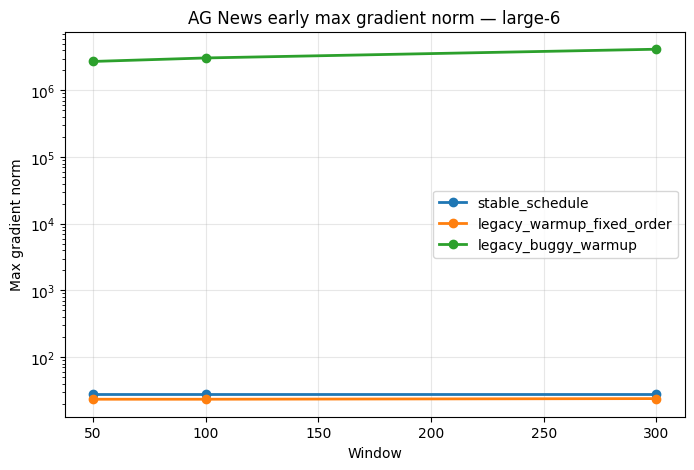

Saved: /content/agnews_final_analysis/agnews_early_max_grad_norm_medium-4.png


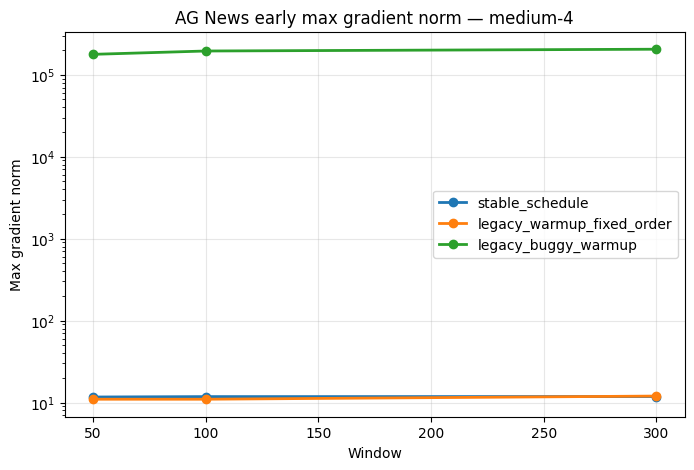

In [ ]:
for model_name in sorted(window_df["model_name"].unique()):
    sub = window_df[window_df["model_name"] == model_name].copy()

    plt.figure(figsize=(8, 5))

    for condition in condition_order:
        s = (
            sub[sub["condition"] == condition]
            .groupby("window")["max_update_ratio"]
            .mean()
            .reset_index()
        )

        if s.empty:
            continue

        plt.plot(
            s["window"],
            s["max_update_ratio"],
            marker="o",
            linewidth=2,
            label=condition,
        )

    plt.title(f"AG News early max update/parameter ratio — {model_name}")
    plt.xlabel("Window")
    plt.ylabel("Max update / parameter ratio")
    plt.yscale("log")
    plt.grid(alpha=0.3)
    plt.legend()

    save_plot(f"agnews_early_max_update_ratio_{model_name}.png")
    plt.show()


for model_name in sorted(window_df["model_name"].unique()):
    sub = window_df[window_df["model_name"] == model_name].copy()

    plt.figure(figsize=(8, 5))

    for condition in condition_order:
        s = (
            sub[sub["condition"] == condition]
            .groupby("window")["max_grad_norm"]
            .mean()
            .reset_index()
        )

        if s.empty:
            continue

        plt.plot(
            s["window"],
            s["max_grad_norm"],
            marker="o",
            linewidth=2,
            label=condition,
        )

    plt.title(f"AG News early max gradient norm — {model_name}")
    plt.xlabel("Window")
    plt.ylabel("Max gradient norm")
    plt.yscale("log")
    plt.grid(alpha=0.3)
    plt.legend()

    save_plot(f"agnews_early_max_grad_norm_{model_name}.png")
    plt.show()

### Early diagnostic traces for seed 42

Saved: /content/agnews_final_analysis/agnews_earlydiag_trace_seed42_large-6.png


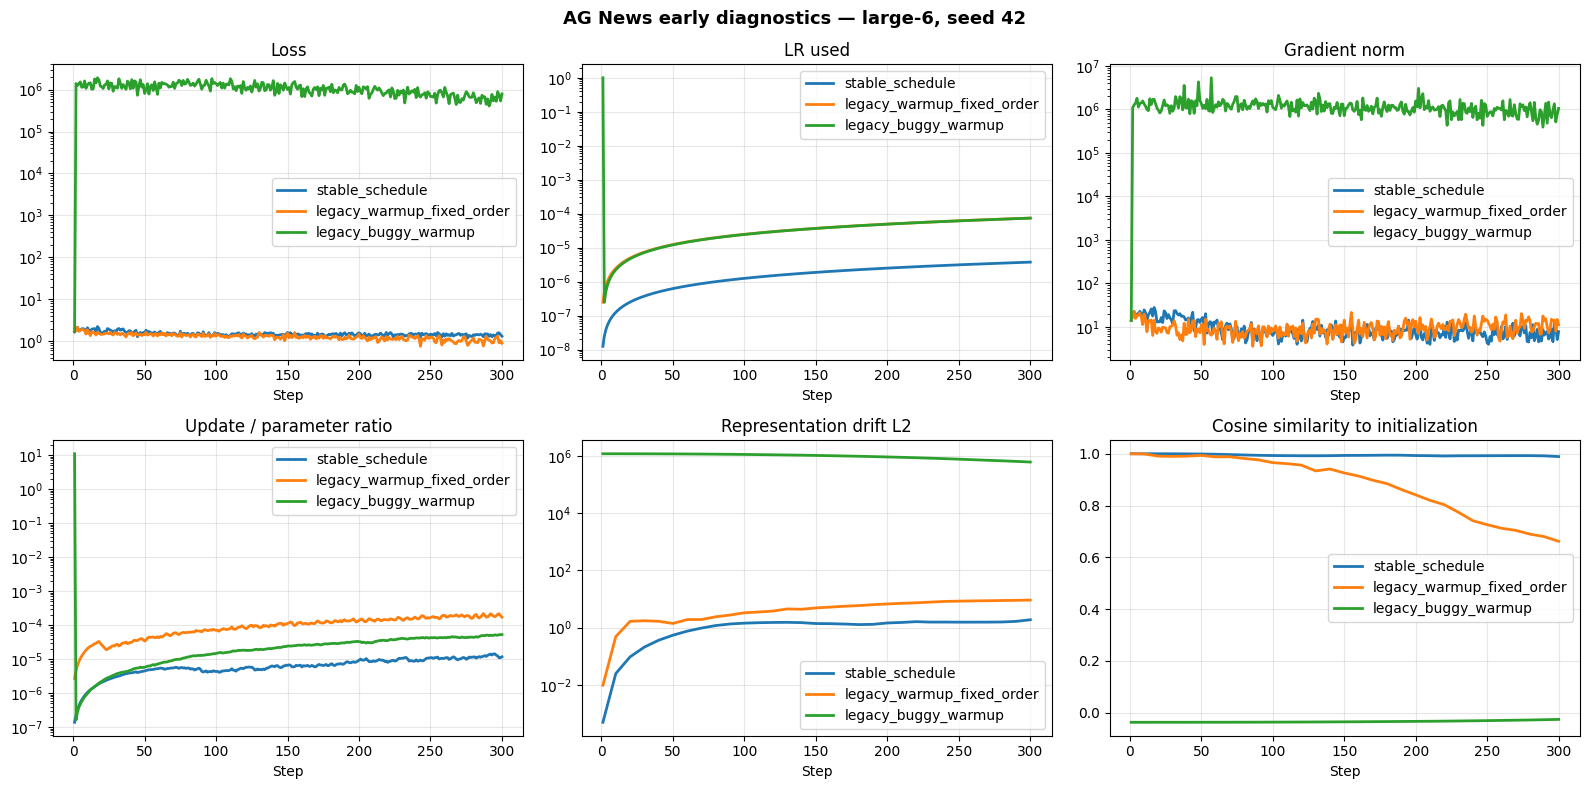

Saved: /content/agnews_final_analysis/agnews_earlydiag_trace_seed42_medium-4.png


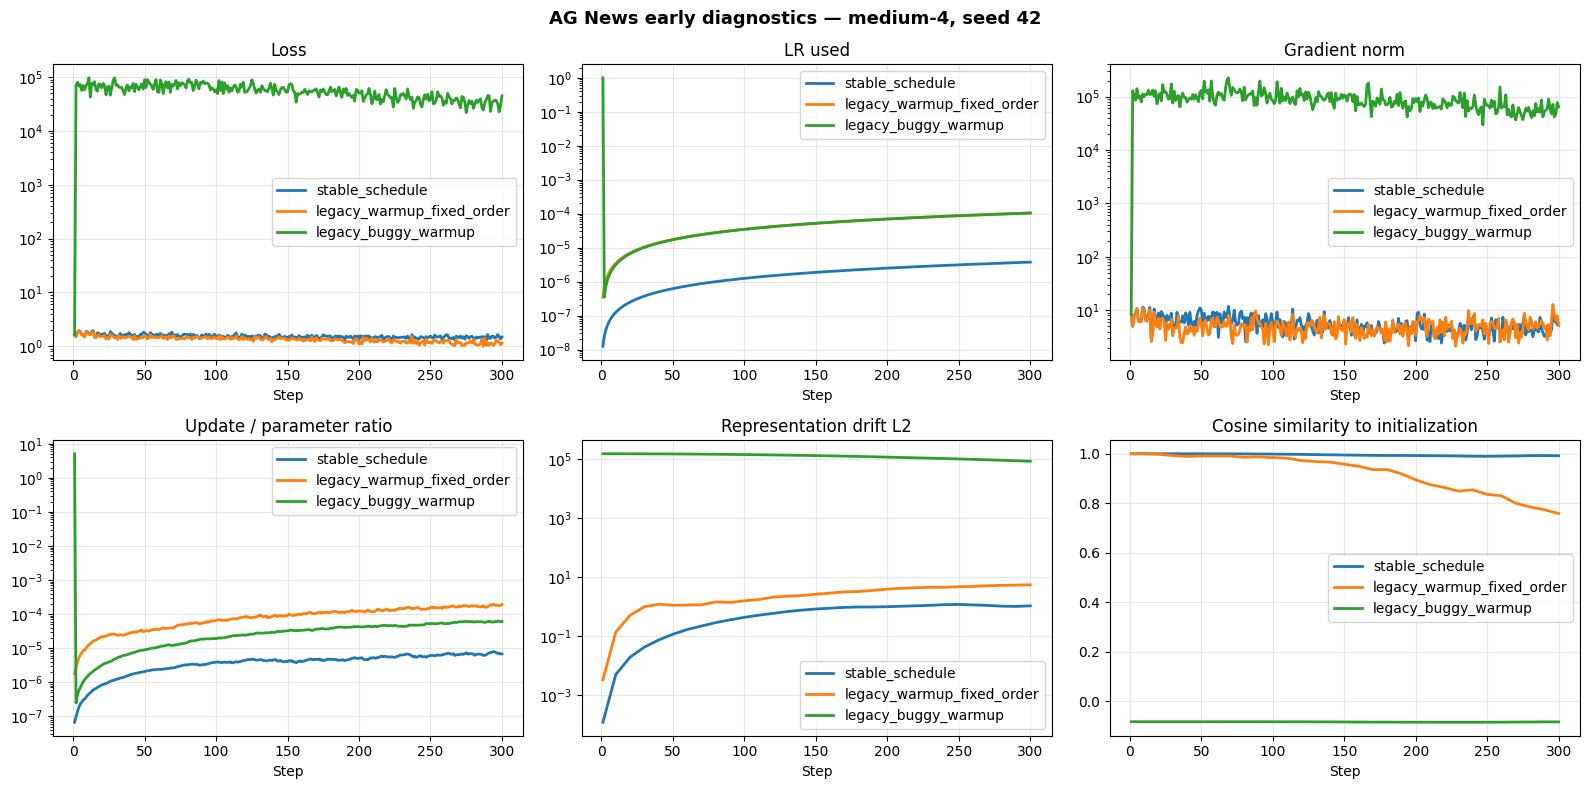

In [ ]:
for model_name in sorted(window_df["model_name"].unique()):
    subset_runs = [
        r for r in all_runs
        if r["model_name"] == model_name and int(r["seed"]) == 42
    ]

    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    fig.suptitle(f"AG News early diagnostics — {model_name}, seed 42", fontsize=13, fontweight="bold")

    for run in subset_runs:
        condition = run["condition"]
        log_df = pd.DataFrame(run["logs"])

        axes[0, 0].plot(log_df["step"], log_df["loss"], label=condition, linewidth=2)
        axes[0, 1].plot(log_df["step"], log_df["lr_used"], label=condition, linewidth=2)
        axes[0, 2].plot(log_df["step"], log_df["grad_norm"], label=condition, linewidth=2)
        axes[1, 0].plot(log_df["step"], log_df["update_to_param_ratio"], label=condition, linewidth=2)

        rep_df = log_df[log_df["repr_drift_l2"].notna()].copy()
        axes[1, 1].plot(rep_df["step"], rep_df["repr_drift_l2"], label=condition, linewidth=2)
        axes[1, 2].plot(rep_df["step"], rep_df["repr_cos_to_init"], label=condition, linewidth=2)

    axes[0, 0].set_title("Loss")
    axes[0, 0].set_yscale("log")

    axes[0, 1].set_title("LR used")
    axes[0, 1].set_yscale("log")

    axes[0, 2].set_title("Gradient norm")
    axes[0, 2].set_yscale("log")

    axes[1, 0].set_title("Update / parameter ratio")
    axes[1, 0].set_yscale("log")

    axes[1, 1].set_title("Representation drift L2")
    axes[1, 1].set_yscale("log")

    axes[1, 2].set_title("Cosine similarity to initialization")

    for ax in axes.ravel():
        ax.set_xlabel("Step")
        ax.grid(alpha=0.3)
        ax.legend()

    plt.tight_layout()

    save_plot(f"agnews_earlydiag_trace_seed42_{model_name}.png")
    plt.show()

### Initial-LR causal sweep analysis

In [ ]:
initial_lr_manifest = load_json(initial_lr_root / "run_manifest.json")
initial_lr_summary = load_json(initial_lr_root / "initial_lr_sweep_summary.json")

print("INITIAL-LR SWEEP MANIFEST")
print("=" * 100)
for k, v in initial_lr_manifest.items():
    print(f"{k:<28}: {v}")

initial_lr_rows = []
initial_lr_per_seed_rows = []

for block in initial_lr_summary:
    model_name = block["model_name"]

    for lr_block in block["initial_lr_blocks"]:
        initial_lr = lr_block["initial_lr"]

        initial_lr_rows.append({
            "model_name": model_name,
            "condition": lr_block["condition"],
            "initial_lr": initial_lr,
            "num_parameters": lr_block["num_parameters"],
            "seeds": lr_block["seeds"],
            "test_acc_mean": lr_block["test_acc_stats"]["mean"],
            "test_acc_std": lr_block["test_acc_stats"]["std"],
            "test_acc_ci95_low": lr_block["test_acc_stats"]["ci95_low"],
            "test_acc_ci95_high": lr_block["test_acc_stats"]["ci95_high"],
            "gap_mean": lr_block["gap_stats"]["mean"],
            "ece_mean": lr_block["ece_stats"]["mean"],
            "ece_scaled_mean": lr_block["ece_scaled_stats"]["mean"],
            "nll_mean": lr_block["nll_stats"]["mean"],
            "nll_scaled_mean": lr_block["nll_scaled_stats"]["mean"],
            "scheduler_trace_steps_mean": safe_get(lr_block, ["scheduler_trace_steps_stats", "mean"]),
        })

        for r in lr_block["per_seed_results"]:
            initial_lr_per_seed_rows.append({
                "model_name": model_name,
                "condition": r["condition"],
                "initial_lr": float(r["initial_lr"]),
                "seed": int(r["seed"]),
                "test_acc": float(r["test_acc"]),
                "test_ece": float(r["test_ece"]),
                "test_nll": float(r["test_nll"]),
                "generalization_gap_01": float(r["generalization_gap_01"]),
                "scheduler_trace_steps": int(r.get("scheduler_trace_steps", 0)),
                "scheduler_trace_file": r.get("scheduler_trace_file", ""),
            })

initial_lr_df = pd.DataFrame(initial_lr_rows).sort_values(["model_name", "initial_lr"], ascending=[True, False]).reset_index(drop=True)
initial_lr_per_seed_df = pd.DataFrame(initial_lr_per_seed_rows).sort_values(["model_name", "initial_lr", "seed"], ascending=[True, False, True]).reset_index(drop=True)

print("\nAG NEWS INITIAL-LR SWEEP SUMMARY")
display(initial_lr_df)

print("\nAG NEWS INITIAL-LR PER-SEED TABLE")
display(initial_lr_per_seed_df)

save_table(initial_lr_df, "agnews_initial_lr_sweep_summary.csv")
save_table(initial_lr_per_seed_df, "agnews_initial_lr_sweep_per_seed.csv")

INITIAL-LR SWEEP MANIFEST
dataset_name                : ag_news
run_tag                     : agnews_initial_lr_sweep_v1
seeds                       : [42, 123, 456]
model_names                 : ['medium-4', 'large-6']
initial_lr_values           : [1.0, 0.3, 0.1, 0.03, 0.01]
condition                   : legacy_buggy_warmup
train_fraction              : 1.0
max_length                  : 128
batch_size                  : 32
num_epochs                  : 30
early_stopping_patience     : 5

AG NEWS INITIAL-LR SWEEP SUMMARY


,model_name,condition,initial_lr,num_parameters,seeds,test_acc_mean,test_acc_std,test_acc_ci95_low,test_acc_ci95_high,gap_mean,ece_mean,ece_scaled_mean,nll_mean,nll_scaled_mean,scheduler_trace_steps_mean
0,large-6,legacy_buggy_warmup,1.00,12414980,"[42, 123, 456]",0.784693,0.012549,0.770492,0.798894,0.023013,0.207656,0.134447,4.547869,2.548640,92452.000000
1,large-6,legacy_buggy_warmup,0.30,12414980,"[42, 123, 456]",0.864781,0.011020,0.852311,0.877251,0.026399,0.042673,0.017960,0.430552,0.394134,54196.000000
2,large-6,legacy_buggy_warmup,0.10,12414980,"[42, 123, 456]",0.917061,0.003820,0.912739,0.921384,0.037756,0.030490,0.011978,0.279147,0.250234,30817.333333
3,large-6,legacy_buggy_warmup,0.03,12414980,"[42, 123, 456]",0.926360,0.000541,0.925748,0.926972,0.040997,0.030703,0.009928,0.259184,0.228631,27629.333333
4,large-6,legacy_buggy_warmup,0.01,12414980,"[42, 123, 456]",0.921579,0.004760,0.916193,0.926965,0.036784,0.032086,0.010532,0.262509,0.235706,25504.000000
5,medium-4,legacy_buggy_warmup,1.00,4632068,"[42, 123, 456]",0.720219,0.097459,0.609934,0.830505,0.021372,0.182291,0.025041,1.777370,1.223179,79700.000000
6,medium-4,legacy_buggy_warmup,0.30,4632068,"[42, 123, 456]",0.904342,0.005210,0.898446,0.910238,0.030161,0.028363,0.009081,0.297761,0.283461,37193.333333
7,medium-4,legacy_buggy_warmup,0.10,4632068,"[42, 123, 456]",0.924386,0.000447,0.923880,0.924892,0.035791,0.031522,0.009478,0.261085,0.231626,25504.000000
8,medium-4,legacy_buggy_warmup,0.03,4632068,"[42, 123, 456]",0.925614,0.000901,0.924594,0.926634,0.032961,0.025367,0.009984,0.236626,0.220630,24441.333333
9,medium-4,legacy_buggy_warmup,0.01,4632068,"[42, 123, 456]",0.926930,0.001609,0.925109,0.928751,0.034770,0.028990,0.010607,0.238084,0.216347,25504.000000



AG NEWS INITIAL-LR PER-SEED TABLE


,model_name,condition,initial_lr,seed,test_acc,test_ece,test_nll,generalization_gap_01,scheduler_trace_steps,scheduler_trace_file
0,large-6,legacy_buggy_warmup,1.00,42,0.774474,0.217842,4.730905,0.021183,86076,scheduler_traces/large-6_legacy_buggy_initlr_1...
1,large-6,legacy_buggy_warmup,1.00,123,0.802368,0.187172,3.596097,0.025769,95640,scheduler_traces/large-6_legacy_buggy_initlr_1...
2,large-6,legacy_buggy_warmup,1.00,456,0.777237,0.217953,5.316607,0.022087,95640,scheduler_traces/large-6_legacy_buggy_initlr_1...
3,large-6,legacy_buggy_warmup,0.30,42,0.876711,0.032256,0.381568,0.028103,57384,scheduler_traces/large-6_legacy_buggy_initlr_0...
4,large-6,legacy_buggy_warmup,0.30,123,0.850132,0.058321,0.497798,0.027702,57384,scheduler_traces/large-6_legacy_buggy_initlr_0...
5,large-6,legacy_buggy_warmup,0.30,456,0.867500,0.037443,0.412289,0.023392,47820,scheduler_traces/large-6_legacy_buggy_initlr_0...
6,large-6,legacy_buggy_warmup,0.10,42,0.921579,0.044222,0.294019,0.040411,31880,scheduler_traces/large-6_legacy_buggy_initlr_0...
7,large-6,legacy_buggy_warmup,0.10,123,0.912237,0.026319,0.284109,0.038273,31880,scheduler_traces/large-6_legacy_buggy_initlr_0...
8,large-6,legacy_buggy_warmup,0.10,456,0.917368,0.020930,0.259314,0.034583,28692,scheduler_traces/large-6_legacy_buggy_initlr_0...
9,large-6,legacy_buggy_warmup,0.03,42,0.925658,0.037441,0.277088,0.043381,28692,scheduler_traces/large-6_legacy_buggy_initlr_0...


Saved: /content/agnews_final_analysis/agnews_initial_lr_sweep_summary.csv
Saved: /content/agnews_final_analysis/agnews_initial_lr_sweep_per_seed.csv


### Initial-LR sweep plots

Saved: /content/agnews_final_analysis/agnews_initial_lr_sweep_accuracy_large-6.png


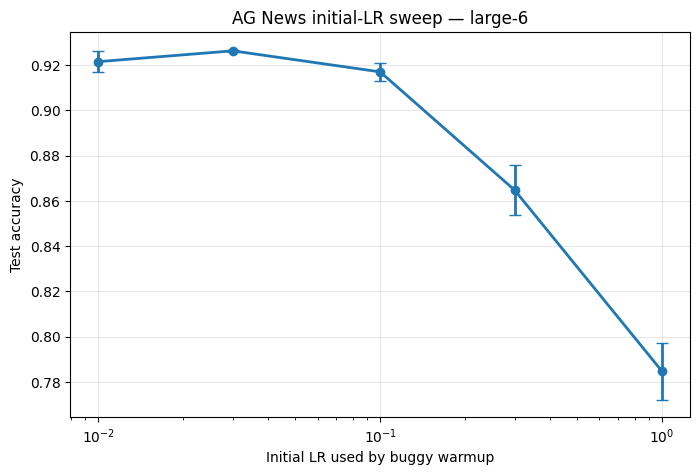

Saved: /content/agnews_final_analysis/agnews_initial_lr_sweep_accuracy_medium-4.png


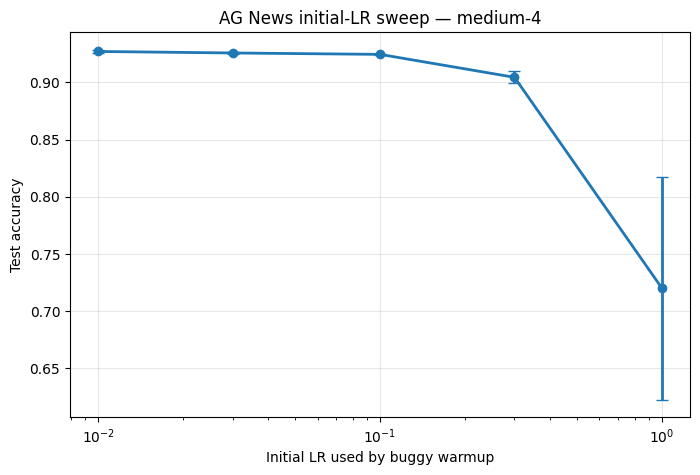

Saved: /content/agnews_final_analysis/agnews_initial_lr_sweep_nll_large-6.png


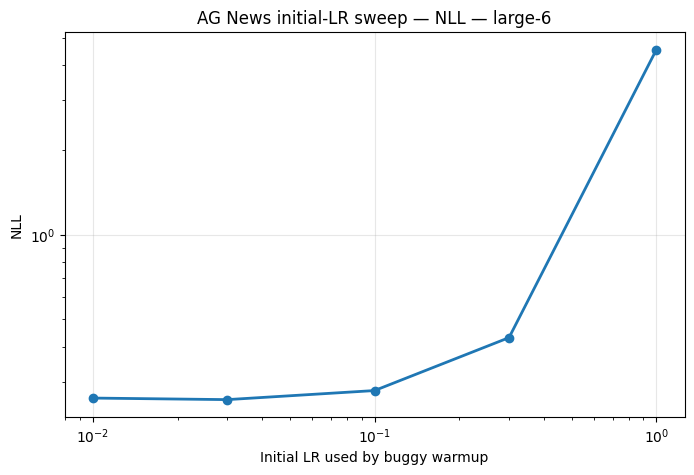

Saved: /content/agnews_final_analysis/agnews_initial_lr_sweep_nll_medium-4.png


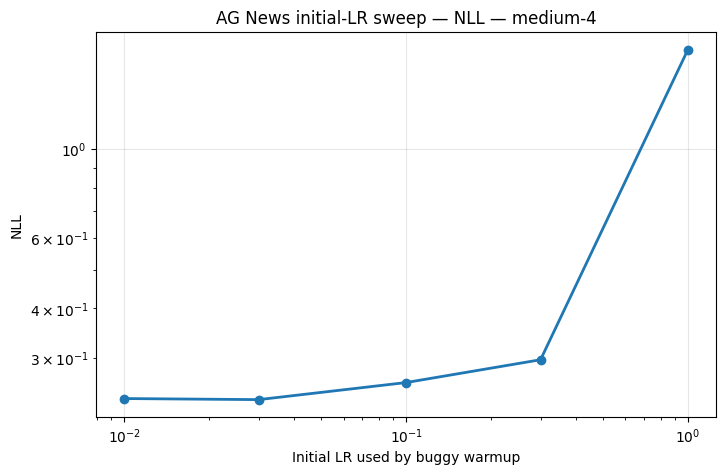

In [ ]:
for model_name in sorted(initial_lr_df["model_name"].unique()):
    sub = initial_lr_df[initial_lr_df["model_name"] == model_name].sort_values("initial_lr")

    plt.figure(figsize=(8, 5))

    plt.errorbar(
        sub["initial_lr"],
        sub["test_acc_mean"],
        yerr=sub["test_acc_std"],
        marker="o",
        linewidth=2,
        capsize=4,
    )

    plt.xscale("log")
    plt.title(f"AG News initial-LR sweep — {model_name}")
    plt.xlabel("Initial LR used by buggy warmup")
    plt.ylabel("Test accuracy")
    plt.grid(alpha=0.3)

    save_plot(f"agnews_initial_lr_sweep_accuracy_{model_name}.png")
    plt.show()


for model_name in sorted(initial_lr_df["model_name"].unique()):
    sub = initial_lr_df[initial_lr_df["model_name"] == model_name].sort_values("initial_lr")

    plt.figure(figsize=(8, 5))

    plt.plot(
        sub["initial_lr"],
        sub["nll_mean"],
        marker="o",
        linewidth=2,
    )

    plt.xscale("log")
    plt.yscale("log")
    plt.title(f"AG News initial-LR sweep — NLL — {model_name}")
    plt.xlabel("Initial LR used by buggy warmup")
    plt.ylabel("NLL")
    plt.grid(alpha=0.3)

    save_plot(f"agnews_initial_lr_sweep_nll_{model_name}.png")
    plt.show()

### Initial-LR first-step scheduler check

In [ ]:
initial_lr_trace_rows = []
trace_dir = initial_lr_root / "scheduler_traces"

for _, row in initial_lr_per_seed_df.iterrows():
    rel_file = row["scheduler_trace_file"]
    trace_path = initial_lr_root / rel_file

    if not trace_path.exists():
        possible = list(trace_dir.glob(f"*{row['model_name']}*initlr*seed{row['seed']}*.json"))
        if possible:
            trace_path = possible[0]

    if not trace_path.exists():
        initial_lr_trace_rows.append({
            "model_name": row["model_name"],
            "initial_lr": row["initial_lr"],
            "seed": row["seed"],
            "trace_found": False,
        })
        continue

    trace = load_json(trace_path)
    first = trace[0] if len(trace) > 0 else {}

    initial_lr_trace_rows.append({
        "model_name": row["model_name"],
        "initial_lr": row["initial_lr"],
        "seed": row["seed"],
        "trace_found": True,
        "first_lr_before_step": first.get("lr_before_step", np.nan),
        "first_lr_used": first.get("lr_used", np.nan),
        "first_lr_after_step": first.get("lr_after_step", np.nan),
        "num_steps": len(trace),
        "trace_file": str(trace_path),
    })

initial_lr_trace_df = pd.DataFrame(initial_lr_trace_rows).sort_values(
    ["model_name", "initial_lr", "seed"],
    ascending=[True, False, True]
)

print("AG NEWS INITIAL-LR FIRST-STEP TRACE CHECK")
display(initial_lr_trace_df)

save_table(initial_lr_trace_df, "agnews_initial_lr_first_step_trace_check.csv")

AG NEWS INITIAL-LR FIRST-STEP TRACE CHECK


,model_name,initial_lr,seed,trace_found,first_lr_before_step,first_lr_used,first_lr_after_step,num_steps,trace_file
0,large-6,1.00,42,True,1.00,1.00,2.470529e-07,86076,/content/prof_agnews_outputs/results_agnewa-no...
1,large-6,1.00,123,True,1.00,1.00,2.470529e-07,95640,/content/prof_agnews_outputs/results_agnewa-no...
2,large-6,1.00,456,True,1.00,1.00,2.470529e-07,95640,/content/prof_agnews_outputs/results_agnewa-no...
3,large-6,0.30,42,True,0.30,0.30,2.470529e-07,57384,/content/prof_agnews_outputs/results_agnewa-no...
4,large-6,0.30,123,True,0.30,0.30,2.470529e-07,57384,/content/prof_agnews_outputs/results_agnewa-no...
5,large-6,0.30,456,True,0.30,0.30,2.470529e-07,47820,/content/prof_agnews_outputs/results_agnewa-no...
6,large-6,0.10,42,True,0.10,0.10,2.470529e-07,31880,/content/prof_agnews_outputs/results_agnewa-no...
7,large-6,0.10,123,True,0.10,0.10,2.470529e-07,31880,/content/prof_agnews_outputs/results_agnewa-no...
8,large-6,0.10,456,True,0.10,0.10,2.470529e-07,28692,/content/prof_agnews_outputs/results_agnewa-no...
9,large-6,0.03,42,True,0.03,0.03,2.470529e-07,28692,/content/prof_agnews_outputs/results_agnewa-no...


Saved: /content/agnews_final_analysis/agnews_initial_lr_first_step_trace_check.csv


### Compact final interpretation numbers

In [ ]:
def get_effect(model_name, comparison, metric):
    sub = effect_df[
        (effect_df["model_name"] == model_name) &
        (effect_df["comparison"] == comparison) &
        (effect_df["metric"] == metric)
    ]
    if sub.empty:
        return None
    return sub.iloc[0].to_dict()


print("AG NEWS COMPACT INTERPRETATION")
print("=" * 100)

for model_name in sorted(per_seed_df["model_name"].unique()):
    print(f"\nMODEL: {model_name}")

    e_acc = get_effect(model_name, "stable_schedule -> legacy_buggy_warmup", "test_acc")
    e_ece = get_effect(model_name, "stable_schedule -> legacy_buggy_warmup", "test_ece")
    e_nll = get_effect(model_name, "stable_schedule -> legacy_buggy_warmup", "test_nll")

    if e_acc is not None:
        print(
            f"Stable -> buggy accuracy diff: {e_acc['mean_diff_b_minus_a']:.4f} "
            f"[{e_acc['ci95_low']:.4f}, {e_acc['ci95_high']:.4f}], dz={e_acc['cohens_dz']:.3f}"
        )

    if e_ece is not None:
        print(
            f"Stable -> buggy ECE diff     : {e_ece['mean_diff_b_minus_a']:.4f} "
            f"[{e_ece['ci95_low']:.4f}, {e_ece['ci95_high']:.4f}], dz={e_ece['cohens_dz']:.3f}"
        )

    if e_nll is not None:
        print(
            f"Stable -> buggy NLL diff     : {e_nll['mean_diff_b_minus_a']:.4f} "
            f"[{e_nll['ci95_low']:.4f}, {e_nll['ci95_high']:.4f}], dz={e_nll['cohens_dz']:.3f}"
        )

print("\nInitial-LR sweep means:")
display(initial_lr_df[["model_name", "initial_lr", "test_acc_mean", "test_acc_std", "ece_mean", "nll_mean"]])

AG NEWS COMPACT INTERPRETATION

MODEL: large-6
Stable -> buggy accuracy diff: -0.1403 [-0.1540, -0.1265], dz=-9.442
Stable -> buggy ECE diff     : 0.1817 [0.1626, 0.2009], dz=8.771
Stable -> buggy NLL diff     : 4.3046 [3.4995, 5.1098], dz=4.940

MODEL: medium-4
Stable -> buggy accuracy diff: -0.2012 [-0.3133, -0.0891], dz=-1.658
Stable -> buggy ECE diff     : 0.1522 [0.0391, 0.2652], dz=1.244
Stable -> buggy NLL diff     : 1.5255 [-0.1124, 3.1634], dz=0.861

Initial-LR sweep means:


,model_name,initial_lr,test_acc_mean,test_acc_std,ece_mean,nll_mean
0,large-6,1.00,0.784693,0.012549,0.207656,4.547869
1,large-6,0.30,0.864781,0.011020,0.042673,0.430552
2,large-6,0.10,0.917061,0.003820,0.030490,0.279147
3,large-6,0.03,0.926360,0.000541,0.030703,0.259184
4,large-6,0.01,0.921579,0.004760,0.032086,0.262509
5,medium-4,1.00,0.720219,0.097459,0.182291,1.777370
6,medium-4,0.30,0.904342,0.005210,0.028363,0.297761
7,medium-4,0.10,0.924386,0.000447,0.031522,0.261085
8,medium-4,0.03,0.925614,0.000901,0.025367,0.236626
9,medium-4,0.01,0.926930,0.001609,0.028990,0.238084


### Save all AG News analysis artifacts as zip

In [ ]:
zip_path = Path("/content/agnews_final_analysis_artifacts.zip")

if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in ANALYSIS_DIR.rglob("*"):
        if path.is_file():
            zf.write(path, arcname=str(path.relative_to(ANALYSIS_DIR)))

print("Created:", zip_path)
files.download(str(zip_path))

Created: /content/agnews_final_analysis_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Create Warmup Safety Gate runner for AG News

In [6]:
%%writefile transformer_project/run_warmup_safety_gate_agnews.py
"""
AG News Warmup Safety Gate experiment with calibrated update-ratio threshold.

Threshold rule:
- Run stable_with_guard and fixed_order_with_guard first.
- Compute max early update/parameter ratio from only those safe runs.
- Set threshold = 10 × max_safe_update_ratio.
- Manifest records threshold_source = calibrated_10x_safe_max.

Six conditions:
1. buggy_no_guard
2. buggy_failfast_guard
3. buggy_rescue_guard
4. stable_with_guard
5. fixed_order_with_guard
6. single_bad_first_step_then_stable
"""

import os
import sys
import json
import copy
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

PROJECT_ROOT = Path(__file__).resolve().parent
sys.path.append(str(PROJECT_ROOT))

from data.data_loader_scratch import load_text_dataset, get_dataloaders
from models.transformer import TransformerClassifier, create_model_configs
from utils.metrics_scratch import (
    expected_calibration_error,
    multiclass_nll,
    multiclass_brier,
    mean_ci95,
)

# ============================================================
# CHANGE ONLY THIS LINE
# ============================================================

RUN_MODE = "quick"      # quick test: seed 42 only
# RUN_MODE = "full"     # full final run: seeds 42,123,456

# ============================================================
# CONFIG
# ============================================================

DATASET_NAME = "ag_news"
RUN_TAG = "agnews_warmup_safety_gate_v2_calibrated"

if RUN_MODE == "quick":
    SEEDS = [42]
    MODEL_NAMES = ["medium-4", "large-6"]
    NUM_EPOCHS = 30
    TRAIN_FRACTION = 1.0
elif RUN_MODE == "full":
    SEEDS = [42, 123, 456]
    MODEL_NAMES = ["medium-4", "large-6"]
    NUM_EPOCHS = 30
    TRAIN_FRACTION = 1.0
else:
    raise ValueError("RUN_MODE must be 'quick' or 'full'")

CALIBRATION_CONDITIONS = [
    "stable_with_guard",
    "fixed_order_with_guard",
]

POST_CALIBRATION_CONDITIONS = [
    "buggy_no_guard",
    "buggy_failfast_guard",
    "buggy_rescue_guard",
    "single_bad_first_step_then_stable",
]

CONDITIONS = [
    "buggy_no_guard",
    "buggy_failfast_guard",
    "buggy_rescue_guard",
    "stable_with_guard",
    "fixed_order_with_guard",
    "single_bad_first_step_then_stable",
]

MAX_LENGTH = 128
BATCH_SIZE = 32
EARLY_STOPPING_PATIENCE = 5

BASE_LR = 1e-4
LEGACY_INITIAL_LR = 1.0
WARMUP_STEPS = 8000
TOTAL_STEPS = 50000

GUARD_WINDOW_STEPS = 100
DIAGNOSTIC_STEPS = 300

THRESHOLD_MULTIPLIER = 10.0
THRESHOLD_SOURCE = "calibrated_10x_safe_max"

RESULT_ROOT = PROJECT_ROOT / f"results/warmup_safety_gate_{DATASET_NAME}_{RUN_TAG}"
PER_SEED_DIR = RESULT_ROOT / "per_seed"
TRACE_DIR = RESULT_ROOT / "scheduler_traces"
GUARD_DIR = RESULT_ROOT / "guard_events"
EARLY_DIR = RESULT_ROOT / "early_logs"

for d in [RESULT_ROOT, PER_SEED_DIR, TRACE_DIR, GUARD_DIR, EARLY_DIR]:
    d.mkdir(parents=True, exist_ok=True)


def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def stable_lr(step):
    if step < WARMUP_STEPS:
        scale = step / max(1, WARMUP_STEPS)
    else:
        progress = (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS)
        progress = min(max(progress, 0.0), 1.0)
        scale = 0.5 * (1.0 + math.cos(math.pi * progress))
    return BASE_LR * scale


def legacy_lr(model, step):
    step = max(1, step)
    d_model = model.d_model
    return (d_model ** -0.5) * min(step ** -0.5, step * (WARMUP_STEPS ** -1.5))


def set_optimizer_lr(optimizer, lr):
    for group in optimizer.param_groups:
        group["lr"] = lr


def clone_trainable_params(model):
    return {
        name: p.detach().clone()
        for name, p in model.named_parameters()
        if p.requires_grad
    }


def compute_update_ratios(model, before_params):
    total_update_sq = 0.0
    total_param_sq = 0.0
    layer_update_sq = {}
    layer_param_sq = {}

    for name, p in model.named_parameters():
        if not p.requires_grad or name not in before_params:
            continue

        before = before_params[name].to(p.device)
        after = p.detach()

        upd_sq = torch.sum((after - before) ** 2).item()
        par_sq = torch.sum(before ** 2).item()

        total_update_sq += upd_sq
        total_param_sq += par_sq

        if "embedding" in name:
            group = "embedding"
        elif "classifier" in name:
            group = "classifier"
        elif "encoder_layers" in name:
            parts = name.split(".")
            group = f"layer_{parts[1]}" if len(parts) > 1 else "encoder"
        else:
            group = "other"

        layer_update_sq[group] = layer_update_sq.get(group, 0.0) + upd_sq
        layer_param_sq[group] = layer_param_sq.get(group, 0.0) + par_sq

    global_ratio = np.sqrt(total_update_sq) / (np.sqrt(total_param_sq) + 1e-12)

    layer_ratios = {
        k: np.sqrt(layer_update_sq[k]) / (np.sqrt(layer_param_sq[k]) + 1e-12)
        for k in layer_update_sq
    }

    return float(global_ratio), layer_ratios


def evaluate_full(model, loader, device, num_classes):
    model.eval()

    criterion = nn.CrossEntropyLoss()
    total_loss = 0.0
    correct = 0
    total = 0

    all_probs = []
    all_labels = []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            labels = batch["labels"].to(device)

            logits = model(input_ids)
            loss = criterion(logits, labels)

            probs = torch.softmax(logits, dim=1)
            preds = logits.argmax(dim=1)

            total_loss += loss.item()
            correct += (preds == labels).sum().item()
            total += labels.size(0)

            all_probs.append(probs.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    probs = np.concatenate(all_probs)
    labels = np.concatenate(all_labels)

    acc = correct / total
    ece = expected_calibration_error(labels, probs)
    nll = multiclass_nll(labels, probs)
    brier = multiclass_brier(labels, probs, num_classes)

    return {
        "loss": float(total_loss / len(loader)),
        "acc": float(acc),
        "ece": float(ece),
        "nll": float(nll),
        "brier": float(brier),
    }


def compute_lr_for_condition(condition, model, current_step, lr_before):
    next_step = current_step + 1

    if condition in ["buggy_no_guard", "buggy_failfast_guard", "buggy_rescue_guard"]:
        lr_used = lr_before
        lr_after = legacy_lr(model, next_step)
        return lr_used, lr_after, "schedule_after_step"

    if condition == "fixed_order_with_guard":
        lr_used = legacy_lr(model, next_step)
        lr_after = lr_used
        return lr_used, lr_after, "schedule_before_step"

    if condition == "stable_with_guard":
        lr_used = stable_lr(next_step)
        lr_after = lr_used
        return lr_used, lr_after, "schedule_before_step"

    if condition == "single_bad_first_step_then_stable":
        if current_step == 0:
            lr_used = LEGACY_INITIAL_LR
        else:
            lr_used = stable_lr(next_step)
        lr_after = stable_lr(next_step)
        return lr_used, lr_after, "single_bad_then_stable"

    raise ValueError(f"Unknown condition: {condition}")


def run_one(model_name, condition, seed, threshold, device, calibration_phase=False):
    print("\n" + "=" * 100)
    print(f"RUN: model={model_name} | condition={condition} | seed={seed}")
    print("=" * 100)

    set_seed(seed)

    train_dataset, val_dataset, test_dataset, vocab, num_classes = load_text_dataset(
        DATASET_NAME,
        max_length=MAX_LENGTH,
        split_seed=seed,
        train_fraction=TRAIN_FRACTION,
    )

    train_loader, val_loader, test_loader = get_dataloaders(
        train_dataset,
        val_dataset,
        test_dataset,
        batch_size=BATCH_SIZE,
    )

    cfg = [c for c in create_model_configs() if c["name"] == model_name][0]

    model = TransformerClassifier(
        vocab_size=len(vocab),
        num_classes=num_classes,
        d_model=cfg["d_model"],
        n_layers=cfg["n_layers"],
        n_heads=cfg["n_heads"],
        d_ff=cfg["d_ff"],
        max_seq_len=MAX_LENGTH,
    ).to(device)

    num_parameters = model.count_parameters()

    init_lr = BASE_LR if condition == "stable_with_guard" else LEGACY_INITIAL_LR

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=init_lr,
        betas=(0.9, 0.98),
        eps=1e-9,
    )

    criterion = nn.CrossEntropyLoss()

    scheduler_trace = []
    guard_events = []
    early_logs = []

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    stopped_by_guard = False
    rescued_once = False
    first_guard_trigger_step = None
    current_step = 0
    max_early_update_ratio = 0.0

    for epoch in range(NUM_EPOCHS):
        if stopped_by_guard:
            break

        model.train()
        total_loss = 0.0
        correct = 0
        total = 0
        batches_seen = 0

        for batch in train_loader:
            batches_seen += 1

            input_ids = batch["input_ids"].to(device)
            labels = batch["labels"].to(device)

            optimizer.zero_grad()
            logits = model(input_ids)
            loss = criterion(logits, labels)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            before_params = clone_trainable_params(model)
            model_state_before = copy.deepcopy(model.state_dict())
            optim_state_before = copy.deepcopy(optimizer.state_dict())

            lr_before = float(optimizer.param_groups[0]["lr"])
            lr_used, lr_after, schedule_order = compute_lr_for_condition(
                condition, model, current_step, lr_before
            )

            if schedule_order in ["schedule_before_step", "single_bad_then_stable"]:
                set_optimizer_lr(optimizer, lr_used)

            optimizer.step()

            unsafe_update_ratio, unsafe_layer_ratios = compute_update_ratios(model, before_params)

            current_step += 1

            if schedule_order == "schedule_after_step":
                set_optimizer_lr(optimizer, lr_after)

            final_update_ratio = unsafe_update_ratio
            final_layer_ratios = unsafe_layer_ratios
            guard_triggered = False
            guard_action = "none"

            if (
                not calibration_phase
                and current_step <= GUARD_WINDOW_STEPS
                and condition in ["buggy_failfast_guard", "buggy_rescue_guard"]
            ):
                if unsafe_update_ratio > threshold:
                    guard_triggered = True
                    first_guard_trigger_step = first_guard_trigger_step or current_step

                    if condition == "buggy_failfast_guard":
                        guard_action = "failfast_stop"
                        stopped_by_guard = True

                    elif condition == "buggy_rescue_guard":
                        guard_action = "rescue_correct_step"
                        rescued_once = True

                        model.load_state_dict(model_state_before)
                        optimizer.load_state_dict(optim_state_before)

                        safe_lr = legacy_lr(model, current_step)
                        set_optimizer_lr(optimizer, safe_lr)

                        optimizer.step()

                        final_update_ratio, final_layer_ratios = compute_update_ratios(model, before_params)
                        lr_used = safe_lr
                        lr_after = safe_lr

                    guard_events.append({
                        "dataset_name": DATASET_NAME,
                        "model_name": model_name,
                        "condition": condition,
                        "seed": int(seed),
                        "step": int(current_step),
                        "action": guard_action,
                        "threshold": float(threshold),
                        "threshold_source": THRESHOLD_SOURCE,
                        "observed_update_ratio": float(unsafe_update_ratio),
                        "final_update_ratio": float(final_update_ratio),
                    })

            max_early_update_ratio = max(max_early_update_ratio, final_update_ratio)

            scheduler_trace.append({
                "step": int(current_step),
                "lr_before_step": float(lr_before),
                "lr_used": float(lr_used),
                "lr_after_step": float(lr_after),
                "condition": condition,
            })

            if current_step <= DIAGNOSTIC_STEPS:
                probs = torch.softmax(logits.detach(), dim=1)
                early_logs.append({
                    "step": int(current_step),
                    "loss": float(loss.item()),
                    "lr_before_step": float(lr_before),
                    "lr_used": float(lr_used),
                    "lr_after_step": float(lr_after),
                    "update_to_param_ratio": float(final_update_ratio),
                    "unsafe_update_to_param_ratio": float(unsafe_update_ratio),
                    "mean_confidence": float(probs.max(dim=1)[0].mean().item()),
                    "layer_update_to_param_ratio": final_layer_ratios,
                })

            total_loss += loss.item()
            preds = logits.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

            if stopped_by_guard:
                break

        train_loss = total_loss / max(1, batches_seen)
        train_acc = correct / max(1, total)

        val_eval = evaluate_full(model, val_loader, device, num_classes)
        val_loss = val_eval["loss"]
        val_acc = val_eval["acc"]

        print(
            f"Epoch {epoch + 1:02d} | "
            f"train_loss={train_loss:.4f} | train_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} | val_acc={val_acc:.4f} | "
            f"stopped_by_guard={stopped_by_guard}"
        )

        if val_loss < best_val_loss and not stopped_by_guard:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= EARLY_STOPPING_PATIENCE:
            break

    if best_state is not None and not stopped_by_guard:
        model.load_state_dict(best_state)

    train_eval = evaluate_full(model, train_loader, device, num_classes)
    test_eval = evaluate_full(model, test_loader, device, num_classes)

    generalization_gap = train_eval["acc"] - test_eval["acc"]

    file_stub = f"{DATASET_NAME}_{model_name}_{condition}_seed{seed}"

    scheduler_trace_file = TRACE_DIR / f"{file_stub}_scheduler_trace.json"
    guard_events_file = GUARD_DIR / f"{file_stub}_guard_events.json"
    early_logs_file = EARLY_DIR / f"{file_stub}_early_logs.json"

    save_json(scheduler_trace, scheduler_trace_file)
    save_json(guard_events, guard_events_file)
    save_json(early_logs, early_logs_file)

    result = {
        "dataset_name": DATASET_NAME,
        "run_tag": RUN_TAG,
        "run_mode": RUN_MODE,
        "model_name": model_name,
        "condition": condition,
        "seed": int(seed),
        "num_parameters": int(num_parameters),
        "train_fraction": float(TRAIN_FRACTION),
        "num_epochs_config": int(NUM_EPOCHS),
        "threshold": None if threshold is None else float(threshold),
        "threshold_source": THRESHOLD_SOURCE,
        "threshold_multiplier": float(THRESHOLD_MULTIPLIER),
        "threshold_calibration_conditions": CALIBRATION_CONDITIONS,
        "calibration_phase": bool(calibration_phase),
        "test_acc": float(test_eval["acc"]),
        "test_ece": float(test_eval["ece"]),
        "test_nll": float(test_eval["nll"]),
        "test_brier": float(test_eval["brier"]),
        "train_acc": float(train_eval["acc"]),
        "generalization_gap_01": float(generalization_gap),
        "guard_trigger_count": int(len(guard_events)),
        "stopped_by_guard": bool(stopped_by_guard),
        "rescued_once": bool(rescued_once),
        "first_guard_trigger_step": first_guard_trigger_step,
        "max_early_update_ratio": float(max_early_update_ratio),
        "scheduler_trace_file": str(scheduler_trace_file.relative_to(RESULT_ROOT)),
        "guard_events_file": str(guard_events_file.relative_to(RESULT_ROOT)),
        "early_logs_file": str(early_logs_file.relative_to(RESULT_ROOT)),
    }

    per_seed_file = PER_SEED_DIR / f"{file_stub}.json"
    save_json(result, per_seed_file)

    print(
        f"FINAL | test_acc={result['test_acc']:.4f} | "
        f"ece={result['test_ece']:.4f} | "
        f"nll={result['test_nll']:.4f} | "
        f"max_update={result['max_early_update_ratio']:.3e} | "
        f"guard_triggers={result['guard_trigger_count']} | "
        f"stopped={result['stopped_by_guard']} | "
        f"rescued={result['rescued_once']}"
    )

    return result


def calibrate_threshold(device):
    print("\n" + "=" * 100)
    print("CALIBRATING THRESHOLD FROM SAFE RUNS ONLY")
    print("=" * 100)

    calibration_results = []

    for model_name in MODEL_NAMES:
        for condition in CALIBRATION_CONDITIONS:
            for seed in SEEDS:
                result = run_one(
                    model_name=model_name,
                    condition=condition,
                    seed=seed,
                    threshold=None,
                    device=device,
                    calibration_phase=True,
                )
                calibration_results.append(result)

                pd.DataFrame(calibration_results).to_csv(
                    RESULT_ROOT / "threshold_calibration_safe_runs.csv",
                    index=False,
                )

    safe_max = max(r["max_early_update_ratio"] for r in calibration_results)
    threshold = THRESHOLD_MULTIPLIER * safe_max

    calibration_record = {
        "threshold": float(threshold),
        "threshold_source": THRESHOLD_SOURCE,
        "threshold_multiplier": float(THRESHOLD_MULTIPLIER),
        "safe_max_update_ratio": float(safe_max),
        "threshold_calibration_conditions": CALIBRATION_CONDITIONS,
        "calibration_models": MODEL_NAMES,
        "calibration_seeds": SEEDS,
        "calibration_rule": "threshold = 10 * max(max_early_update_ratio over stable_with_guard and fixed_order_with_guard)",
    }

    save_json(calibration_record, RESULT_ROOT / "threshold_calibration_record.json")

    print("\nCALIBRATION COMPLETE")
    print(json.dumps(calibration_record, indent=2))

    return threshold, calibration_record, calibration_results


def summarize_results(results, threshold):
    rows = []

    for (model_name, condition), sub_df in pd.DataFrame(results).groupby(["model_name", "condition"]):
        rows.append({
            "dataset_name": DATASET_NAME,
            "model_name": model_name,
            "condition": condition,
            "num_parameters": int(sub_df["num_parameters"].iloc[0]),
            "seeds": sorted(sub_df["seed"].astype(int).tolist()),
            "threshold": float(threshold),
            "threshold_source": THRESHOLD_SOURCE,
            "threshold_multiplier": float(THRESHOLD_MULTIPLIER),
            "threshold_calibration_conditions": CALIBRATION_CONDITIONS,
            "guard_trigger_rate": float((sub_df["guard_trigger_count"] > 0).mean()),
            "stopped_rate": float(sub_df["stopped_by_guard"].mean()),
            "rescued_rate": float(sub_df["rescued_once"].mean()),
            "first_guard_trigger_step_mean": float(sub_df["first_guard_trigger_step"].dropna().mean()) if sub_df["first_guard_trigger_step"].notna().any() else None,
            "max_early_update_ratio_mean": float(sub_df["max_early_update_ratio"].mean()),
            "test_acc_stats": mean_ci95(sub_df["test_acc"].values),
            "ece_stats": mean_ci95(sub_df["test_ece"].values),
            "nll_stats": mean_ci95(sub_df["test_nll"].values),
            "brier_stats": mean_ci95(sub_df["test_brier"].values),
            "gap_stats": mean_ci95(sub_df["generalization_gap_01"].values),
        })

    return rows


def main():
    device = "cuda" if torch.cuda.is_available() else "cpu"

    threshold, calibration_record, calibration_results = calibrate_threshold(device)

    manifest = {
        "dataset_name": DATASET_NAME,
        "run_tag": RUN_TAG,
        "run_mode": RUN_MODE,
        "models": MODEL_NAMES,
        "conditions": CONDITIONS,
        "calibration_conditions": CALIBRATION_CONDITIONS,
        "post_calibration_conditions": POST_CALIBRATION_CONDITIONS,
        "seeds": SEEDS,
        "train_fraction": TRAIN_FRACTION,
        "base_lr": BASE_LR,
        "legacy_initial_lr": LEGACY_INITIAL_LR,
        "warmup_steps": WARMUP_STEPS,
        "total_steps": TOTAL_STEPS,
        "guard_window_steps": GUARD_WINDOW_STEPS,
        "diagnostic_steps": DIAGNOSTIC_STEPS,
        "threshold": float(threshold),
        "threshold_source": THRESHOLD_SOURCE,
        "threshold_multiplier": float(THRESHOLD_MULTIPLIER),
        "safe_max_update_ratio": float(calibration_record["safe_max_update_ratio"]),
        "threshold_calibration_conditions": CALIBRATION_CONDITIONS,
        "threshold_calibration_rule": calibration_record["calibration_rule"],
        "max_length": MAX_LENGTH,
        "batch_size": BATCH_SIZE,
        "num_epochs": NUM_EPOCHS,
        "device": device,
    }

    save_json(manifest, RESULT_ROOT / "run_manifest.json")

    print("\n" + "=" * 100)
    print("AG NEWS WARMUP SAFETY GATE MANIFEST")
    print("=" * 100)
    for k, v in manifest.items():
        print(f"{k:<35}: {v}")

    results = list(calibration_results)

    pd.DataFrame(results).to_csv(
        RESULT_ROOT / "warmup_safety_gate_per_seed.csv",
        index=False,
    )

    save_json(
        summarize_results(results, threshold),
        RESULT_ROOT / "warmup_safety_gate_summary.json",
    )

    for model_name in MODEL_NAMES:
        for condition in POST_CALIBRATION_CONDITIONS:
            for seed in SEEDS:
                result = run_one(
                    model_name=model_name,
                    condition=condition,
                    seed=seed,
                    threshold=threshold,
                    device=device,
                    calibration_phase=False,
                )

                results.append(result)

                pd.DataFrame(results).to_csv(
                    RESULT_ROOT / "warmup_safety_gate_per_seed.csv",
                    index=False,
                )

                save_json(
                    summarize_results(results, threshold),
                    RESULT_ROOT / "warmup_safety_gate_summary.json",
                )

    final_summary = summarize_results(results, threshold)

    print("\nSUMMARY")
    print(json.dumps(final_summary, indent=2))

    print("\nSaved result root:", RESULT_ROOT)


if __name__ == "__main__":
    main()

Writing transformer_project/run_warmup_safety_gate_agnews.py


### Run AG News Warmup Safety Gate experiment(one seed test)

In [ ]:
!python transformer_project/run_warmup_safety_gate_agnews.py


CALIBRATING THRESHOLD FROM SAFE RUNS ONLY

RUN: model=medium-4 | condition=stable_with_guard | seed=42
Loading ag_news from fancyzhx/ag_news...
README.md: 100% 8.07k/8.07k [00:00<00:00, 3.47MB/s]
data/train-00000-of-00001.parquet: 100% 18.6M/18.6M [00:01<00:00, 15.0MB/s]
data/test-00000-of-00001.parquet: 100% 1.23M/1.23M [00:00<00:00, 2.05MB/s]
Generating train split: 100% 120000/120000 [00:00<00:00, 689321.66 examples/s]
Generating test split: 100% 7600/7600 [00:00<00:00, 584797.20 examples/s]
Official split sizes: Train=120,000 | Test=7,600
Split seed=42, train_fraction=1.00: Train=102,000 | Val=18,000 | Test=7,600
Vocabulary size: 30,000
Epoch 01 | train_loss=1.0450 | train_acc=0.5441 | val_loss=0.5519 | val_acc=0.7978 | stopped_by_guard=False
Epoch 02 | train_loss=0.4447 | train_acc=0.8429 | val_loss=0.3646 | val_acc=0.8762 | stopped_by_guard=False
Epoch 03 | train_loss=0.3041 | train_acc=0.8956 | val_loss=0.2704 | val_acc=0.9121 | stopped_by_guard=False
Epoch 04 | train_loss=0.23

### Analyze AG News Warmup Safety Gate results

AG NEWS WARMUP SAFETY GATE MANIFEST
dataset_name                       : ag_news
run_tag                            : agnews_warmup_safety_gate_v2_calibrated
run_mode                           : full
models                             : ['medium-4', 'large-6']
conditions                         : ['buggy_no_guard', 'buggy_failfast_guard', 'buggy_rescue_guard', 'stable_with_guard', 'fixed_order_with_guard', 'single_bad_first_step_then_stable']
calibration_conditions             : ['stable_with_guard', 'fixed_order_with_guard']
post_calibration_conditions        : ['buggy_no_guard', 'buggy_failfast_guard', 'buggy_rescue_guard', 'single_bad_first_step_then_stable']
seeds                              : [42, 123, 456]
train_fraction                     : 1.0
base_lr                            : 0.0001
legacy_initial_lr                  : 1.0
warmup_steps                       : 8000
total_steps                        : 50000
guard_window_steps                 : 100
diagnostic_steps         

,dataset_name,run_tag,run_mode,model_name,condition,seed,num_parameters,train_fraction,num_epochs_config,threshold,...,train_acc,generalization_gap_01,guard_trigger_count,stopped_by_guard,rescued_once,first_guard_trigger_step,max_early_update_ratio,scheduler_trace_file,guard_events_file,early_logs_file
0,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,stable_with_guard,42,4632068,1.0,30,NaN,...,0.961206,0.041337,0,False,False,NaN,0.000193,scheduler_traces/ag_news_medium-4_stable_with_...,guard_events/ag_news_medium-4_stable_with_guar...,early_logs/ag_news_medium-4_stable_with_guard_...
1,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,stable_with_guard,123,4632068,1.0,30,NaN,...,0.956225,0.034647,0,False,False,NaN,0.000190,scheduler_traces/ag_news_medium-4_stable_with_...,guard_events/ag_news_medium-4_stable_with_guar...,early_logs/ag_news_medium-4_stable_with_guard_...
2,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,stable_with_guard,456,4632068,1.0,30,NaN,...,0.955931,0.032379,0,False,False,NaN,0.000193,scheduler_traces/ag_news_medium-4_stable_with_...,guard_events/ag_news_medium-4_stable_with_guar...,early_logs/ag_news_medium-4_stable_with_guard_...
3,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,fixed_order_with_guard,42,4632068,1.0,30,NaN,...,0.963696,0.035801,0,False,False,NaN,0.001476,scheduler_traces/ag_news_medium-4_fixed_order_...,guard_events/ag_news_medium-4_fixed_order_with...,early_logs/ag_news_medium-4_fixed_order_with_g...
4,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,fixed_order_with_guard,123,4632068,1.0,30,NaN,...,0.956500,0.030184,0,False,False,NaN,0.001537,scheduler_traces/ag_news_medium-4_fixed_order_...,guard_events/ag_news_medium-4_fixed_order_with...,early_logs/ag_news_medium-4_fixed_order_with_g...
5,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,fixed_order_with_guard,456,4632068,1.0,30,NaN,...,0.965676,0.037650,0,False,False,NaN,0.001563,scheduler_traces/ag_news_medium-4_fixed_order_...,guard_events/ag_news_medium-4_fixed_order_with...,early_logs/ag_news_medium-4_fixed_order_with_g...
6,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,large-6,stable_with_guard,42,12414980,1.0,30,NaN,...,0.970010,0.044352,0,False,False,NaN,0.000335,scheduler_traces/ag_news_large-6_stable_with_g...,guard_events/ag_news_large-6_stable_with_guard...,early_logs/ag_news_large-6_stable_with_guard_s...
7,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,large-6,stable_with_guard,123,12414980,1.0,30,NaN,...,0.942990,0.022990,0,False,False,NaN,0.000339,scheduler_traces/ag_news_large-6_stable_with_g...,guard_events/ag_news_large-6_stable_with_guard...,early_logs/ag_news_large-6_stable_with_guard_s...
8,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,large-6,stable_with_guard,456,12414980,1.0,30,NaN,...,0.941078,0.023842,0,False,False,NaN,0.000343,scheduler_traces/ag_news_large-6_stable_with_g...,guard_events/ag_news_large-6_stable_with_guard...,early_logs/ag_news_large-6_stable_with_guard_s...
9,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,large-6,fixed_order_with_guard,42,12414980,1.0,30,NaN,...,0.962520,0.037783,0,False,False,NaN,0.002004,scheduler_traces/ag_news_large-6_fixed_order_w...,guard_events/ag_news_large-6_fixed_order_with_...,early_logs/ag_news_large-6_fixed_order_with_gu...



AG NEWS CALIBRATION SAFE RUNS


,dataset_name,run_tag,run_mode,model_name,condition,seed,num_parameters,train_fraction,num_epochs_config,threshold,...,train_acc,generalization_gap_01,guard_trigger_count,stopped_by_guard,rescued_once,first_guard_trigger_step,max_early_update_ratio,scheduler_trace_file,guard_events_file,early_logs_file
0,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,stable_with_guard,42,4632068,1.0,30,NaN,...,0.961206,0.041337,0,False,False,NaN,0.000193,scheduler_traces/ag_news_medium-4_stable_with_...,guard_events/ag_news_medium-4_stable_with_guar...,early_logs/ag_news_medium-4_stable_with_guard_...
1,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,stable_with_guard,123,4632068,1.0,30,NaN,...,0.956225,0.034647,0,False,False,NaN,0.000190,scheduler_traces/ag_news_medium-4_stable_with_...,guard_events/ag_news_medium-4_stable_with_guar...,early_logs/ag_news_medium-4_stable_with_guard_...
2,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,stable_with_guard,456,4632068,1.0,30,NaN,...,0.955931,0.032379,0,False,False,NaN,0.000193,scheduler_traces/ag_news_medium-4_stable_with_...,guard_events/ag_news_medium-4_stable_with_guar...,early_logs/ag_news_medium-4_stable_with_guard_...
3,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,fixed_order_with_guard,42,4632068,1.0,30,NaN,...,0.963696,0.035801,0,False,False,NaN,0.001476,scheduler_traces/ag_news_medium-4_fixed_order_...,guard_events/ag_news_medium-4_fixed_order_with...,early_logs/ag_news_medium-4_fixed_order_with_g...
4,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,fixed_order_with_guard,123,4632068,1.0,30,NaN,...,0.956500,0.030184,0,False,False,NaN,0.001537,scheduler_traces/ag_news_medium-4_fixed_order_...,guard_events/ag_news_medium-4_fixed_order_with...,early_logs/ag_news_medium-4_fixed_order_with_g...
5,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,fixed_order_with_guard,456,4632068,1.0,30,NaN,...,0.965676,0.037650,0,False,False,NaN,0.001563,scheduler_traces/ag_news_medium-4_fixed_order_...,guard_events/ag_news_medium-4_fixed_order_with...,early_logs/ag_news_medium-4_fixed_order_with_g...
6,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,large-6,stable_with_guard,42,12414980,1.0,30,NaN,...,0.970010,0.044352,0,False,False,NaN,0.000335,scheduler_traces/ag_news_large-6_stable_with_g...,guard_events/ag_news_large-6_stable_with_guard...,early_logs/ag_news_large-6_stable_with_guard_s...
7,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,large-6,stable_with_guard,123,12414980,1.0,30,NaN,...,0.942990,0.022990,0,False,False,NaN,0.000339,scheduler_traces/ag_news_large-6_stable_with_g...,guard_events/ag_news_large-6_stable_with_guard...,early_logs/ag_news_large-6_stable_with_guard_s...
8,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,large-6,stable_with_guard,456,12414980,1.0,30,NaN,...,0.941078,0.023842,0,False,False,NaN,0.000343,scheduler_traces/ag_news_large-6_stable_with_g...,guard_events/ag_news_large-6_stable_with_guard...,early_logs/ag_news_large-6_stable_with_guard_s...
9,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,large-6,fixed_order_with_guard,42,12414980,1.0,30,NaN,...,0.962520,0.037783,0,False,False,NaN,0.002004,scheduler_traces/ag_news_large-6_fixed_order_w...,guard_events/ag_news_large-6_fixed_order_with_...,early_logs/ag_news_large-6_fixed_order_with_gu...


Saved: /content/agnews_warmup_safety_gate_analysis/agnews_warmup_safety_gate_per_seed.csv
Saved: /content/agnews_warmup_safety_gate_analysis/agnews_threshold_calibration_safe_runs.csv

AG NEWS SUMMARY TABLE


,model_name,condition,num_parameters,threshold,threshold_source,threshold_multiplier,threshold_calibration_conditions,guard_trigger_rate,stopped_rate,rescued_rate,first_guard_trigger_step_mean,max_early_update_ratio_mean,test_acc_mean,test_acc_std,test_acc_ci95_low,test_acc_ci95_high,ece_mean,nll_mean,brier_mean,gap_mean
0,large-6,buggy_no_guard,12414980,0.020044,calibrated_10x_safe_max,10.0,"[stable_with_guard, fixed_order_with_guard]",0.0,0.0,0.0,NaN,10.998268,0.744386,0.011757,0.731081,0.757690,0.243837,5.152672,0.494422,0.020771
1,large-6,buggy_failfast_guard,12414980,0.020044,calibrated_10x_safe_max,10.0,"[stable_with_guard, fixed_order_with_guard]",1.0,1.0,0.0,1.0,10.998268,0.250175,0.004836,0.244703,0.255648,0.749818,20.717193,1.499626,0.000148
2,large-6,buggy_rescue_guard,12414980,0.020044,calibrated_10x_safe_max,10.0,"[stable_with_guard, fixed_order_with_guard]",1.0,0.0,1.0,1.0,0.002027,0.921974,0.004061,0.917378,0.926569,0.029749,0.258866,0.122239,0.034275
3,large-6,stable_with_guard,12414980,0.020044,calibrated_10x_safe_max,10.0,"[stable_with_guard, fixed_order_with_guard]",0.0,0.0,0.0,NaN,0.000339,0.920965,0.003505,0.916999,0.924931,0.025739,0.256992,0.123151,0.030395
4,large-6,fixed_order_with_guard,12414980,0.020044,calibrated_10x_safe_max,10.0,"[stable_with_guard, fixed_order_with_guard]",0.0,0.0,0.0,NaN,0.001904,0.924342,0.001267,0.922909,0.925775,0.034462,0.261862,0.118990,0.038413
5,large-6,single_bad_first_step_then_stable,12414980,0.020044,calibrated_10x_safe_max,10.0,"[stable_with_guard, fixed_order_with_guard]",0.0,0.0,0.0,NaN,10.998268,0.377763,0.012464,0.363659,0.391867,0.621584,17.078501,1.243488,0.004982
6,medium-4,buggy_no_guard,4632068,0.020044,calibrated_10x_safe_max,10.0,"[stable_with_guard, fixed_order_with_guard]",0.0,0.0,0.0,NaN,5.090811,0.806096,0.032437,0.769390,0.842803,0.089538,0.665014,0.293383,0.023005
7,medium-4,buggy_failfast_guard,4632068,0.020044,calibrated_10x_safe_max,10.0,"[stable_with_guard, fixed_order_with_guard]",1.0,1.0,0.0,1.0,5.090811,0.250000,0.000000,0.250000,0.250000,0.750000,20.723267,1.500000,-0.000137
8,medium-4,buggy_rescue_guard,4632068,0.020044,calibrated_10x_safe_max,10.0,"[stable_with_guard, fixed_order_with_guard]",1.0,0.0,1.0,1.0,0.001553,0.926711,0.000568,0.926067,0.927354,0.025106,0.240627,0.115499,0.030590
9,medium-4,stable_with_guard,4632068,0.020044,calibrated_10x_safe_max,10.0,"[stable_with_guard, fixed_order_with_guard]",0.0,0.0,0.0,NaN,0.000192,0.921667,0.001505,0.919963,0.923370,0.029345,0.251769,0.121504,0.036121


Saved: /content/agnews_warmup_safety_gate_analysis/agnews_warmup_safety_gate_summary.csv
Saved: /content/agnews_warmup_safety_gate_analysis/agnews_guard_accuracy_large-6.png


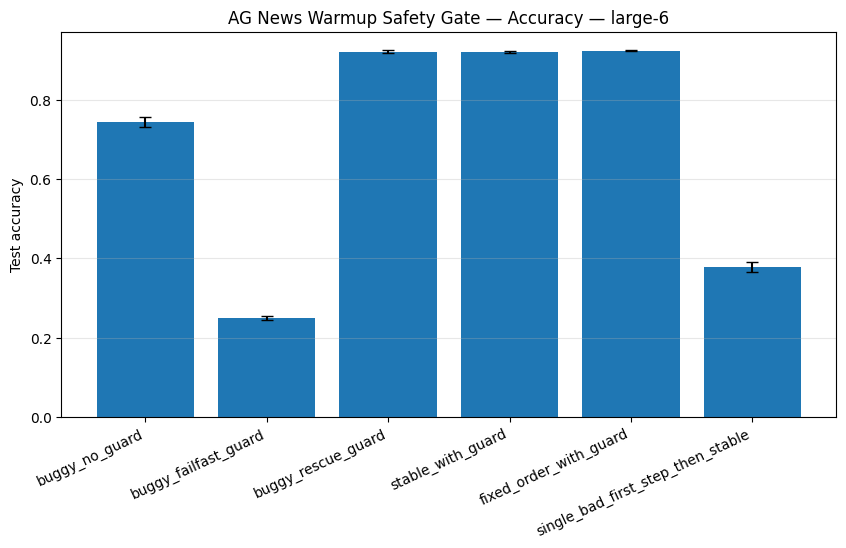

Saved: /content/agnews_warmup_safety_gate_analysis/agnews_guard_accuracy_medium-4.png


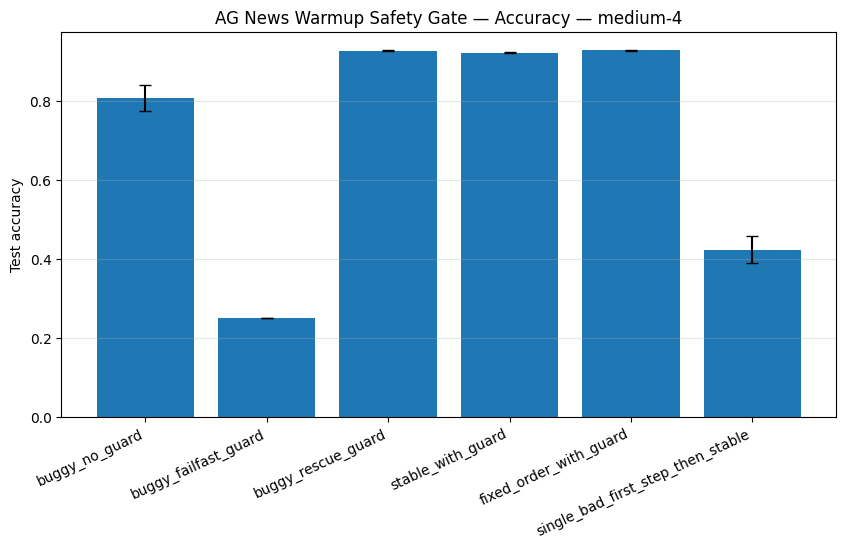

Saved: /content/agnews_warmup_safety_gate_analysis/agnews_guard_update_ratio_large-6.png


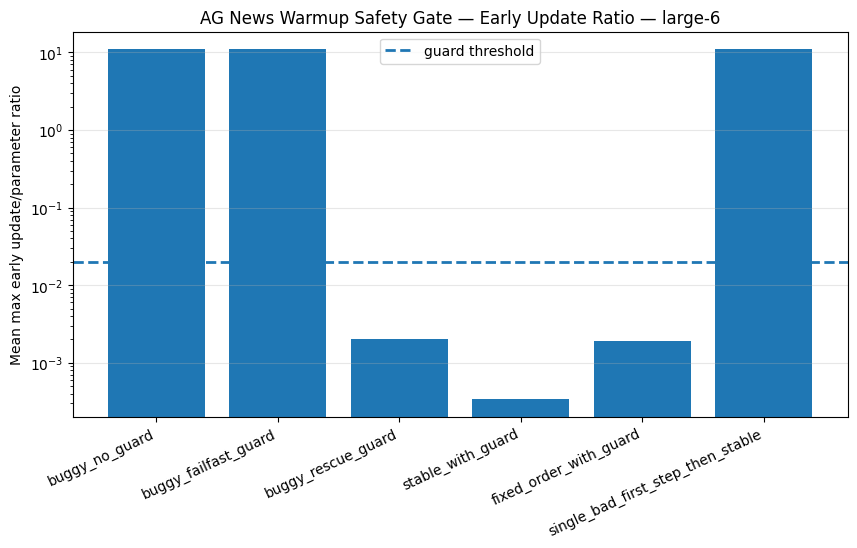

Saved: /content/agnews_warmup_safety_gate_analysis/agnews_guard_update_ratio_medium-4.png


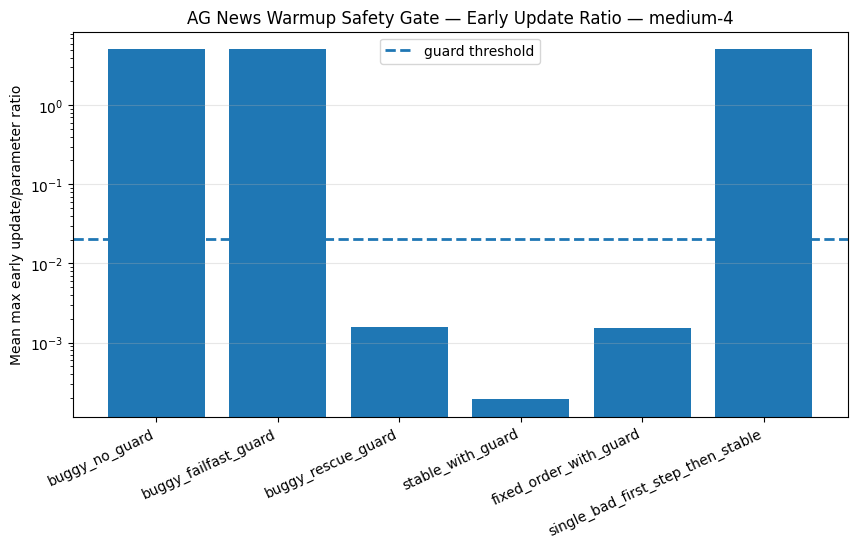

Saved: /content/agnews_warmup_safety_gate_analysis/agnews_guard_nll_large-6.png


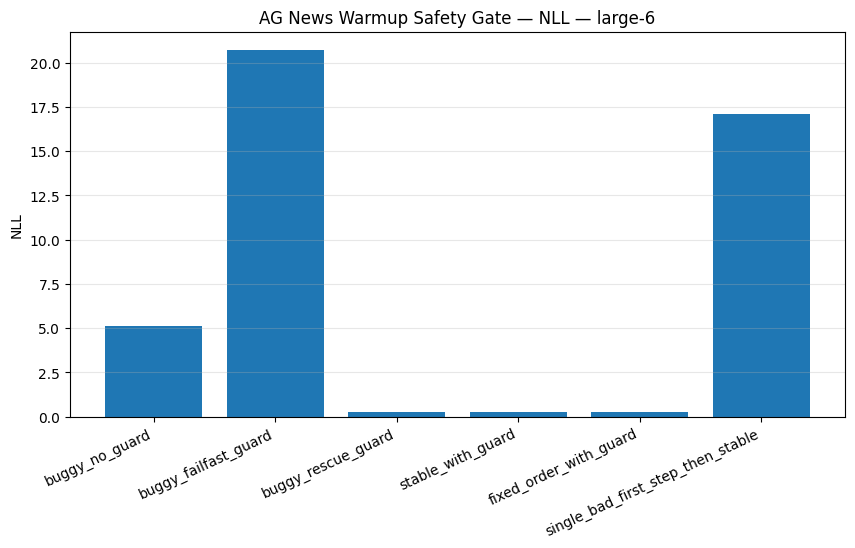

Saved: /content/agnews_warmup_safety_gate_analysis/agnews_guard_nll_medium-4.png


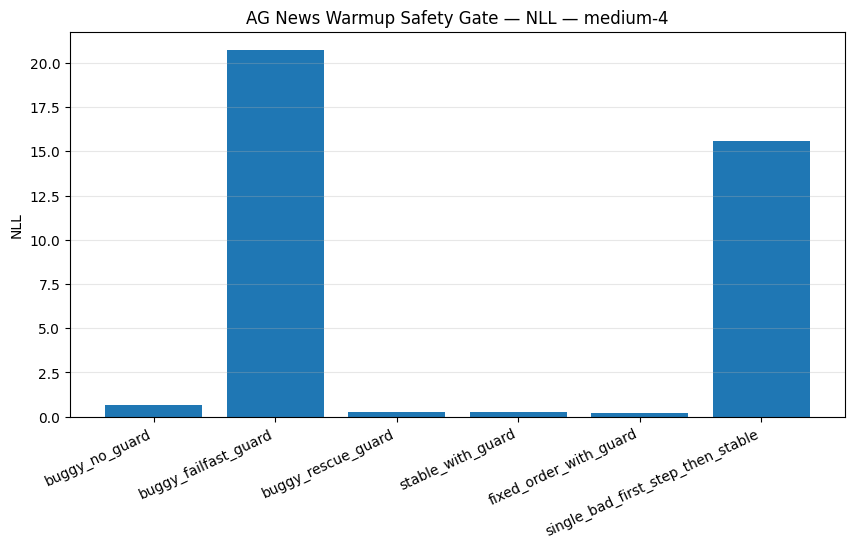

Created: /content/agnews_warmup_safety_gate_analysis.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import files

AG_GUARD_ROOT = Path(
    "/content/results_extracted/Lubem/final_agnews_warmup_safety_gate_calibrated_package/"
    "transformer_project/results/warmup_safety_gate_ag_news_agnews_warmup_safety_gate_v2_calibrated"
)

AG_ANALYSIS_DIR = Path("/content/agnews_warmup_safety_gate_analysis")
AG_ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

def load_json(path):
    with open(path, "r") as f:
        return json.load(f)

def save_table(df, filename):
    path = AG_ANALYSIS_DIR / filename
    df.to_csv(path, index=False)
    print("Saved:", path)

def save_plot(filename):
    path = AG_ANALYSIS_DIR / filename
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved:", path)

manifest = load_json(AG_GUARD_ROOT / "run_manifest.json")
summary = load_json(AG_GUARD_ROOT / "warmup_safety_gate_summary.json")
per_seed_df = pd.read_csv(AG_GUARD_ROOT / "warmup_safety_gate_per_seed.csv")
calibration_df = pd.read_csv(AG_GUARD_ROOT / "threshold_calibration_safe_runs.csv")
calibration_record = load_json(AG_GUARD_ROOT / "threshold_calibration_record.json")

print("AG NEWS WARMUP SAFETY GATE MANIFEST")
print("=" * 100)
for k, v in manifest.items():
    print(f"{k:<35}: {v}")

print("\nTHRESHOLD CALIBRATION RECORD")
print("=" * 100)
for k, v in calibration_record.items():
    print(f"{k:<35}: {v}")

print("\nAG NEWS PER-SEED RESULTS")
display(per_seed_df)

print("\nAG NEWS CALIBRATION SAFE RUNS")
display(calibration_df)

save_table(per_seed_df, "agnews_warmup_safety_gate_per_seed.csv")
save_table(calibration_df, "agnews_threshold_calibration_safe_runs.csv")

summary_rows = []
for row in summary:
    summary_rows.append({
        "model_name": row["model_name"],
        "condition": row["condition"],
        "num_parameters": row["num_parameters"],
        "threshold": row["threshold"],
        "threshold_source": row["threshold_source"],
        "threshold_multiplier": row["threshold_multiplier"],
        "threshold_calibration_conditions": row["threshold_calibration_conditions"],
        "guard_trigger_rate": row["guard_trigger_rate"],
        "stopped_rate": row["stopped_rate"],
        "rescued_rate": row["rescued_rate"],
        "first_guard_trigger_step_mean": row["first_guard_trigger_step_mean"],
        "max_early_update_ratio_mean": row["max_early_update_ratio_mean"],
        "test_acc_mean": row["test_acc_stats"]["mean"],
        "test_acc_std": row["test_acc_stats"]["std"],
        "test_acc_ci95_low": row["test_acc_stats"]["ci95_low"],
        "test_acc_ci95_high": row["test_acc_stats"]["ci95_high"],
        "ece_mean": row["ece_stats"]["mean"],
        "nll_mean": row["nll_stats"]["mean"],
        "brier_mean": row["brier_stats"]["mean"],
        "gap_mean": row["gap_stats"]["mean"],
    })

summary_df = pd.DataFrame(summary_rows)

condition_order = [
    "buggy_no_guard",
    "buggy_failfast_guard",
    "buggy_rescue_guard",
    "stable_with_guard",
    "fixed_order_with_guard",
    "single_bad_first_step_then_stable",
]

summary_df["condition"] = pd.Categorical(
    summary_df["condition"],
    categories=condition_order,
    ordered=True,
)

summary_df = summary_df.sort_values(["model_name", "condition"]).reset_index(drop=True)

print("\nAG NEWS SUMMARY TABLE")
display(summary_df)

save_table(summary_df, "agnews_warmup_safety_gate_summary.csv")

for model_name in sorted(summary_df["model_name"].unique()):
    sub = summary_df[summary_df["model_name"] == model_name].copy()

    plt.figure(figsize=(10, 5))
    plt.bar(sub["condition"].astype(str), sub["test_acc_mean"], yerr=sub["test_acc_std"], capsize=4)
    plt.xticks(rotation=25, ha="right")
    plt.ylabel("Test accuracy")
    plt.title(f"AG News Warmup Safety Gate — Accuracy — {model_name}")
    plt.grid(axis="y", alpha=0.3)
    save_plot(f"agnews_guard_accuracy_{model_name}.png")
    plt.show()

for model_name in sorted(summary_df["model_name"].unique()):
    sub = summary_df[summary_df["model_name"] == model_name].copy()

    plt.figure(figsize=(10, 5))
    plt.bar(sub["condition"].astype(str), sub["max_early_update_ratio_mean"])
    plt.axhline(float(manifest["threshold"]), linestyle="--", linewidth=2, label="guard threshold")
    plt.yscale("log")
    plt.xticks(rotation=25, ha="right")
    plt.ylabel("Mean max early update/parameter ratio")
    plt.title(f"AG News Warmup Safety Gate — Early Update Ratio — {model_name}")
    plt.grid(axis="y", alpha=0.3)
    plt.legend()
    save_plot(f"agnews_guard_update_ratio_{model_name}.png")
    plt.show()

for model_name in sorted(summary_df["model_name"].unique()):
    sub = summary_df[summary_df["model_name"] == model_name].copy()

    plt.figure(figsize=(10, 5))
    plt.bar(sub["condition"].astype(str), sub["nll_mean"])
    plt.xticks(rotation=25, ha="right")
    plt.ylabel("NLL")
    plt.title(f"AG News Warmup Safety Gate — NLL — {model_name}")
    plt.grid(axis="y", alpha=0.3)
    save_plot(f"agnews_guard_nll_{model_name}.png")
    plt.show()

zip_path = Path("/content/agnews_warmup_safety_gate_analysis.zip")

if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in AG_ANALYSIS_DIR.rglob("*"):
        if path.is_file():
            zf.write(path, arcname=str(path.relative_to(AG_ANALYSIS_DIR)))

print("Created:", zip_path)
files.download(str(zip_path))

### Upload and extract all zips

In [10]:
import zipfile
import shutil
from pathlib import Path

DATASET_NAME = "ag_news"

BASE_DIR = Path("/content/paper_inputs")
BASE_DIR.mkdir(parents=True, exist_ok=True)

zip_files = list(Path("/content").glob("*.zip"))

print("Found zip files:")
for z in zip_files:
    print(z)

if not zip_files:
    raise FileNotFoundError("No zip files found in /content. Upload them manually from the left Files panel first.")

for src in zip_files:
    out_dir = BASE_DIR / src.stem.replace(" ", "_").replace("(", "").replace(")", "")
    out_dir.mkdir(parents=True, exist_ok=True)

    print(f"Extracting {src} -> {out_dir}")
    with zipfile.ZipFile(src, "r") as zf:
        zf.extractall(out_dir)

nested_zips = list(BASE_DIR.rglob("*.zip"))

for src in nested_zips:
    out_dir = src.parent / src.stem.replace(" ", "_").replace("(", "").replace(")", "")
    out_dir.mkdir(parents=True, exist_ok=True)

    print(f"Extracting nested {src} -> {out_dir}")
    with zipfile.ZipFile(src, "r") as zf:
        zf.extractall(out_dir)

print("\nExtraction complete.")
print("Base folder:", BASE_DIR)

Found zip files:
/content/Lubem(1).zip
/content/results_agnewa-no_ckp.zip
Extracting /content/Lubem(1).zip -> /content/paper_inputs/Lubem1
Extracting /content/results_agnewa-no_ckp.zip -> /content/paper_inputs/results_agnewa-no_ckp

Extraction complete.
Base folder: /content/paper_inputs


### Find all result roots

In [11]:
from pathlib import Path
import json

print("FOUND MANIFESTS")
print("=" * 100)

manifest_paths = list(BASE_DIR.rglob("run_manifest.json")) + list(BASE_DIR.rglob("*manifest.json"))

for p in manifest_paths:
    print(p)

print("\nFOUND MAIN CSV/JSON RESULT FILES")
print("=" * 100)

for p in BASE_DIR.rglob("*"):
    if p.is_file() and p.suffix.lower() in [".csv", ".json"]:
        name = p.name.lower()
        if any(x in name for x in ["summary", "per_seed", "calibration", "manifest", "scheduler"]):
            print(p)

FOUND MANIFESTS
/content/paper_inputs/Lubem1/Lubem/final_dbpedia_warmup_safety_gate_calibrated_package/transformer_project/results/warmup_safety_gate_dbpedia_14_dbpedia_warmup_safety_gate_v2_calibrated/run_manifest.json
/content/paper_inputs/Lubem1/Lubem/final_agnews_warmup_safety_gate_calibrated_package/transformer_project/results/warmup_safety_gate_ag_news_agnews_warmup_safety_gate_v2_calibrated/run_manifest.json
/content/paper_inputs/results_agnewa-no_ckp/results_agnewa-no_ckp/scratch_empirical_ag_news_full_agnews_v1/run_manifest.json
/content/paper_inputs/results_agnewa-no_ckp/results_agnewa-no_ckp/early_diagnostics_plus_ag_news_agnews_earlydiag_plus_v1/run_manifest.json
/content/paper_inputs/results_agnewa-no_ckp/results_agnewa-no_ckp/scratch_empirical_ag_news_agnews_ablation_shift_v1/run_manifest.json
/content/paper_inputs/results_agnewa-no_ckp/results_agnewa-no_ckp/initial_lr_sweep_ag_news_agnews_initial_lr_sweep_v1/run_manifest.json
/content/paper_inputs/Lubem1/Lubem/final_dbpe

### Generate paper-ready tables for Warmup Safety Gate

Using GUARD_ROOT:
/content/paper_inputs/Lubem1/Lubem/final_agnews_warmup_safety_gate_calibrated_package/transformer_project/results/warmup_safety_gate_ag_news_agnews_warmup_safety_gate_v2_calibrated

MANIFEST


,dataset_name,run_tag,run_mode,models,conditions,calibration_conditions,post_calibration_conditions,seeds,train_fraction,base_lr,...,threshold,threshold_source,threshold_multiplier,safe_max_update_ratio,threshold_calibration_conditions,threshold_calibration_rule,max_length,batch_size,num_epochs,device
0,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,"[medium-4, large-6]","[buggy_no_guard, buggy_failfast_guard, buggy_r...","[stable_with_guard, fixed_order_with_guard]","[buggy_no_guard, buggy_failfast_guard, buggy_r...","[42, 123, 456]",1.0,0.0001,...,0.020044,calibrated_10x_safe_max,10.0,0.002004,"[stable_with_guard, fixed_order_with_guard]",threshold = 10 * max(max_early_update_ratio ov...,128,32,30,cuda



PER-SEED


,dataset_name,run_tag,run_mode,model_name,condition,seed,num_parameters,train_fraction,num_epochs_config,threshold,...,train_acc,generalization_gap_01,guard_trigger_count,stopped_by_guard,rescued_once,first_guard_trigger_step,max_early_update_ratio,scheduler_trace_file,guard_events_file,early_logs_file
0,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,stable_with_guard,42,4632068,1.0,30,NaN,...,0.961206,0.041337,0,False,False,NaN,0.000193,scheduler_traces/ag_news_medium-4_stable_with_...,guard_events/ag_news_medium-4_stable_with_guar...,early_logs/ag_news_medium-4_stable_with_guard_...
1,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,stable_with_guard,123,4632068,1.0,30,NaN,...,0.956225,0.034647,0,False,False,NaN,0.000190,scheduler_traces/ag_news_medium-4_stable_with_...,guard_events/ag_news_medium-4_stable_with_guar...,early_logs/ag_news_medium-4_stable_with_guard_...
2,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,stable_with_guard,456,4632068,1.0,30,NaN,...,0.955931,0.032379,0,False,False,NaN,0.000193,scheduler_traces/ag_news_medium-4_stable_with_...,guard_events/ag_news_medium-4_stable_with_guar...,early_logs/ag_news_medium-4_stable_with_guard_...
3,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,fixed_order_with_guard,42,4632068,1.0,30,NaN,...,0.963696,0.035801,0,False,False,NaN,0.001476,scheduler_traces/ag_news_medium-4_fixed_order_...,guard_events/ag_news_medium-4_fixed_order_with...,early_logs/ag_news_medium-4_fixed_order_with_g...
4,ag_news,agnews_warmup_safety_gate_v2_calibrated,full,medium-4,fixed_order_with_guard,123,4632068,1.0,30,NaN,...,0.956500,0.030184,0,False,False,NaN,0.001537,scheduler_traces/ag_news_medium-4_fixed_order_...,guard_events/ag_news_medium-4_fixed_order_with...,early_logs/ag_news_medium-4_fixed_order_with_g...


,field,value
0,dataset_name,ag_news
1,run_tag,agnews_warmup_safety_gate_v2_calibrated
2,run_mode,full
3,models,"[medium-4, large-6]"
4,conditions,"[buggy_no_guard, buggy_failfast_guard, buggy_r..."
5,calibration_conditions,"[stable_with_guard, fixed_order_with_guard]"
6,post_calibration_conditions,"[buggy_no_guard, buggy_failfast_guard, buggy_r..."
7,seeds,"[42, 123, 456]"
8,train_fraction,1.0
9,base_lr,0.0001


Saved: /content/ag_news_paper_ready_tables/ag_news_manifest_audit_table.csv


... (6 outputs left out)

,dataset_name,model_name,comparison,metric,n_seeds,mean_delta,std_delta,descriptive_ci95_low,descriptive_ci95_high,seed_level_deltas
0,ag_news,large-6,fixed_order_with_guard minus stable_with_guard,test_acc,3,0.003377,0.004715,-0.001959,0.008713,"[-0.0009210526315788226, 0.002631578947368318,..."
1,ag_news,large-6,fixed_order_with_guard minus stable_with_guard,ece,3,0.008723,0.013981,-0.007098,0.024544,"[-0.00042723614526420095, 0.001779536224509600..."
2,ag_news,large-6,fixed_order_with_guard minus stable_with_guard,nll,3,0.004871,0.006417,-0.002391,0.012132,"[0.007269859313964899, -0.002400666475295965, ..."
3,ag_news,large-6,fixed_order_with_guard minus stable_with_guard,brier,3,-0.004160,0.004594,-0.009359,0.001038,"[0.0004478085014992944, -0.004190054229558704,..."
4,ag_news,large-6,fixed_order_with_guard minus stable_with_guard,generalization_gap_01,3,0.008018,0.015558,-0.009587,0.025624,"[-0.006569143446852499, 0.0062311661506707985,..."
5,ag_news,large-6,buggy_no_guard minus fixed_order_with_guard,test_acc,3,-0.179956,0.012915,-0.194571,-0.165341,"[-0.17236842105263162, -0.19486842105263147, -..."
6,ag_news,large-6,buggy_no_guard minus fixed_order_with_guard,ece,3,0.209375,0.016144,0.191107,0.227643,"[0.1980096706630367, 0.22785380439146571, 0.20..."
7,ag_news,large-6,buggy_no_guard minus fixed_order_with_guard,nll,3,4.890810,0.312135,4.537596,5.244024,"[4.843899428844452, 4.604785531759262, 5.22374..."
8,ag_news,large-6,buggy_no_guard minus fixed_order_with_guard,brier,3,0.375432,0.025105,0.347023,0.403842,"[0.360070388567199, 0.40440365162467296, 0.361..."
9,ag_news,large-6,buggy_no_guard minus fixed_order_with_guard,generalization_gap_01,3,-0.017642,0.004866,-0.023148,-0.012136,"[-0.0148570691434468, -0.014808049535603699, -..."


Saved: /content/ag_news_paper_ready_tables/ag_news_paired_seed_deltas_no_pvalues.csv


,condition,meaning,post_threshold_guarded_deployment
0,stable_with_guard,Safe calibration/run condition. Used to estima...,"No; calibration safe run, not a failure interv..."
1,fixed_order_with_guard,Corrected scheduler-order condition. Used with...,"No; calibration safe run, not a failure interv..."
2,buggy_no_guard,Legacy buggy warmup with unsafe first optimize...,No.
3,buggy_failfast_guard,Detector condition. Stops when unsafe update-r...,Detects and stops; not a trained final model.
4,buggy_rescue_guard,Intervention condition. Detects unsafe first u...,Yes; this is the trained rescue intervention.
5,single_bad_first_step_then_stable,Causal ablation. Applies one unsafe first step...,No; demonstrates sufficiency of one bad update.


Saved: /content/ag_news_paper_ready_tables/ag_news_guard_semantics_table.csv


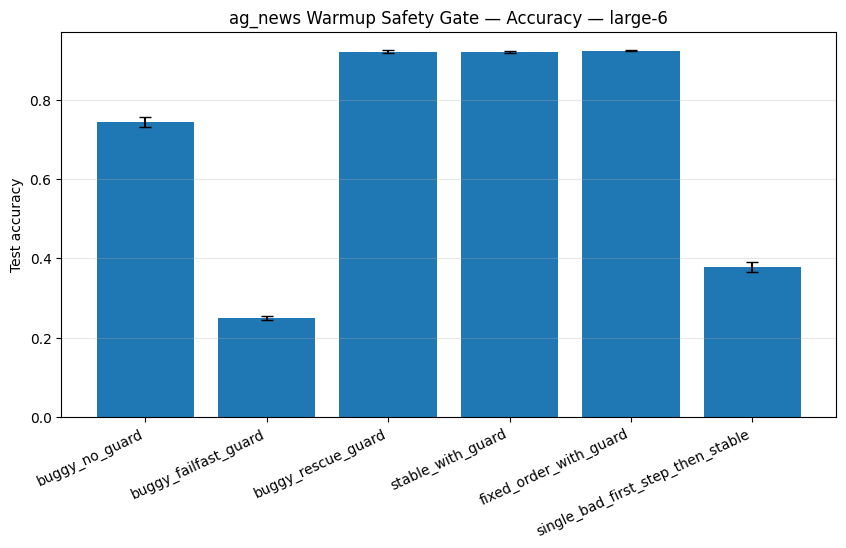

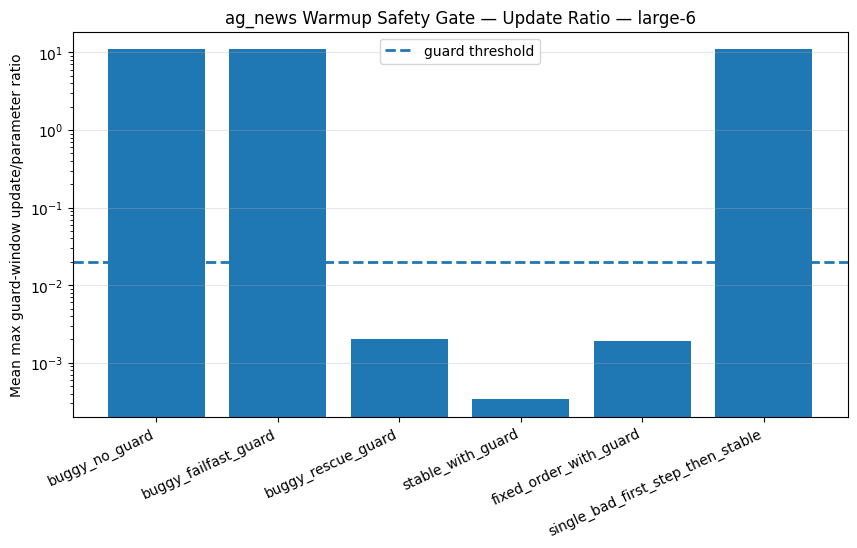

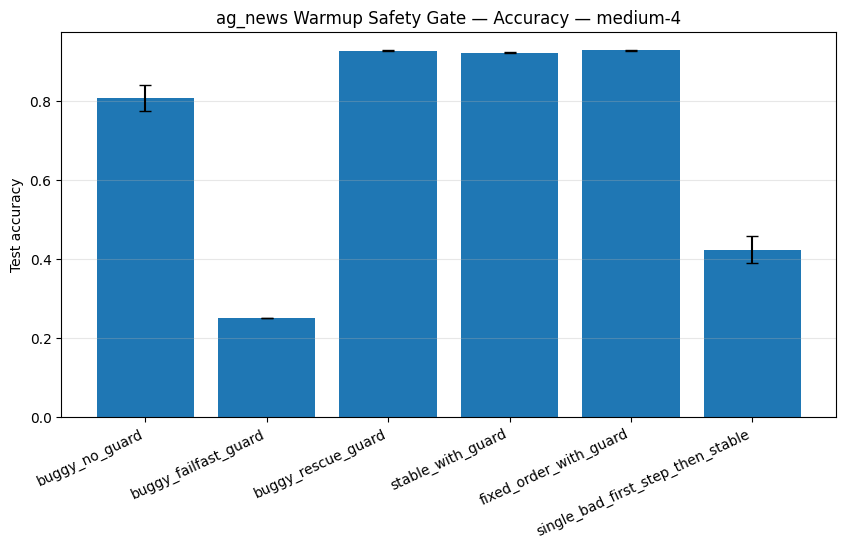

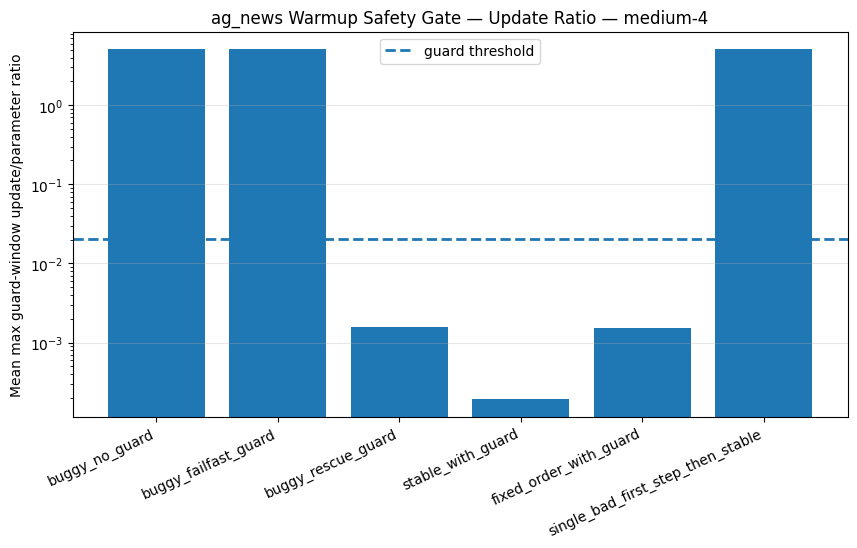

Created: /content/ag_news_paper_ready_tables.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import json
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import files

# ============================================================
# AUTO-FIND WARMUP SAFETY GATE ROOT
# ============================================================

def load_json(path):
    with open(path, "r") as f:
        return json.load(f)

candidate_roots = []

for p in BASE_DIR.rglob("run_manifest.json"):
    root = p.parent
    try:
        m = load_json(p)
        dataset = str(m.get("dataset_name", "")).lower()
        run_tag = str(m.get("run_tag", "")).lower()

        if dataset == DATASET_NAME.lower() and "warmup_safety_gate" in run_tag:
            candidate_roots.append(root)
    except Exception:
        pass

if not candidate_roots:
    raise FileNotFoundError(f"No Warmup Safety Gate root found for {DATASET_NAME}")

GUARD_ROOT = candidate_roots[0]

print("Using GUARD_ROOT:")
print(GUARD_ROOT)

OUT_DIR = Path(f"/content/{DATASET_NAME}_paper_ready_tables")
OUT_DIR.mkdir(parents=True, exist_ok=True)

def save_table(df, filename):
    path = OUT_DIR / filename
    df.to_csv(path, index=False)
    print("Saved:", path)

# ============================================================
# LOAD MAIN FILES
# ============================================================

manifest = load_json(GUARD_ROOT / "run_manifest.json")
summary = load_json(GUARD_ROOT / "warmup_safety_gate_summary.json")
per_seed_df = pd.read_csv(GUARD_ROOT / "warmup_safety_gate_per_seed.csv")
calibration_df = pd.read_csv(GUARD_ROOT / "threshold_calibration_safe_runs.csv")
calibration_record = load_json(GUARD_ROOT / "threshold_calibration_record.json")

print("\nMANIFEST")
display(pd.DataFrame([manifest]))

print("\nPER-SEED")
display(per_seed_df.head())

# ============================================================
# FIX METRIC COLUMN NAMES ROBUSTLY
# ============================================================

def add_alias_column(df, target_col, possible_cols):
    if target_col in df.columns:
        return df

    for c in possible_cols:
        if c in df.columns:
            df[target_col] = df[c]
            return df

    df[target_col] = np.nan
    return df

per_seed_df = add_alias_column(per_seed_df, "ece", ["ece", "test_ece", "eval_ece"])
per_seed_df = add_alias_column(per_seed_df, "nll", ["nll", "test_nll", "eval_nll"])
per_seed_df = add_alias_column(per_seed_df, "brier", ["brier", "test_brier", "eval_brier"])
per_seed_df = add_alias_column(per_seed_df, "test_acc", ["test_acc", "accuracy", "acc"])
per_seed_df = add_alias_column(per_seed_df, "generalization_gap_01", ["generalization_gap_01", "gap", "generalization_gap"])

# ============================================================
# 1. MANIFEST / AUDIT TABLE
# ============================================================

audit_keys = [
    "dataset_name",
    "run_tag",
    "run_mode",
    "models",
    "conditions",
    "calibration_conditions",
    "post_calibration_conditions",
    "seeds",
    "train_fraction",
    "base_lr",
    "legacy_initial_lr",
    "warmup_steps",
    "total_steps",
    "guard_window_steps",
    "diagnostic_steps",
    "threshold",
    "threshold_source",
    "threshold_multiplier",
    "safe_max_update_ratio",
    "threshold_calibration_conditions",
    "threshold_calibration_rule",
    "max_length",
    "batch_size",
    "num_epochs",
    "device",
]

audit_df = pd.DataFrame([
    {"field": k, "value": manifest.get(k, None)}
    for k in audit_keys
])

display(audit_df)
save_table(audit_df, f"{DATASET_NAME}_manifest_audit_table.csv")

# ============================================================
# 2. SUMMARY TABLE
# ============================================================

summary_rows = []

for row in summary:
    summary_rows.append({
        "model_name": row.get("model_name"),
        "condition": row.get("condition"),
        "num_parameters": row.get("num_parameters"),
        "threshold": row.get("threshold"),
        "threshold_source": row.get("threshold_source"),
        "threshold_multiplier": row.get("threshold_multiplier"),
        "threshold_calibration_conditions": row.get("threshold_calibration_conditions"),
        "guard_trigger_rate": row.get("guard_trigger_rate"),
        "stopped_rate": row.get("stopped_rate"),
        "rescued_rate": row.get("rescued_rate"),
        "first_guard_trigger_step_mean": row.get("first_guard_trigger_step_mean"),
        "max_guard_window_ratio_mean": row.get("max_early_update_ratio_mean"),
        "test_acc_mean": row.get("test_acc_stats", {}).get("mean"),
        "test_acc_std": row.get("test_acc_stats", {}).get("std"),
        "test_acc_ci95_low": row.get("test_acc_stats", {}).get("ci95_low"),
        "test_acc_ci95_high": row.get("test_acc_stats", {}).get("ci95_high"),
        "ece_mean": row.get("ece_stats", {}).get("mean"),
        "nll_mean": row.get("nll_stats", {}).get("mean"),
        "brier_mean": row.get("brier_stats", {}).get("mean"),
        "gap_mean": row.get("gap_stats", {}).get("mean"),
    })

summary_df = pd.DataFrame(summary_rows)

condition_order = [
    "buggy_no_guard",
    "buggy_failfast_guard",
    "buggy_rescue_guard",
    "stable_with_guard",
    "fixed_order_with_guard",
    "single_bad_first_step_then_stable",
]

summary_df["condition"] = pd.Categorical(
    summary_df["condition"],
    categories=condition_order,
    ordered=True,
)

summary_df = summary_df.sort_values(["model_name", "condition"]).reset_index(drop=True)

display(summary_df)
save_table(summary_df, f"{DATASET_NAME}_warmup_safety_gate_summary_table.csv")

# ============================================================
# 3. RENAMED UPDATE-RATIO TABLE
# ============================================================

ratio_df = per_seed_df.copy()

if "max_early_update_ratio" not in ratio_df.columns:
    raise KeyError("max_early_update_ratio column is missing from per_seed_df")

ratio_df["max_guard_window_ratio"] = ratio_df["max_early_update_ratio"]

ratio_df["first_step_update_ratio"] = np.where(
    ratio_df["condition"].isin([
        "buggy_no_guard",
        "buggy_failfast_guard",
        "single_bad_first_step_then_stable",
    ]),
    ratio_df["max_early_update_ratio"],
    np.nan
)

ratio_df["max_training_ratio"] = np.nan

needed_cols = [
    "dataset_name",
    "model_name",
    "condition",
    "seed",
    "threshold",
    "threshold_source",
    "first_guard_trigger_step",
    "first_step_update_ratio",
    "max_guard_window_ratio",
    "max_training_ratio",
    "guard_trigger_count",
    "stopped_by_guard",
    "rescued_once",
    "test_acc",
    "ece",
    "nll",
    "brier",
    "generalization_gap_01",
]

for c in needed_cols:
    if c not in ratio_df.columns:
        ratio_df[c] = np.nan

ratio_table = ratio_df[needed_cols].copy()

display(ratio_table)
save_table(ratio_table, f"{DATASET_NAME}_renamed_update_ratio_table.csv")

# ============================================================
# 4. CANONICAL SCHEDULER TRACE TABLE — FIRST TWO STEPS
# ============================================================

def flatten_trace_json(obj):
    if isinstance(obj, list):
        return obj

    if isinstance(obj, dict):
        for key in ["trace", "scheduler_trace", "steps", "records", "history"]:
            if key in obj and isinstance(obj[key], list):
                return obj[key]

        return [obj]

    return []

trace_rows = []

for _, row in per_seed_df.iterrows():
    trace_file = row.get("scheduler_trace_file", None)

    if pd.isna(trace_file):
        continue

    trace_path = GUARD_ROOT / str(trace_file)

    if not trace_path.exists():
        continue

    trace_obj = load_json(trace_path)
    trace_records = flatten_trace_json(trace_obj)

    for rec in trace_records[:2]:
        if not isinstance(rec, dict):
            continue

        trace_rows.append({
            "dataset_name": DATASET_NAME,
            "model_name": row.get("model_name"),
            "condition": row.get("condition"),
            "seed": row.get("seed"),
            "step": rec.get("step", rec.get("global_step", rec.get("t", None))),
            "lr_before_step": rec.get("lr_before_step", rec.get("lr_before", None)),
            "lr_used": rec.get("lr_used", rec.get("actual_lr_used", rec.get("optimizer_lr", None))),
            "lr_after_step": rec.get("lr_after_step", rec.get("lr_after", None)),
            "scheduler_step_called": rec.get("scheduler_step_called", None),
            "optimizer_step_called": rec.get("optimizer_step_called", None),
            "note": (
                "single_bad condition uses unsafe first step, then switches to stable schedule from step 2"
                if row.get("condition") == "single_bad_first_step_then_stable" else ""
            ),
        })

scheduler_trace_table = pd.DataFrame(trace_rows)

display(scheduler_trace_table)
save_table(scheduler_trace_table, f"{DATASET_NAME}_canonical_scheduler_first_two_steps.csv")

# ============================================================
# 5. PAIRED DELTAS — NO P-VALUES
# ============================================================

paired_df = ratio_df.copy()

metrics = [
    "test_acc",
    "ece",
    "nll",
    "brier",
    "generalization_gap_01",
]

pairs = [
    ("fixed_order_with_guard", "stable_with_guard"),
    ("buggy_no_guard", "fixed_order_with_guard"),
    ("buggy_rescue_guard", "fixed_order_with_guard"),
    ("single_bad_first_step_then_stable", "stable_with_guard"),
    ("buggy_rescue_guard", "buggy_no_guard"),
]

delta_rows = []

for model_name in sorted(paired_df["model_name"].dropna().unique()):
    model_df = paired_df[paired_df["model_name"] == model_name]

    for cond_a, cond_b in pairs:
        a = model_df[model_df["condition"] == cond_a].set_index("seed")
        b = model_df[model_df["condition"] == cond_b].set_index("seed")

        common_seeds = sorted(set(a.index).intersection(set(b.index)))

        for metric in metrics:
            values = []

            for seed in common_seeds:
                values.append(a.loc[seed, metric] - b.loc[seed, metric])

            if len(values) == 0:
                continue

            values = np.array(values, dtype=float)

            mean = float(np.nanmean(values))
            std = float(np.nanstd(values, ddof=1)) if len(values) > 1 else 0.0
            ci = 1.96 * std / np.sqrt(len(values)) if len(values) > 1 else 0.0

            delta_rows.append({
                "dataset_name": DATASET_NAME,
                "model_name": model_name,
                "comparison": f"{cond_a} minus {cond_b}",
                "metric": metric,
                "n_seeds": len(values),
                "mean_delta": mean,
                "std_delta": std,
                "descriptive_ci95_low": mean - ci,
                "descriptive_ci95_high": mean + ci,
                "seed_level_deltas": values.tolist(),
            })

paired_delta_df = pd.DataFrame(delta_rows)

display(paired_delta_df)
save_table(paired_delta_df, f"{DATASET_NAME}_paired_seed_deltas_no_pvalues.csv")

# ============================================================
# 6. GUARD SEMANTICS TABLE
# ============================================================

guard_semantics = pd.DataFrame([
    {
        "condition": "stable_with_guard",
        "meaning": "Safe calibration/run condition. Used to estimate safe update-ratio envelope.",
        "post_threshold_guarded_deployment": "No; calibration safe run, not a failure intervention.",
    },
    {
        "condition": "fixed_order_with_guard",
        "meaning": "Corrected scheduler-order condition. Used with stable condition for threshold calibration.",
        "post_threshold_guarded_deployment": "No; calibration safe run, not a failure intervention.",
    },
    {
        "condition": "buggy_no_guard",
        "meaning": "Legacy buggy warmup with unsafe first optimizer step and no protection.",
        "post_threshold_guarded_deployment": "No.",
    },
    {
        "condition": "buggy_failfast_guard",
        "meaning": "Detector condition. Stops when unsafe update-ratio violation is detected.",
        "post_threshold_guarded_deployment": "Detects and stops; not a trained final model.",
    },
    {
        "condition": "buggy_rescue_guard",
        "meaning": "Intervention condition. Detects unsafe first update and rescues by replacing unsafe step behavior.",
        "post_threshold_guarded_deployment": "Yes; this is the trained rescue intervention.",
    },
    {
        "condition": "single_bad_first_step_then_stable",
        "meaning": "Causal ablation. Applies one unsafe first step, then switches to stable schedule from step 2.",
        "post_threshold_guarded_deployment": "No; demonstrates sufficiency of one bad update.",
    },
])

display(guard_semantics)
save_table(guard_semantics, f"{DATASET_NAME}_guard_semantics_table.csv")

# ============================================================
# 7. SIMPLE PLOTS FOR PAPER CHECK
# ============================================================

for model_name in sorted(summary_df["model_name"].dropna().unique()):
    sub = summary_df[summary_df["model_name"] == model_name].copy()

    plt.figure(figsize=(10, 5))
    plt.bar(
        sub["condition"].astype(str),
        sub["test_acc_mean"],
        yerr=sub["test_acc_std"],
        capsize=4,
    )
    plt.xticks(rotation=25, ha="right")
    plt.ylabel("Test accuracy")
    plt.title(f"{DATASET_NAME} Warmup Safety Gate — Accuracy — {model_name}")
    plt.grid(axis="y", alpha=0.3)
    plt.savefig(OUT_DIR / f"{DATASET_NAME}_accuracy_{model_name}.png", dpi=150, bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(10, 5))
    plt.bar(
        sub["condition"].astype(str),
        sub["max_guard_window_ratio_mean"],
    )
    plt.axhline(
        float(manifest["threshold"]),
        linestyle="--",
        linewidth=2,
        label="guard threshold",
    )
    plt.yscale("log")
    plt.xticks(rotation=25, ha="right")
    plt.ylabel("Mean max guard-window update/parameter ratio")
    plt.title(f"{DATASET_NAME} Warmup Safety Gate — Update Ratio — {model_name}")
    plt.grid(axis="y", alpha=0.3)
    plt.legend()
    plt.savefig(OUT_DIR / f"{DATASET_NAME}_update_ratio_{model_name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# ============================================================
# 8. ZIP OUTPUTS
# ============================================================

zip_path = Path(f"/content/{DATASET_NAME}_paper_ready_tables.zip")

if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in OUT_DIR.rglob("*"):
        if p.is_file():
            zf.write(p, arcname=str(p.relative_to(OUT_DIR)))

print("Created:", zip_path)
files.download(str(zip_path))

### extra analysis

TOY ADAM FIRST-STEP SIMULATION


,dataset_context,dim,lr,theta_norm,grad_norm,update_norm,update_parameter_ratio,mean_abs_update,mean_abs_parameter
0,ag_news,1000,1.0000,0.62559,0.03217,31.619900,50.544138,0.999909,0.015639
1,ag_news,1000,0.3000,0.62559,0.03217,9.485970,15.163241,0.299973,0.015639
2,ag_news,1000,0.1000,0.62559,0.03217,3.161990,5.054414,0.099991,0.015639
3,ag_news,1000,0.0300,0.62559,0.03217,0.948597,1.516324,0.029997,0.015639
4,ag_news,1000,0.0100,0.62559,0.03217,0.316199,0.505441,0.009999,0.015639
5,ag_news,1000,0.0001,0.62559,0.03217,0.003162,0.005054,0.000100,0.015639


Saved: /content/ag_news_extra_paper_support/ag_news_toy_adam_first_step_simulation.csv
Saved: /content/ag_news_extra_paper_support/ag_news_toy_adam_first_step_update_ratio.png


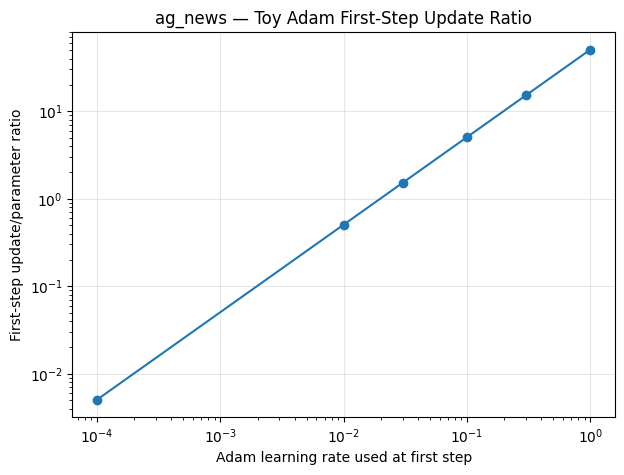


PRETRAINED / BASELINE CANDIDATE FILES
/content/paper_inputs/results_agnewa-no_ckp/results_agnewa-no_ckp/scratch_empirical_ag_news_full_agnews_v1/baseline_results.json

PRETRAINED / BASELINE SUMMARY


,dataset_context,file,file_type,num_records
0,ag_news,/content/paper_inputs/results_agnewa-no_ckp/re...,json,2


Saved: /content/ag_news_extra_paper_support/ag_news_pretrained_baseline_scan_summary.csv

REPRESENTATION / COSINE DRIFT FILE SCAN


,dataset_context,candidate_file,suffix
0,ag_news,None,None


Saved: /content/ag_news_extra_paper_support/ag_news_representation_cosine_drift_scan.csv
Created: /content/ag_news_extra_paper_support.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
import json
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import files

DATASET_NAME = "ag_news"   # use "dbpedia_14" in DBPedia notebook

BASE_DIR = Path("/content/paper_inputs")
OUT_DIR = Path(f"/content/{DATASET_NAME}_extra_paper_support")
OUT_DIR.mkdir(parents=True, exist_ok=True)

def save_table(df, filename):
    path = OUT_DIR / filename
    df.to_csv(path, index=False)
    print("Saved:", path)

def save_plot(filename):
    path = OUT_DIR / filename
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved:", path)

def load_json_safe(path):
    try:
        with open(path, "r") as f:
            return json.load(f)
    except Exception:
        return None

def adam_first_step(theta, grad, lr, beta1=0.9, beta2=0.999, eps=1e-8):
    m = (1 - beta1) * grad
    v = (1 - beta2) * (grad ** 2)

    m_hat = m / (1 - beta1)
    v_hat = v / (1 - beta2)

    update = lr * m_hat / (np.sqrt(v_hat) + eps)
    theta_new = theta - update

    update_norm = np.linalg.norm(update)
    theta_norm = np.linalg.norm(theta)
    update_ratio = update_norm / (theta_norm + eps)

    return theta_new, update, update_ratio

rng = np.random.default_rng(42)

dim = 1000
theta = rng.normal(loc=0.0, scale=0.02, size=dim)
grad = rng.normal(loc=0.0, scale=0.001, size=dim)

lr_values = [1.0, 0.3, 0.1, 0.03, 0.01, 1e-4]
toy_rows = []

for lr in lr_values:
    theta_new, update, update_ratio = adam_first_step(theta, grad, lr)

    toy_rows.append({
        "dataset_context": DATASET_NAME,
        "dim": dim,
        "lr": lr,
        "theta_norm": float(np.linalg.norm(theta)),
        "grad_norm": float(np.linalg.norm(grad)),
        "update_norm": float(np.linalg.norm(update)),
        "update_parameter_ratio": float(update_ratio),
        "mean_abs_update": float(np.mean(np.abs(update))),
        "mean_abs_parameter": float(np.mean(np.abs(theta))),
    })

toy_df = pd.DataFrame(toy_rows)

print("TOY ADAM FIRST-STEP SIMULATION")
display(toy_df)

save_table(toy_df, f"{DATASET_NAME}_toy_adam_first_step_simulation.csv")

plt.figure(figsize=(7, 5))
plt.plot(toy_df["lr"], toy_df["update_parameter_ratio"], marker="o")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Adam learning rate used at first step")
plt.ylabel("First-step update/parameter ratio")
plt.title(f"{DATASET_NAME} — Toy Adam First-Step Update Ratio")
plt.grid(True, alpha=0.3)
save_plot(f"{DATASET_NAME}_toy_adam_first_step_update_ratio.png")
plt.show()

pretrained_candidates = []

for p in BASE_DIR.rglob("*"):
    if p.is_file() and p.suffix.lower() in [".csv", ".json"]:
        text = str(p).lower()
        if any(k in text for k in ["pretrained", "bert", "roberta", "baseline"]):
            pretrained_candidates.append(p)

print("\nPRETRAINED / BASELINE CANDIDATE FILES")
for p in pretrained_candidates:
    print(p)

pretrained_summary_rows = []

for p in pretrained_candidates:
    try:
        if p.suffix.lower() == ".csv":
            df = pd.read_csv(p)
            numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

            row = {
                "dataset_context": DATASET_NAME,
                "file": str(p),
                "file_type": "csv",
                "num_rows": len(df),
                "columns": list(df.columns),
            }

            for col in numeric_cols:
                if any(k in col.lower() for k in ["acc", "accuracy", "ece", "nll", "brier", "f1", "loss"]):
                    row[f"{col}_mean"] = float(df[col].mean())
                    row[f"{col}_std"] = float(df[col].std(ddof=1)) if len(df) > 1 else 0.0

            pretrained_summary_rows.append(row)

        elif p.suffix.lower() == ".json":
            obj = load_json_safe(p)

            row = {
                "dataset_context": DATASET_NAME,
                "file": str(p),
                "file_type": "json",
            }

            if isinstance(obj, dict):
                row["top_level_keys"] = list(obj.keys())

                for k, v in obj.items():
                    if isinstance(v, (int, float)) and any(x in k.lower() for x in ["acc", "accuracy", "ece", "nll", "brier", "f1", "loss"]):
                        row[k] = v

            elif isinstance(obj, list):
                row["num_records"] = len(obj)

            pretrained_summary_rows.append(row)

    except Exception as e:
        pretrained_summary_rows.append({
            "dataset_context": DATASET_NAME,
            "file": str(p),
            "error": str(e),
        })

pretrained_summary_df = pd.DataFrame(pretrained_summary_rows)

print("\nPRETRAINED / BASELINE SUMMARY")
display(pretrained_summary_df)

save_table(pretrained_summary_df, f"{DATASET_NAME}_pretrained_baseline_scan_summary.csv")

drift_candidates = []

for p in BASE_DIR.rglob("*"):
    if p.is_file() and p.suffix.lower() in [".csv", ".json", ".npy", ".npz", ".pt", ".pth"]:
        text = str(p).lower()
        if any(k in text for k in ["drift", "cosine", "representation", "hidden", "embedding"]):
            drift_candidates.append(p)

drift_scan_rows = []

for p in drift_candidates:
    drift_scan_rows.append({
        "dataset_context": DATASET_NAME,
        "candidate_file": str(p),
        "suffix": p.suffix,
    })

if len(drift_scan_rows) == 0:
    drift_scan_rows.append({
        "dataset_context": DATASET_NAME,
        "candidate_file": None,
        "suffix": None,
    })

drift_scan_df = pd.DataFrame(drift_scan_rows)

print("\nREPRESENTATION / COSINE DRIFT FILE SCAN")
display(drift_scan_df)

save_table(drift_scan_df, f"{DATASET_NAME}_representation_cosine_drift_scan.csv")

zip_path = Path(f"/content/{DATASET_NAME}_extra_paper_support.zip")

if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in OUT_DIR.rglob("*"):
        if p.is_file():
            zf.write(p, arcname=str(p.relative_to(OUT_DIR)))

print("Created:", zip_path)
files.download(str(zip_path))

### paired seed plots + guard-event LR documentation

Using GUARD_ROOT: /content/paper_inputs/Lubem1/Lubem/final_agnews_warmup_safety_gate_calibrated_package/transformer_project/results/warmup_safety_gate_ag_news_agnews_warmup_safety_gate_v2_calibrated
Saved: /content/ag_news_final_paper_support/ag_news_large-6_test_acc_paired_seed_trajectories.png


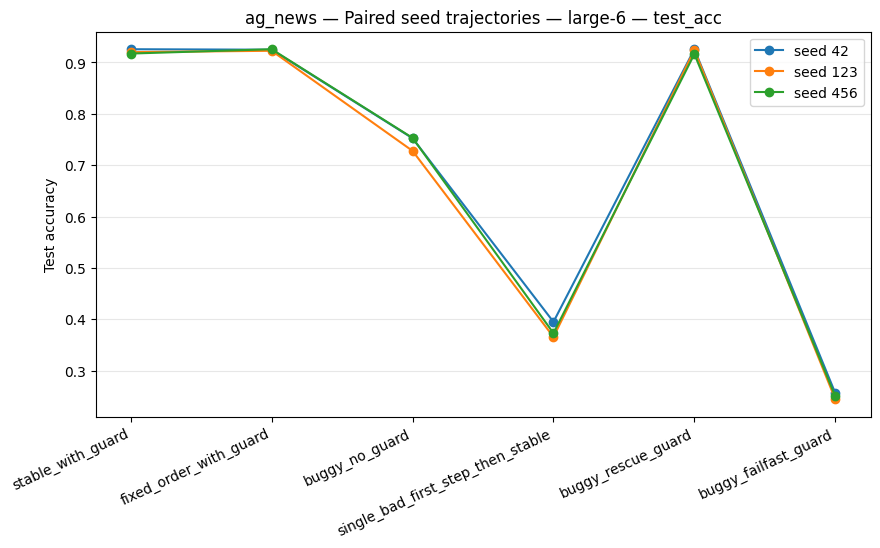

Saved: /content/ag_news_final_paper_support/ag_news_large-6_nll_paired_seed_trajectories.png


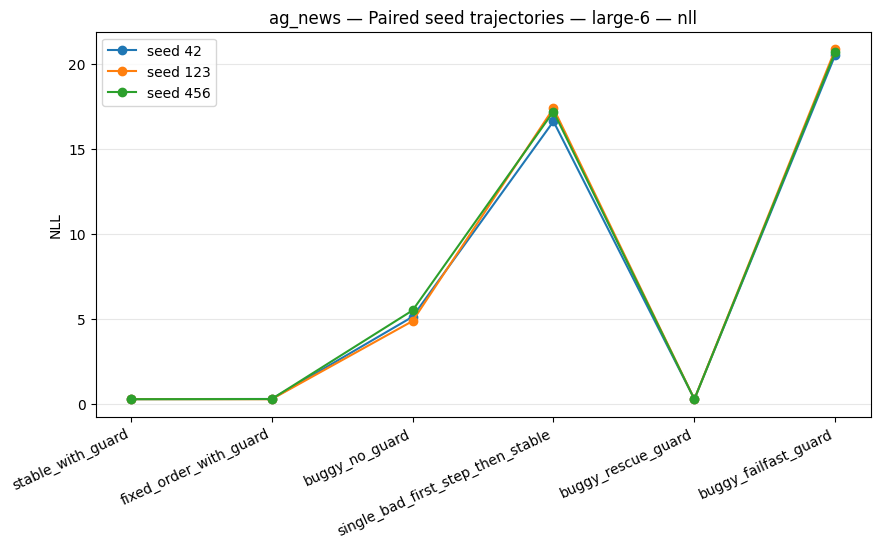

Saved: /content/ag_news_final_paper_support/ag_news_large-6_ece_paired_seed_trajectories.png


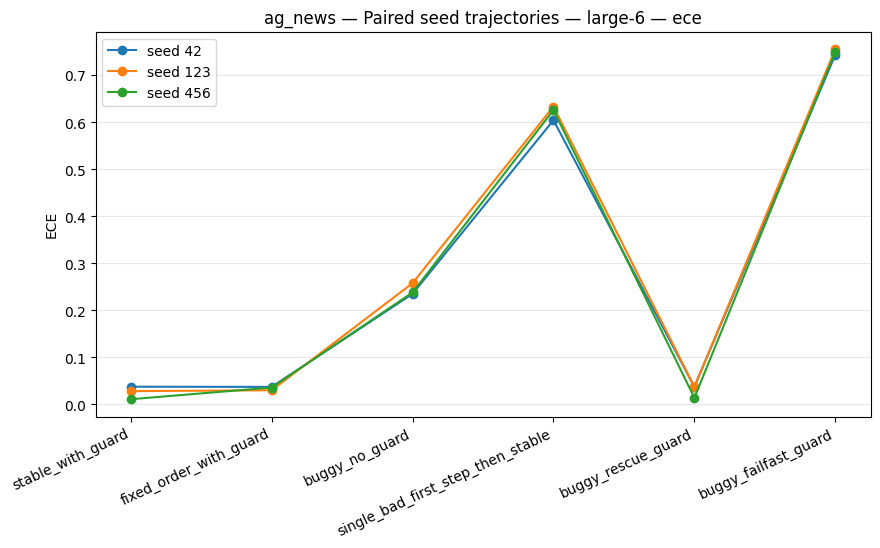

Saved: /content/ag_news_final_paper_support/ag_news_large-6_brier_paired_seed_trajectories.png


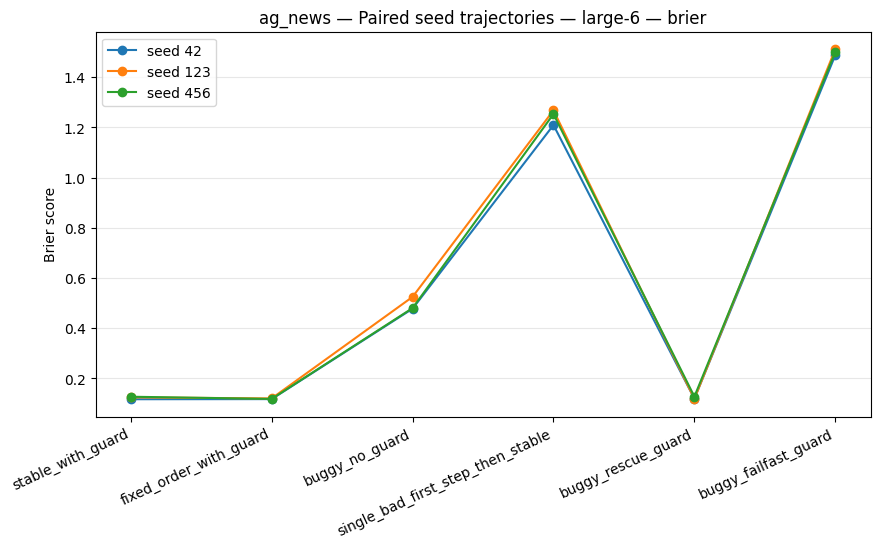

Saved: /content/ag_news_final_paper_support/ag_news_medium-4_test_acc_paired_seed_trajectories.png


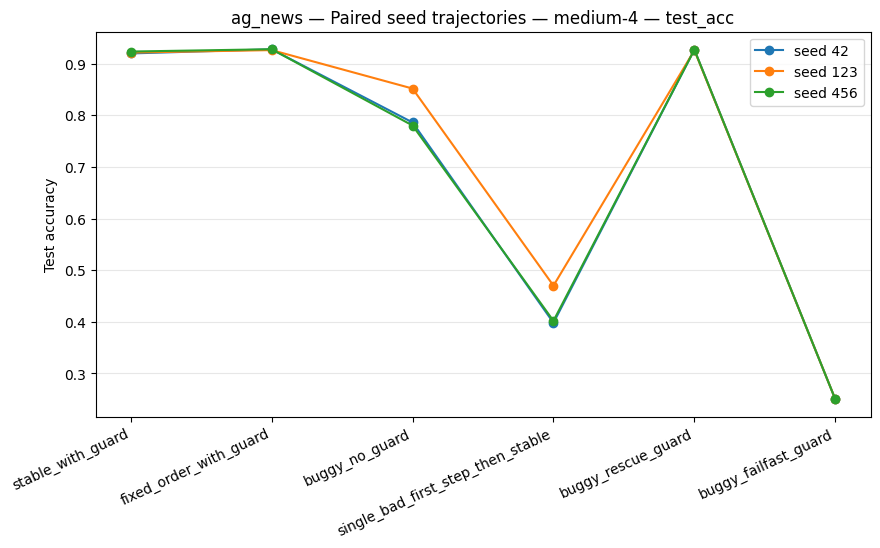

Saved: /content/ag_news_final_paper_support/ag_news_medium-4_nll_paired_seed_trajectories.png


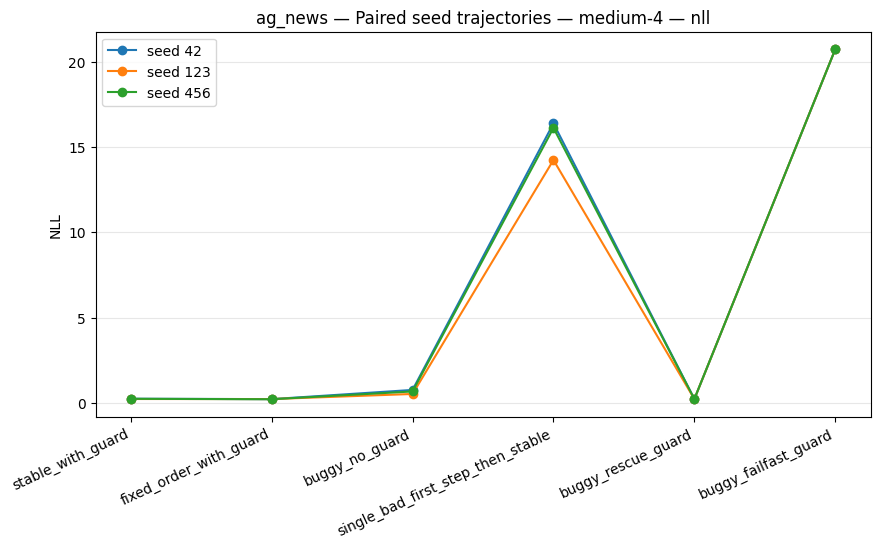

Saved: /content/ag_news_final_paper_support/ag_news_medium-4_ece_paired_seed_trajectories.png


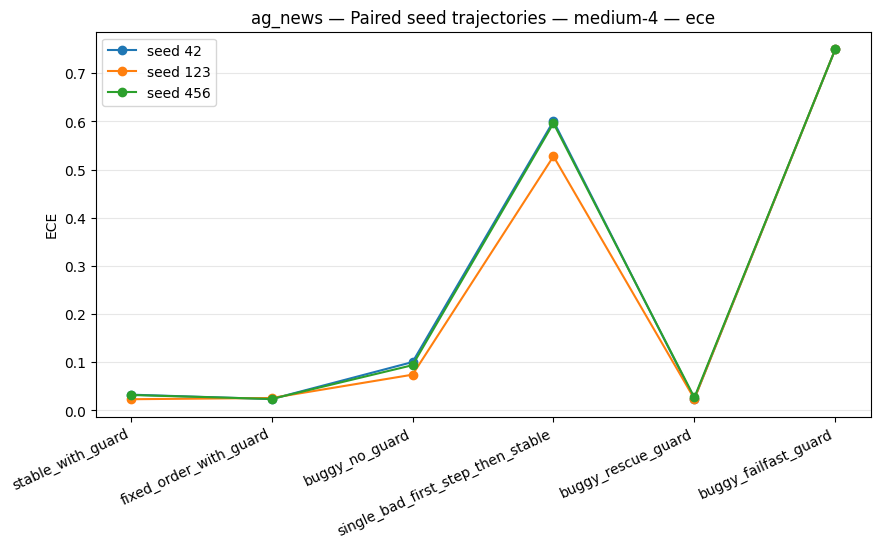

Saved: /content/ag_news_final_paper_support/ag_news_medium-4_brier_paired_seed_trajectories.png


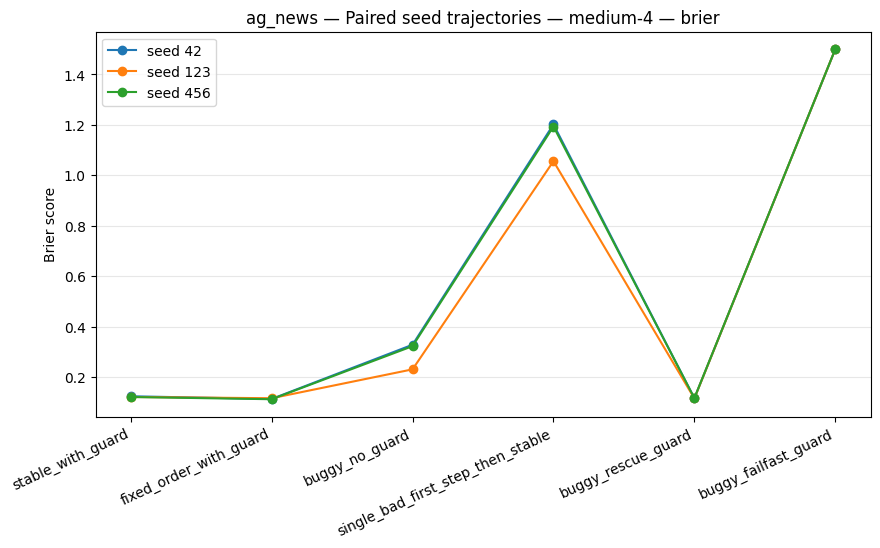

,condition,unsafe_lr_used_step1,rescue_lr_used_step1,guard_action,paper_note
0,buggy_no_guard,1.0,NaN,none,The unsafe optimizer update is applied at step 1.
1,buggy_failfast_guard,1.0,NaN,detect_and_stop,The guard detects the unsafe update-ratio viol...
2,buggy_rescue_guard,1.0,1.250000e-08,detect_and_rescue,The guard detects the unsafe step-1 condition ...
3,single_bad_first_step_then_stable,1.0,NaN,none,Step 1 intentionally uses lr=1.0; from step 2 ...
4,stable_with_guard,NaN,1.250000e-08,calibration_safe_run,Used to calibrate the safe update-ratio envelo...
5,fixed_order_with_guard,NaN,1.250000e-08,calibration_safe_run,Used together with stable runs to calibrate th...


Saved: /content/ag_news_final_paper_support/ag_news_guard_lr_documentation_table.csv
Created: /content/ag_news_final_paper_support.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import json
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import files

# ============================================================
# SETTINGS
# ============================================================

DATASET_NAME = "ag_news"   # change to "dbpedia_14" in DBPedia notebook

BASE_DIR = Path("/content/paper_inputs")
OUT_DIR = Path(f"/content/{DATASET_NAME}_final_paper_support")
OUT_DIR.mkdir(parents=True, exist_ok=True)

def load_json(path):
    with open(path, "r") as f:
        return json.load(f)

def save_table(df, filename):
    path = OUT_DIR / filename
    df.to_csv(path, index=False)
    print("Saved:", path)

def save_plot(filename):
    path = OUT_DIR / filename
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved:", path)

# ============================================================
# FIND WARMUP SAFETY GATE ROOT
# ============================================================

candidate_roots = []

for p in BASE_DIR.rglob("run_manifest.json"):
    root = p.parent
    try:
        m = load_json(p)
        dataset = str(m.get("dataset_name", "")).lower()
        run_tag = str(m.get("run_tag", "")).lower()

        if dataset == DATASET_NAME.lower() and "warmup_safety_gate" in run_tag:
            candidate_roots.append(root)
    except Exception:
        pass

if not candidate_roots:
    raise FileNotFoundError(f"No Warmup Safety Gate root found for {DATASET_NAME}")

GUARD_ROOT = candidate_roots[0]
print("Using GUARD_ROOT:", GUARD_ROOT)

manifest = load_json(GUARD_ROOT / "run_manifest.json")
per_seed_df = pd.read_csv(GUARD_ROOT / "warmup_safety_gate_per_seed.csv")

# ============================================================
# NORMALIZE METRIC NAMES
# ============================================================

def add_alias_column(df, target_col, possible_cols):
    if target_col in df.columns:
        return df
    for c in possible_cols:
        if c in df.columns:
            df[target_col] = df[c]
            return df
    df[target_col] = np.nan
    return df

per_seed_df = add_alias_column(per_seed_df, "ece", ["ece", "test_ece", "eval_ece"])
per_seed_df = add_alias_column(per_seed_df, "nll", ["nll", "test_nll", "eval_nll"])
per_seed_df = add_alias_column(per_seed_df, "brier", ["brier", "test_brier", "eval_brier"])
per_seed_df = add_alias_column(per_seed_df, "test_acc", ["test_acc", "accuracy", "acc"])

condition_order = [
    "stable_with_guard",
    "fixed_order_with_guard",
    "buggy_no_guard",
    "single_bad_first_step_then_stable",
    "buggy_rescue_guard",
    "buggy_failfast_guard",
]

plot_metrics = {
    "test_acc": "Test accuracy",
    "nll": "NLL",
    "ece": "ECE",
    "brier": "Brier score",
}

# ============================================================
# PAIRED SEED TRAJECTORY PLOTS
# ============================================================

for model_name in sorted(per_seed_df["model_name"].dropna().unique()):
    model_df = per_seed_df[per_seed_df["model_name"] == model_name].copy()

    for metric, ylabel in plot_metrics.items():
        if metric not in model_df.columns:
            continue

        plt.figure(figsize=(10, 5))

        for seed in sorted(model_df["seed"].dropna().unique()):
            seed_df = model_df[model_df["seed"] == seed].copy()
            seed_df["condition"] = pd.Categorical(
                seed_df["condition"],
                categories=condition_order,
                ordered=True
            )
            seed_df = seed_df.sort_values("condition")

            plt.plot(
                seed_df["condition"].astype(str),
                seed_df[metric],
                marker="o",
                label=f"seed {seed}"
            )

        plt.xticks(rotation=25, ha="right")
        plt.ylabel(ylabel)
        plt.title(f"{DATASET_NAME} — Paired seed trajectories — {model_name} — {metric}")
        plt.grid(axis="y", alpha=0.3)
        plt.legend()
        save_plot(f"{DATASET_NAME}_{model_name}_{metric}_paired_seed_trajectories.png")
        plt.show()

# ============================================================
# GUARD EVENT LR DOCUMENTATION TABLE
# ============================================================

base_lr = float(manifest.get("base_lr", 1e-4))
warmup_steps = int(manifest.get("warmup_steps", 8000))
legacy_initial_lr = float(manifest.get("legacy_initial_lr", 1.0))

stable_step1_lr = base_lr / warmup_steps
stable_step2_lr = 2 * base_lr / warmup_steps

guard_lr_doc = pd.DataFrame([
    {
        "condition": "buggy_no_guard",
        "unsafe_lr_used_step1": legacy_initial_lr,
        "rescue_lr_used_step1": np.nan,
        "guard_action": "none",
        "paper_note": "The unsafe optimizer update is applied at step 1.",
    },
    {
        "condition": "buggy_failfast_guard",
        "unsafe_lr_used_step1": legacy_initial_lr,
        "rescue_lr_used_step1": np.nan,
        "guard_action": "detect_and_stop",
        "paper_note": "The guard detects the unsafe update-ratio violation at step 1 and stops; this is not a trained model.",
    },
    {
        "condition": "buggy_rescue_guard",
        "unsafe_lr_used_step1": legacy_initial_lr,
        "rescue_lr_used_step1": stable_step1_lr,
        "guard_action": "detect_and_rescue",
        "paper_note": "The guard detects the unsafe step-1 condition and applies the safe warmup-scale update instead.",
    },
    {
        "condition": "single_bad_first_step_then_stable",
        "unsafe_lr_used_step1": legacy_initial_lr,
        "rescue_lr_used_step1": np.nan,
        "guard_action": "none",
        "paper_note": "Step 1 intentionally uses lr=1.0; from step 2 onward the run follows the stable schedule. The step-2 trace may retain lr_before_step=1.0, but lr_used is the stable warmup value.",
    },
    {
        "condition": "stable_with_guard",
        "unsafe_lr_used_step1": np.nan,
        "rescue_lr_used_step1": stable_step1_lr,
        "guard_action": "calibration_safe_run",
        "paper_note": "Used to calibrate the safe update-ratio envelope; not a post-threshold guarded deployment.",
    },
    {
        "condition": "fixed_order_with_guard",
        "unsafe_lr_used_step1": np.nan,
        "rescue_lr_used_step1": stable_step1_lr,
        "guard_action": "calibration_safe_run",
        "paper_note": "Used together with stable runs to calibrate the safe update-ratio envelope.",
    },
])

display(guard_lr_doc)
save_table(guard_lr_doc, f"{DATASET_NAME}_guard_lr_documentation_table.csv")

# ============================================================
# ZIP OUTPUT
# ============================================================

zip_path = Path(f"/content/{DATASET_NAME}_final_paper_support.zip")

if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in OUT_DIR.rglob("*"):
        if p.is_file():
            zf.write(p, arcname=str(p.relative_to(OUT_DIR)))

print("Created:", zip_path)
files.download(str(zip_path))